In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!git clone https://github.com/AadityaRaj77/LEONARDO.git
%cd LEONARDO
!ls

Cloning into 'LEONARDO'...
remote: Enumerating objects: 159, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 159 (delta 17), reused 11 (delta 11), pack-reused 141 (from 1)
Receiving objects: 100% (159/159), 97.63 MiB | 6.21 MiB/s, done.
Resolving deltas: 100% (72/72), done.
/kaggle/working/LEONARDO
_config.yml			      LEONARDO_script.py  LICENSE
LEONARDO_introductory_notebook.ipynb  LEONARDO_utils.py   MoNet2.0
LEONARDO_model.py		      LEONARDO.yml	  README.md


In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [4]:
!pip install -q pytorch-forecasting

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.3/425.3 kB 9.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 4.7 MB/s eta 0:00:00


In [5]:
import numpy
import pandas
import scipy
import sklearn
import matplotlib
import seaborn
import torch
import pytorch_forecasting

print("All imports working")

All imports working


In [6]:
!wget -q https://huggingface.co/datasets/JamaliLab/LEONDARDO/resolve/main/datasets.zip -O datasets.zip
!unzip -o datasets.zip

Archive:  datasets.zip
  inflating: lptem_test.npy          
  inflating: lptem_val.npy           
  inflating: lptem_train.npy         


In [7]:
!find . -maxdepth 3 -type f | head -50

./LEONARDO_introductory_notebook.ipynb
./datasets.zip
./LICENSE
./LEONARDO_utils.py
./lptem_test.npy
./lptem_val.npy
./MoNet2.0/monet2_train.py
./MoNet2.0/LICENSE
./MoNet2.0/requirements.txt
./MoNet2.0/monet2.keras
./MoNet2.0/lptem_val.npy
./MoNet2.0/run_monet2_fd.py
./MoNet2.0/LEONARDO_generated.npy
./MoNet2.0/monet2_architecture.py
./MoNet2.0/README.md
./MoNet2.0/models_theory.py
./MoNet2.0/run_monet2_classification.py
./MoNet2.0/utils_monet2.py
./MoNet2.0/utils_trajectories.py
./.git/config
./.git/hooks/pre-merge-commit.sample
./.git/hooks/update.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/pre-push.sample
./.git/hooks/pre-commit.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/pre-receive.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/commit-msg.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/applypatch-msg.sample
./.git/hooks/post-update.sample
./.git/packed-refs
./.git/logs/HEAD
./.git/index
./.git/info/exclu

In [8]:
!find . -name "*.npy"

./lptem_test.npy
./lptem_val.npy
./MoNet2.0/lptem_val.npy
./MoNet2.0/LEONARDO_generated.npy
./lptem_train.npy


In [9]:
np.load('lptem_train.npy')
np.load('lptem_val.npy')

array([[[0.00000000e+00, 1.60570126e-01, 0.00000000e+00],
        [6.51218034e-02, 9.74566935e-02, 2.50000000e-01],
        [8.27286255e-02, 6.36196703e-02, 5.00000000e-01],
        ...,
        [5.93367566e-01, 2.40215063e-01, 4.92500000e+01],
        [5.82566180e-01, 1.97571251e-01, 4.95000000e+01],
        [6.21903851e-01, 1.62190993e-01, 4.97500000e+01]],

       [[7.44524021e-01, 2.43307146e-01, 2.50000000e+01],
        [7.15581241e-01, 2.40323269e-01, 2.52500000e+01],
        [7.44022213e-01, 2.44484738e-01, 2.55000000e+01],
        ...,
        [3.05107300e-01, 8.66055167e-01, 7.42500000e+01],
        [3.38085937e-01, 6.48827311e-01, 7.45000000e+01],
        [2.94583667e-01, 7.27367815e-01, 7.47500000e+01]],

       [[1.68400853e-01, 3.88844636e-01, 5.00000000e+01],
        [1.43328972e-01, 3.81869832e-01, 5.02500000e+01],
        [1.38996060e-01, 3.69501419e-01, 5.05000000e+01],
        ...,
        [9.77339825e-02, 3.25840997e-01, 9.92500000e+01],
        [9.18319547e-02, 2.54

In [10]:
import numpy as np

train = np.load("lptem_train.npy")
val = np.load("lptem_val.npy")

print("Train:", train.shape)
print("Validation:", val.shape)

Train: (38279, 200, 3)
Validation: (3202, 200, 3)


In [11]:
import numpy as np
import matplotlib.pyplot as plt

train = np.load("lptem_train.npy")

print("Shape:", train.shape)
print("First trajectory shape:", train[0].shape)
print("First trajectory:")
print(train[0])

Shape: (38279, 200, 3)
First trajectory shape: (200, 3)
First trajectory:
[[ 0.06443624  0.07186947  0.        ]
 [ 0.          0.19972712  0.2       ]
 [ 0.27560401  0.16292993  0.4       ]
 [ 0.25216074  0.27636315  0.6       ]
 [ 0.35537858  0.26994806  0.8       ]
 [ 0.33341724  0.31248654  1.        ]
 [ 0.29593358  0.33803309  1.2       ]
 [ 0.42009063  0.35409506  1.4       ]
 [ 0.41127294  0.32149158  1.6       ]
 [ 0.45232741  0.38676166  1.8       ]
 [ 0.59235684  0.39643249  2.        ]
 [ 0.50934658  0.49642674  2.2       ]
 [ 0.41230764  0.30133166  2.4       ]
 [ 0.42802326  0.30022742  2.6       ]
 [ 0.44936692  0.30256533  2.8       ]
 [ 0.34006014  0.39056557  3.        ]
 [ 0.405005    0.4783257   3.2       ]
 [ 0.39177149  0.29947137  3.4       ]
 [ 0.42943462  0.29998905  3.6       ]
 [ 0.39703735  0.30225038  3.8       ]
 [ 0.43708338  0.27686192  4.        ]
 [ 0.39008011  0.25725854  4.2       ]
 [ 0.40600297  0.46092498  4.4       ]
 [ 0.50757972  0.57481658  4.

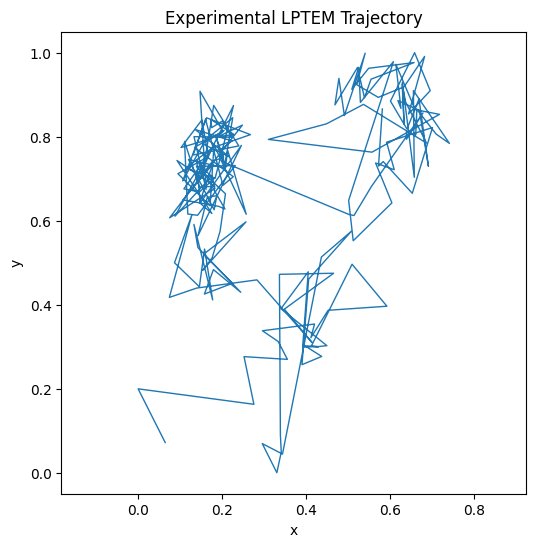

In [12]:
plt.figure(figsize=(6,6))

plt.plot(
    train[0,:,0],
    train[0,:,1],
    linewidth=1
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Experimental LPTEM Trajectory")
plt.axis("equal")
plt.show()

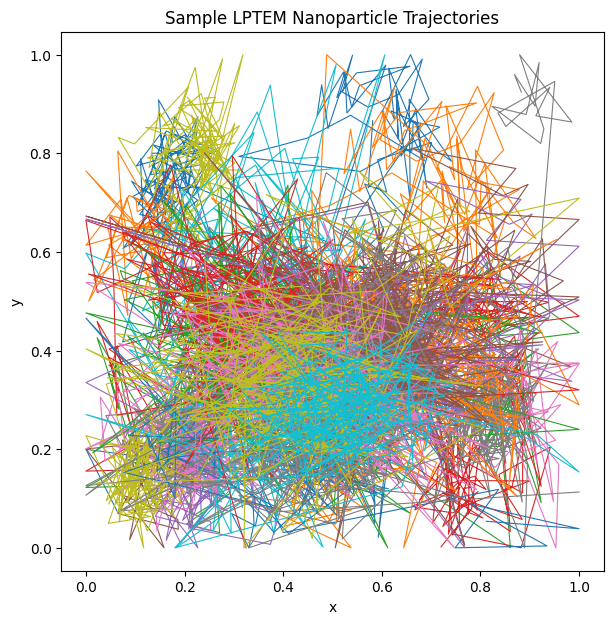

In [13]:
plt.figure(figsize=(7,7))

for i in range(20):
    plt.plot(
        train[i,:,0],
        train[i,:,1],
        linewidth=0.8
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Sample LPTEM Nanoparticle Trajectories")
plt.axis("equal")
plt.show()

In [14]:
plt.savefig("sample_trajectories.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [15]:
!wget -q https://huggingface.co/JamaliLab/LEONARDO/resolve/main/LEONARDOModel -O LEONARDOModel

In [16]:
!ls -lh LEONARDOModel

-rw-r--r-- 1 root root 102M Nov  3 18:23 LEONARDOModel


In [17]:
import numpy as np

trainset = np.load("lptem_train.npy")
valset = np.load("lptem_val.npy")
testset = np.load("lptem_test.npy")

print("Train:", trainset.shape)
print("Validation:", valset.shape)
print("Test:", testset.shape)

Train: (38279, 200, 3)
Validation: (3202, 200, 3)
Test: (5934, 200, 3)


In [18]:
!find /kaggle/working -name "lptem_*.npy"

/kaggle/working/LEONARDO/lptem_test.npy
/kaggle/working/LEONARDO/lptem_val.npy
/kaggle/working/LEONARDO/MoNet2.0/lptem_val.npy
/kaggle/working/LEONARDO/lptem_train.npy


In [19]:
from LEONARDO_utils import prepare_dataset

trainset_torch = prepare_dataset(
    trainset[:, :, 0:2],
    shuffle=True,
    norm=True
)

valset_torch = prepare_dataset(
    valset[:, :, 0:2],
    shuffle=False,
    norm=True
)

testset_torch = prepare_dataset(
    testset[:, :, 0:2],
    shuffle=False,
    norm=True
)

print(trainset_torch.shape)
print(valset_torch.shape)
print(testset_torch.shape)

torch.Size([38279, 200, 2])
torch.Size([3202, 200, 2])
torch.Size([5934, 200, 2])


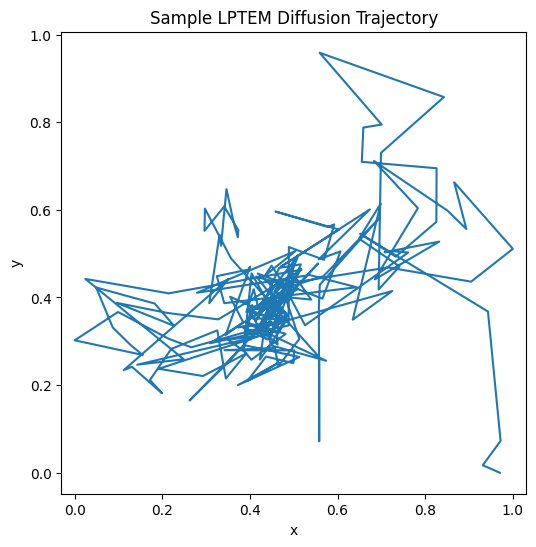

In [20]:
import matplotlib.pyplot as plt

trajectory = trainset_torch[0].numpy()

plt.figure(figsize=(6, 6))
plt.plot(trajectory[:, 0], trajectory[:, 1])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Sample LPTEM Diffusion Trajectory")
plt.axis("equal")
plt.show()

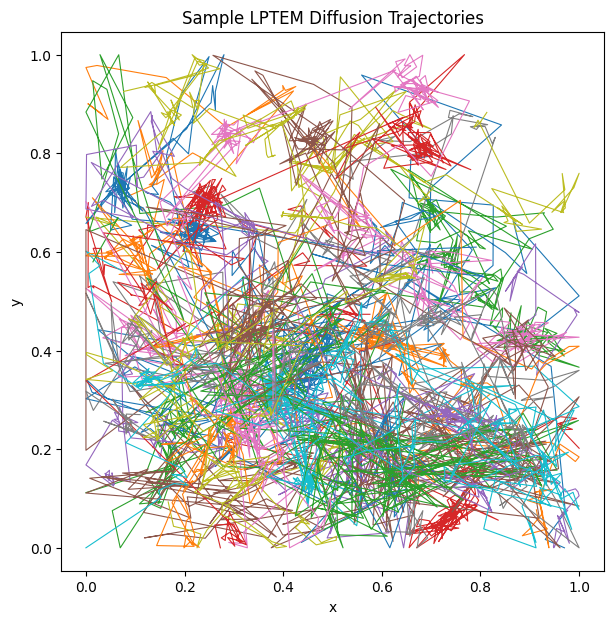

In [21]:
plt.figure(figsize=(7, 7))

for i in range(20):
    trajectory = trainset_torch[i].numpy()
    plt.plot(trajectory[:, 0], trajectory[:, 1], linewidth=0.8)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Sample LPTEM Diffusion Trajectories")
plt.axis("equal")
plt.show()

In [22]:
print("Shape:", trainset_torch.shape)
print("Min:", trainset_torch.min().item())
print("Max:", trainset_torch.max().item())
print("Mean:", trainset_torch.mean().item())
print("Std:", trainset_torch.std().item())

Shape: torch.Size([38279, 200, 2])
Min: 0.0
Max: 1.0
Mean: 0.4385339319705963
Std: 0.24595136940479279


In [23]:
import LEONARDO_model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = LEONARDO_model.TransformerVAE(
    device=device
).to(device)

print(model)

TransformerVAE(
  (encoder): Encoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerBlock(
        (attention): SelfAttention(
          (values): Linear(in_features=128, out_features=128, bias=False)
          (keys): Linear(in_features=128, out_features=128, bias=False)
          (queries): Linear(in_features=128, out_features=128, bias=False)
          (fc_out): Linear(in_features=128, out_features=128, bias=True)
        )
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (feed_forward): Sequential(
          (0): Linear(in_features=128, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
    )
    (dropout): Dropout(p=0.0, inplace=False)
    (conv1): Conv1d(2, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (bottleneck): Bottleneck_Encod

In [24]:
sample = trainset_torch[:4].to(device)

model.eval()

with torch.no_grad():
    output = model(sample)

print(type(output))

<class 'tuple'>


In [25]:
print("Device:", device)
print("Model device:", next(model.parameters()).device)
print("Sample device:", sample.device)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
Model device: cuda:0
Sample device: cuda:0
CUDA available: True
GPU: Tesla T4


In [26]:
device = torch.device("cuda")

model = LEONARDO_model.TransformerVAE(
    device=device
).to(device)

model.eval()

TransformerVAE(
  (encoder): Encoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerBlock(
        (attention): SelfAttention(
          (values): Linear(in_features=128, out_features=128, bias=False)
          (keys): Linear(in_features=128, out_features=128, bias=False)
          (queries): Linear(in_features=128, out_features=128, bias=False)
          (fc_out): Linear(in_features=128, out_features=128, bias=True)
        )
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (feed_forward): Sequential(
          (0): Linear(in_features=128, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
    )
    (dropout): Dropout(p=0.0, inplace=False)
    (conv1): Conv1d(2, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (bottleneck): Bottleneck_Encod

In [27]:
sample = trainset_torch[:1].to(device)

with torch.no_grad():
    output = model(sample)

print(type(output))

<class 'tuple'>


In [28]:
print("Number of outputs:", len(output))

for i, item in enumerate(output):
    print(i, type(item), item.shape)

Number of outputs: 4
0 <class 'torch.Tensor'> torch.Size([1, 12])
1 <class 'torch.Tensor'> torch.Size([1, 12])
2 <class 'torch.Tensor'> torch.Size([1, 12])
3 <class 'torch.Tensor'> torch.Size([1, 200, 2])


In [29]:
z, mu, logvar, reconstructed = output

print("Latent z:", z.shape)
print("Mean:", mu.shape)
print("Log variance:", logvar.shape)
print("Reconstruction:", reconstructed.shape)

Latent z: torch.Size([1, 12])
Mean: torch.Size([1, 12])
Log variance: torch.Size([1, 12])
Reconstruction: torch.Size([1, 200, 2])


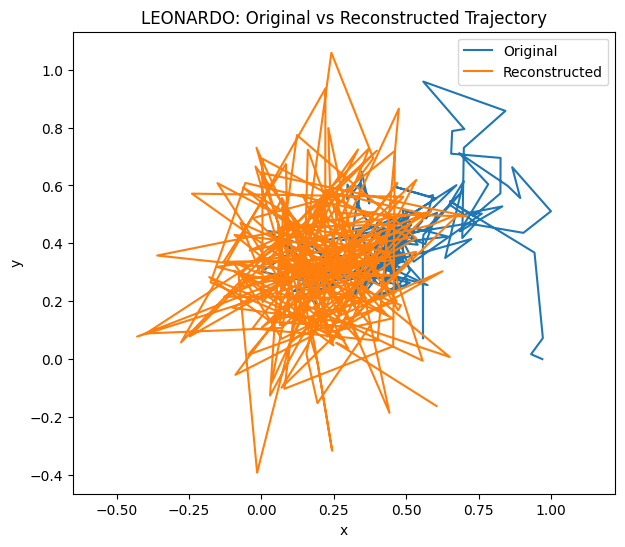

In [30]:
import matplotlib.pyplot as plt

original = sample[0].detach().cpu().numpy()
recon = reconstructed[0].detach().cpu().numpy()

plt.figure(figsize=(7, 6))

plt.plot(
    original[:, 0],
    original[:, 1],
    label="Original"
)

plt.plot(
    recon[:, 0],
    recon[:, 1],
    label="Reconstructed"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("LEONARDO: Original vs Reconstructed Trajectory")
plt.axis("equal")
plt.legend()
plt.show()

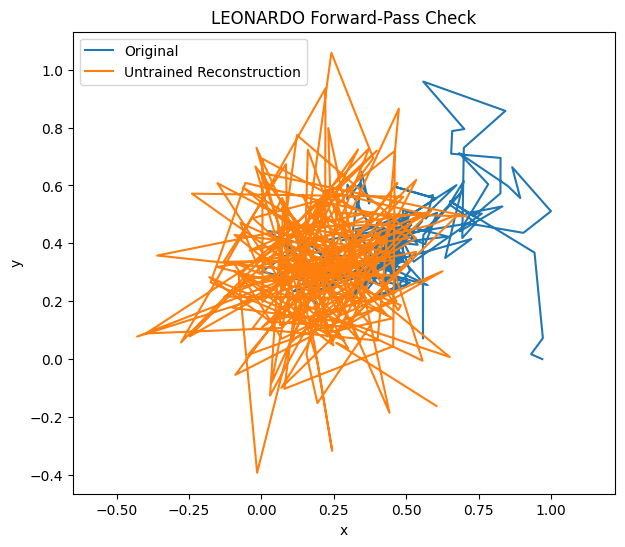

In [31]:
import matplotlib.pyplot as plt

original = sample[0].detach().cpu().numpy()
recon = output[3][0].detach().cpu().numpy()

plt.figure(figsize=(7, 6))

plt.plot(
    original[:, 0],
    original[:, 1],
    label="Original"
)

plt.plot(
    recon[:, 0],
    recon[:, 1],
    label="Untrained Reconstruction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("LEONARDO Forward-Pass Check")
plt.axis("equal")
plt.legend()
plt.show()

In [32]:
import inspect

print(inspect.signature(model.train_Leonardo))

print(inspect.getsource(model.train_Leonardo))

(epochs, dataloader, optimizer, device, val_loader=None)
    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
            None
        """

        total_epochs = self.epochs + epochs

        for epoch in range(epochs):
            # Train data
            loss_epoch, loss_kl_training, loss_mse_training, loss_kurtosis_training, loss_skewness_training, \
                loss_variance_training, loss_mean_training, loss_acorr_training, \
                    loss_acorr_batch_training,

In [33]:
print(model.loss_weights)

{'kurt_factor': 0.06, 'skew_factor': 10, 'var_factor': 500, 'mean_factor': 50000, 'median_factor': 1, 'acorr_factor': 1000, 'mse_factor': 0.001, 'kl_factor': 0.05, 'acorr_batch_factor': 100, 'xycorr_factor': 10, 'pos_acorr_factor': 1}


In [34]:
import inspect

print(inspect.signature(LEONARDO_model.TransformerVAE))

(embed_size=128, num_layers=2, forward_expansion=2, heads=8, dropout=0.0, device='cuda:3', length_trajectory=200, latent_space=12)


In [35]:
import inspect

print(inspect.signature(model.train_Leonardo))

(epochs, dataloader, optimizer, device, val_loader=None)


In [36]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    trainset_torch,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    valset_torch,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 599
Validation batches: 51


In [37]:
import torch
import LEONARDO_model

device = torch.device("cuda")

model = LEONARDO_model.TransformerVAE(
    device=device,
    embed_size=128,
    num_layers=2,
    forward_expansion=2,
    heads=8,
    dropout=0.0,
    length_trajectory=200,
    latent_space=12
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-5
)

In [38]:
model.train()

data = next(iter(train_loader))
data = data.to(device)

print("Batch:", data.shape)

train_data_dx = data[:, 1:] - data[:, :-1]

_, z_mean, z_log_var, decoded = model(data)

decoded_dx = decoded[:, 1:] - decoded[:, :-1]

print("Latent:", z_mean.shape)
print("Decoded:", decoded.shape)
print("Displacement:", decoded_dx.shape)

Batch: torch.Size([64, 200, 2])
Latent: torch.Size([64, 12])
Decoded: torch.Size([64, 200, 2])
Displacement: torch.Size([64, 199, 2])


In [39]:
del data, train_data_dx, decoded_dx, decoded
torch.cuda.empty_cache()

In [40]:
model.train()

model.train_Leonardo(
    epochs=1,
    dataloader=train_loader,
    optimizer=optimizer,
    device=device,
    val_loader=val_loader
)


epoch [1/1], Training loss:7.97, KL-div training loss:4.7, MSE training loss:0.02, Kurtosis training loss:18.78, Skewness training loss (x10e3):451.78, Var training loss (x10e5):20.77, Mean training loss (x10e7):25.58, Median training loss (x10e7):457.98,acorr training loss (x10e3):1.04, acorr batch training loss (x10e4):10.90, xycorr factor training loss (x10e3): 38.801,pos acorr training loss (x10e3): 313.068
Validation loss:7.86, KL-div val loss:4.7, MSE val loss:0.02, Kurtosis val loss:15.06, Skewness val loss (x10e3):421.80, Var val loss (x10e5):7.39, Mean val loss (x10e7):16.30, Median val loss (x10e7):247.12, acorr val loss (x10e3):1.00, acorr batch val loss (x10e4):37.87, xycorr val loss (x10e3): 70.280, pos acorr val loss (x10e3): 297.557
model training completed


In [41]:
import torch
import os

os.makedirs("results", exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epoch": 1,
}, "results/leonardo_epoch1_sanity.pt")

print("Checkpoint saved.")

Checkpoint saved.


In [42]:
!ls -lh results/

total 101M
-rw-r--r-- 1 root root 101M Nov  3 18:24 leonardo_epoch1_sanity.pt


LEONARDO has been successfully instantiated and trained for one epoch on the experimental LPTEM trajectory dataset using the original architecture and physics-informed loss formulation, with batch size adjusted to fit the available T4 GPU.

In [43]:
!find /kaggle/working -name "LEONARDOModel" -o -name "LEONARDOModel*"

/kaggle/working/LEONARDO/LEONARDOModel


In [44]:
import os

paths = [
    "/kaggle/working/LEONARDO/LEONARDO/LEONARDOModel",
    "/kaggle/working/LEONARDO/LEONARDOModel"
]

for p in paths:
    print("\nPATH:", p)
    print("Exists:", os.path.exists(p))
    print("Size:", os.path.getsize(p) / (1024**3), "GB")


PATH: /kaggle/working/LEONARDO/LEONARDO/LEONARDOModel
Exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/LEONARDO/LEONARDO/LEONARDOModel'

In [45]:
!file /kaggle/working/LEONARDO/LEONARDOModel
!file /kaggle/working/LEONARDO/LEONARDO/LEONARDOModel

/kaggle/working/LEONARDO/LEONARDOModel: Zip archive data, at least v0.0 to extract, compression method=store
/kaggle/working/LEONARDO/LEONARDO/LEONARDOModel: cannot open `/kaggle/working/LEONARDO/LEONARDO/LEONARDOModel' (No such file or directory)


In [46]:
import zipfile

path = "/kaggle/working/LEONARDO/LEONARDOModel"

with zipfile.ZipFile(path, "r") as z:
    print("Files inside checkpoint:")
    for name in z.namelist():
        print(name)

Files inside checkpoint:
Leonardo/data.pkl
Leonardo/data/0
Leonardo/data/1
Leonardo/data/10
Leonardo/data/100
Leonardo/data/101
Leonardo/data/102
Leonardo/data/103
Leonardo/data/104
Leonardo/data/105
Leonardo/data/106
Leonardo/data/107
Leonardo/data/108
Leonardo/data/109
Leonardo/data/11
Leonardo/data/110
Leonardo/data/111
Leonardo/data/112
Leonardo/data/113
Leonardo/data/114
Leonardo/data/115
Leonardo/data/116
Leonardo/data/117
Leonardo/data/118
Leonardo/data/119
Leonardo/data/12
Leonardo/data/120
Leonardo/data/121
Leonardo/data/122
Leonardo/data/123
Leonardo/data/124
Leonardo/data/125
Leonardo/data/126
Leonardo/data/127
Leonardo/data/128
Leonardo/data/129
Leonardo/data/13
Leonardo/data/130
Leonardo/data/131
Leonardo/data/132
Leonardo/data/133
Leonardo/data/134
Leonardo/data/135
Leonardo/data/136
Leonardo/data/137
Leonardo/data/138
Leonardo/data/139
Leonardo/data/14
Leonardo/data/140
Leonardo/data/141
Leonardo/data/142
Leonardo/data/143
Leonardo/data/144
Leonardo/data/145
Leonardo/dat

In [47]:
import os

for root, dirs, files in os.walk("/kaggle/working/LEONARDO"):
    for f in files:
        if f.endswith(".ipynb"):
            print(os.path.join(root, f))

/kaggle/working/LEONARDO/LEONARDO_introductory_notebook.ipynb


In [48]:
!grep -n -C 5 "LEONARDOModel" /kaggle/working/LEONARDO/LEONARDO_introductory_notebook.ipynb | head -100

19-    "#### - `LEONARDO_utils.py` - python file containing all the helper functions\n",
20-    "#### - `LEONARDO_model.py` - python file containing the LEONARDO model and model training code\n",
21-    "#### - `lptem_train.npy` - numpy file containing the training dataset.\n",
22-    "#### - `lptem_test.npy` - numpy file containing the test dataset.\n",
23-    "#### - `lptem_val.npy` - numpy file containing the validation dataset.\n",
24:    "#### - (optional) `LEONARDOModel` - pre-trained LEONARDO model"
25-   ]
26-  },
27-  {
28-   "cell_type": "code",
29-   "execution_count": 1,
--
262-   ],
263-   "source": [
264-    "# if you want to load in an already trained model:\n",
265-    "device = 'cpu'\n",
266-    "model = LEONARDO_model.TransformerVAE(device=device).to(device)\n",
267:    "model.load_model('LEONARDOModel')"
268-   ]
269-  },
270-  {
271-   "cell_type": "markdown",
272-   "metadata": {},


In [49]:
import torch
import LEONARDO_model

device_pretrained = "cpu"

pretrained_model = LEONARDO_model.TransformerVAE(
    device=device_pretrained
).to(device_pretrained)

In [50]:
checkpoint_path = "/kaggle/working/LEONARDO/LEONARDOModel"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print(checkpoint.keys())

dict_keys(['Model', 'Trajectory Length', 'Latent Space', 'Epochs', 'Training Loss', 'Validation Loss', 'Model Architecture', 'Batch Size', 'Learning Rate', 'Weight Decay', 'Optimizer', 'optimizer state dict', 'Trajectory Types', 'Training Dataset Size', 'Validation Dataset Size', 'Random Seed', 'GPU number', 'Trained on dx or x?', 'Normalization type', 'Notes', 'loss weights', 'Training loss', 'Training MSE loss', 'Training KL loss', 'Training Kurtosis loss', 'Training Skewness loss', 'Training Variance loss', 'Training Mean loss', 'Training Median loss', 'Training Autocorrelation loss', 'Training Autocorrelation batch loss', 'Training xy-Correlation loss', 'Training Positional Acorr loss', 'Validation loss', 'Validation MSE loss', 'Validation KL loss', 'Validation Kurtosis loss', 'Validation Skewness loss', 'Validation Variance loss', 'Validation Mean loss', 'Validation Median loss', 'Validation Autocorrelation loss', 'Validation Autocorrelation batch loss', 'Validation xy-Correlation

In [51]:
pretrained_model.load_state_dict(checkpoint["Model"])

print("Pretrained LEONARDO weights loaded successfully.")

Pretrained LEONARDO weights loaded successfully.


In [52]:
pretrained_model.eval()

with torch.no_grad():
    z = torch.randn(1, 12)
    generated = pretrained_model.decoder(z)

print("Latent:", z.shape)
print("Generated:", generated.shape)

Latent: torch.Size([1, 12])
Generated: torch.Size([1, 200, 2])


In [53]:
pretrained_model.eval()

with torch.no_grad():
    z = torch.randn(100, 12)
    generated = pretrained_model.decoder(z)

print("Generated shape:", generated.shape)
print("Min:", generated.min().item())
print("Max:", generated.max().item())
print("Mean:", generated.mean().item())
print("Std:", generated.std().item())

Generated shape: torch.Size([100, 200, 2])
Min: -0.4502899646759033
Max: 1.169083595275879
Mean: 0.3972567915916443
Std: 0.2400672733783722


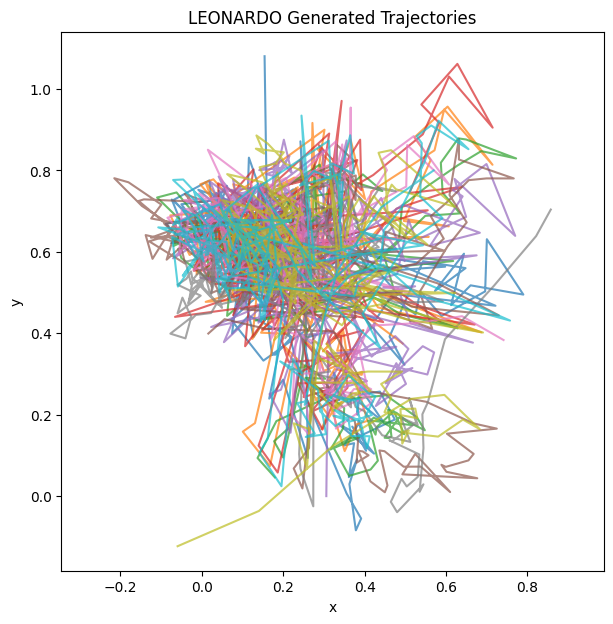

In [54]:
import matplotlib.pyplot as plt

generated_np = generated.cpu().numpy()

plt.figure(figsize=(7, 7))

for i in range(10):
    plt.plot(
        generated_np[i, :, 0],
        generated_np[i, :, 1],
        alpha=0.7
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("LEONARDO Generated Trajectories")
plt.axis("equal")
plt.show()

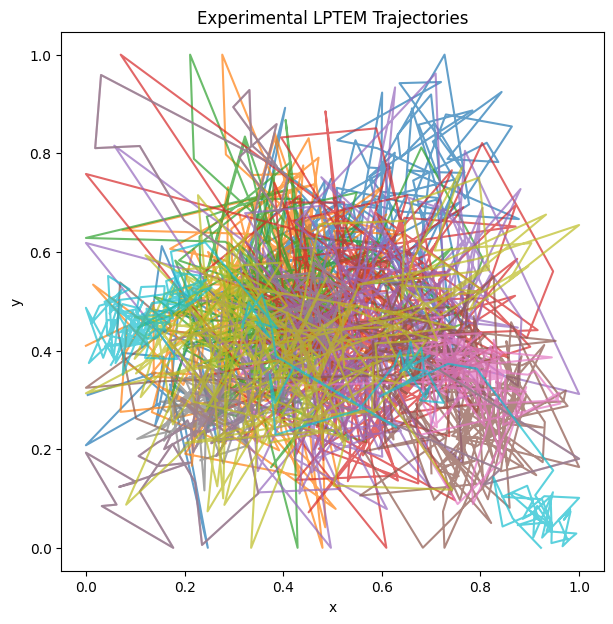

In [55]:
test_sample = testset_torch[:10].cpu().numpy()

plt.figure(figsize=(7, 7))

for i in range(10):
    plt.plot(
        test_sample[i, :, 0],
        test_sample[i, :, 1],
        alpha=0.7
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Experimental LPTEM Trajectories")
plt.axis("equal")
plt.show()

The official pretrained LEONARDO model has been loaded successfully, and synthetic nanoparticle trajectories can be generated from its 12-dimensional latent space.

In [56]:
pretrained_model.eval()

with torch.no_grad():
    z = torch.randn(100, 12)
    generated = pretrained_model.decoder(z)

print(generated.shape)

torch.Size([100, 200, 2])


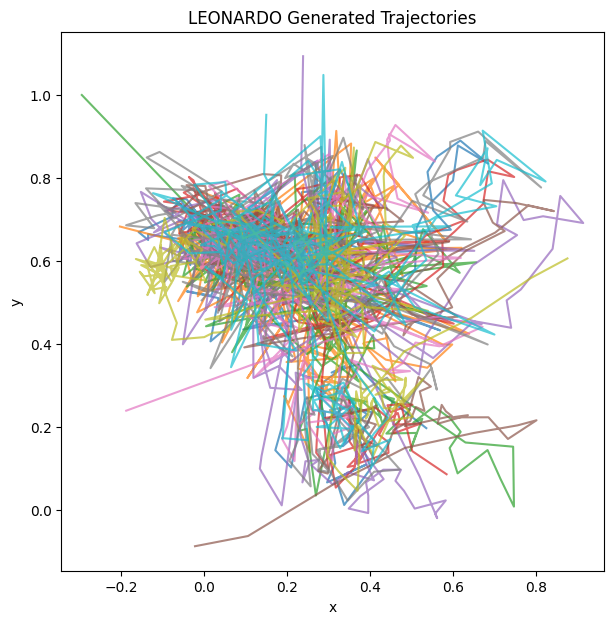

In [57]:
import matplotlib.pyplot as plt

generated_np = generated.cpu().numpy()

plt.figure(figsize=(7, 7))

for i in range(10):
    plt.plot(
        generated_np[i, :, 0],
        generated_np[i, :, 1],
        alpha=0.7
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("LEONARDO Generated Trajectories")
plt.axis("equal")
plt.show()

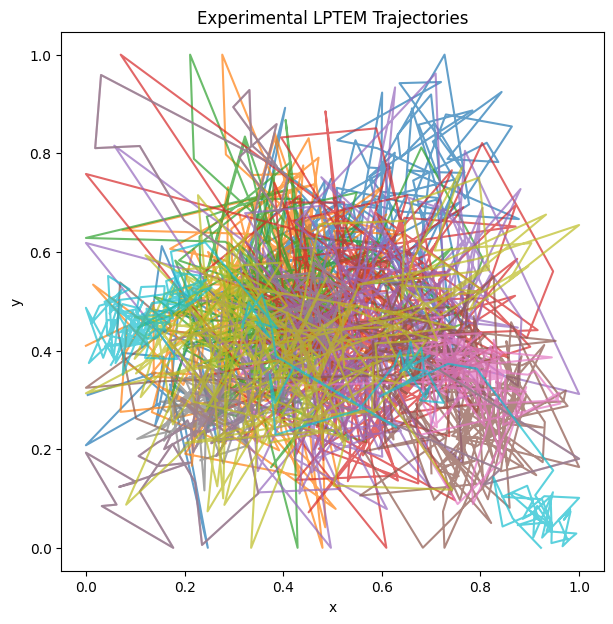

In [58]:
test_np = testset_torch[:10].cpu().numpy()

plt.figure(figsize=(7, 7))

for i in range(10):
    plt.plot(
        test_np[i, :, 0],
        test_np[i, :, 1],
        alpha=0.7
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Experimental LPTEM Trajectories")
plt.axis("equal")
plt.show()

In [61]:
import numpy as np

def displacement_stats(trajectories):
    dx = trajectories[:, 1:] - trajectories[:, :-1]
    dx = dx.reshape(-1, 2)

    stats = {
        "mean": np.mean(dx, axis=0),
        "variance": np.var(dx, axis=0),
        "std": np.std(dx, axis=0),
        "median": np.median(dx, axis=0),
        "skewness": [],
        "kurtosis": []
    }

    from scipy.stats import skew, kurtosis

    stats["skewness"] = skew(dx, axis=0)
    stats["kurtosis"] = kurtosis(dx, axis=0)

    return stats

In [62]:
real_stats = displacement_stats(test_np)
generated_stats = displacement_stats(generated_np)

print("REAL")
for k, v in real_stats.items():
    print(k, v)

print("\nGENERATED")
for k, v in generated_stats.items():
    print(k, v)

REAL
mean [0.00056633 0.00024155]
variance [0.01501173 0.0214013 ]
std [0.12252238 0.14629182]
median [ 0.00047822 -0.00070237]
skewness [-0.02410626  0.08814786]
kurtosis [2.5546856 2.1604505]

GENERATED
mean [ 0.00023741 -0.00022456]
variance [0.00770135 0.00763147]
std [0.08775736 0.08735829]
median [ 9.4784796e-04 -4.5686960e-05]
skewness [-0.2716127   0.14189263]
kurtosis [5.989974  6.1489086]


In [63]:
import numpy as np
import matplotlib.pyplot as plt

def displacement_autocorrelation(trajectories, max_lag=50):
    dx = trajectories[:, 1:, :] - trajectories[:, :-1, :]

    # Flatten trajectories but preserve temporal lag structure
    dx = dx.reshape(-1, dx.shape[1], 2)

    acorr_x = []
    acorr_y = []

    for lag in range(max_lag + 1):
        x1 = dx[:, :dx.shape[1]-lag, 0]
        x2 = dx[:, lag:, 0]

        y1 = dx[:, :dx.shape[1]-lag, 1]
        y2 = dx[:, lag:, 1]

        acorr_x.append(np.mean(x1 * x2))
        acorr_y.append(np.mean(y1 * y2))

    return np.array(acorr_x), np.array(acorr_y)


real_ac_x, real_ac_y = displacement_autocorrelation(
    test_np, max_lag=50
)

gen_ac_x, gen_ac_y = displacement_autocorrelation(
    generated_np, max_lag=50
)

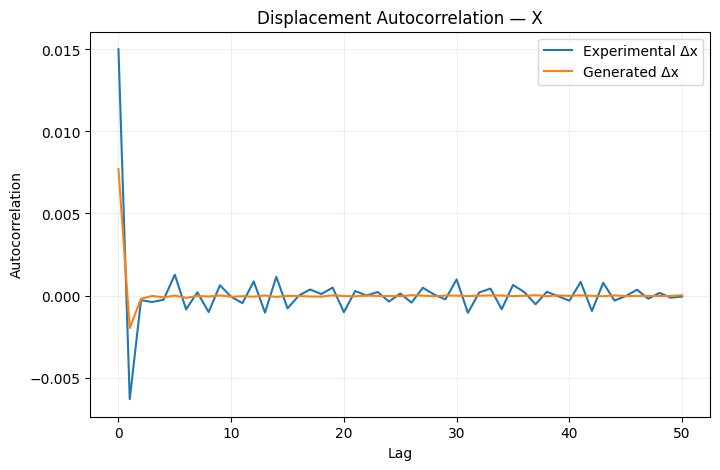

In [64]:
plt.figure(figsize=(8,5))

plt.plot(real_ac_x, label="Experimental Δx")
plt.plot(gen_ac_x, label="Generated Δx")

plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title("Displacement Autocorrelation — X")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

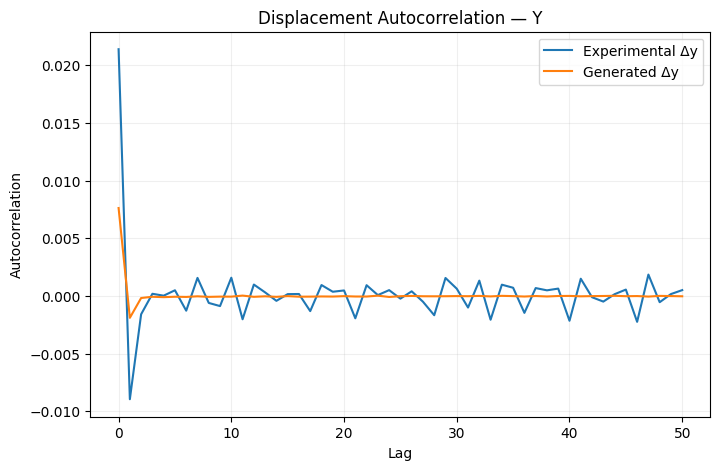

In [65]:
plt.figure(figsize=(8,5))

plt.plot(real_ac_y, label="Experimental Δy")
plt.plot(gen_ac_y, label="Generated Δy")

plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title("Displacement Autocorrelation — Y")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [66]:
import numpy as np
import matplotlib.pyplot as plt

def normalized_autocorrelation(trajectories, max_lag=50):
    dx = trajectories[:, 1:, :] - trajectories[:, :-1, :]

    results = []

    for dim in range(2):
        x = dx[:, :, dim]

        mean = np.mean(x)
        x = x - mean

        c0 = np.mean(x * x)

        ac = []

        for lag in range(max_lag + 1):
            if lag == 0:
                c = c0
            else:
                c = np.mean(x[:, :-lag] * x[:, lag:])

            ac.append(c / c0)

        results.append(np.array(ac))

    return results[0], results[1]


real_nac_x, real_nac_y = normalized_autocorrelation(
    test_np, max_lag=50
)

gen_nac_x, gen_nac_y = normalized_autocorrelation(
    generated_np, max_lag=50
)

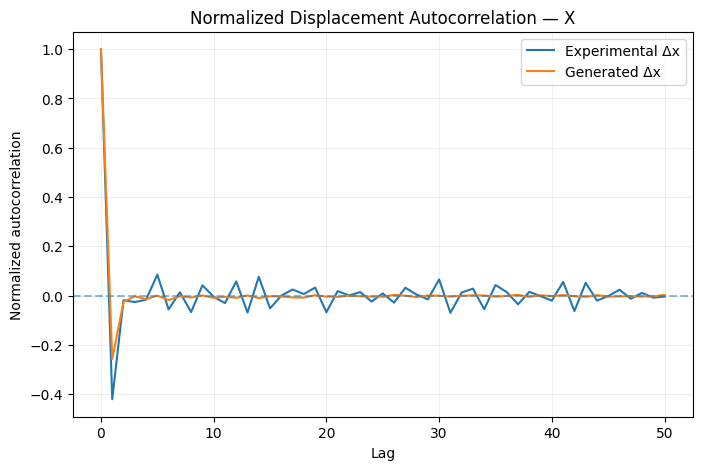

In [67]:
plt.figure(figsize=(8,5))

plt.plot(real_nac_x, label="Experimental Δx")
plt.plot(gen_nac_x, label="Generated Δx")

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Lag")
plt.ylabel("Normalized autocorrelation")
plt.title("Normalized Displacement Autocorrelation — X")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

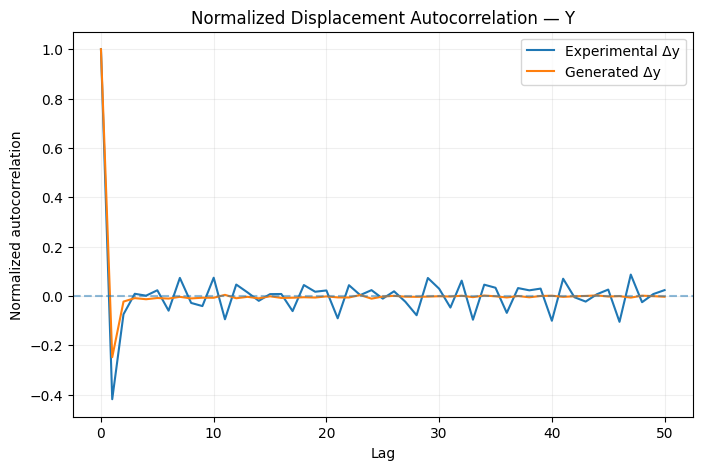

In [68]:
plt.figure(figsize=(8,5))

plt.plot(real_nac_y, label="Experimental Δy")
plt.plot(gen_nac_y, label="Generated Δy")

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Lag")
plt.ylabel("Normalized autocorrelation")
plt.title("Normalized Displacement Autocorrelation — Y")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [69]:
print("Model:", type(model))
print("Device:", next(model.parameters()).device)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

sample_batch = next(iter(train_loader))
print("Sample batch shape:", sample_batch.shape)
print("Sample batch device:", sample_batch.device)

Model: <class 'LEONARDO_model.TransformerVAE'>
Device: cuda:0
Train batches: 599
Val batches: 51
Optimizer: Adam
Learning rate: 0.0003
Sample batch shape: torch.Size([64, 200, 2])
Sample batch device: cpu


In [70]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda:0")

baseline_model = LEONARDO_model.TransformerVAE(
    embed_size=128,
    num_layers=2,
    forward_expansion=2,
    heads=8,
    dropout=0.0,
    device="cuda:0",
    length_trajectory=200,
    latent_space=12
).to(device)

print("Model device:", next(baseline_model.parameters()).device)

Model device: cuda:0


In [71]:
baseline_optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.0003
)

print("Optimizer:", type(baseline_optimizer).__name__)
print("Learning rate:", baseline_optimizer.param_groups[0]["lr"])

Optimizer: Adam
Learning rate: 0.0003


In [72]:
baseline_model.train()

baseline_model.train_Leonardo(
    epochs=2,
    dataloader=train_loader,
    optimizer=baseline_optimizer,
    device=device,
    val_loader=val_loader
)


epoch [1/2], Training loss:7.97, KL-div training loss:5.8, MSE training loss:0.02, Kurtosis training loss:18.53, Skewness training loss (x10e3):448.27, Var training loss (x10e5):20.05, Mean training loss (x10e7):24.78, Median training loss (x10e7):399.83,acorr training loss (x10e3):1.04, acorr batch training loss (x10e4):11.21, xycorr factor training loss (x10e3): 39.328,pos acorr training loss (x10e3): 317.261
Validation loss:7.69, KL-div val loss:6.2, MSE val loss:0.02, Kurtosis val loss:14.43, Skewness val loss (x10e3):402.11, Var val loss (x10e5):6.70, Mean val loss (x10e7):17.47, Median val loss (x10e7):270.89, acorr val loss (x10e3):0.94, acorr batch val loss (x10e4):38.35, xycorr val loss (x10e3): 72.191, pos acorr val loss (x10e3): 328.469
epoch [2/2], Training loss:6.19, KL-div training loss:7.4, MSE training loss:0.02, Kurtosis training loss:14.44, Skewness training loss (x10e3):323.92, Var training loss (x10e5):5.90, Mean training loss (x10e7):17.64, Median training loss (x

In [75]:
baseline_model.eval()

print("Model ready for generation")
print("Device:", next(baseline_model.parameters()).device)

Model ready for generation
Device: cuda:0


In [76]:
print("Checking available test variables...")

for name in [
    "testset",
    "testset_torch",
    "test_set",
    "test_data",
    "test_np",
    "test",
]:
    if name in globals():
        obj = globals()[name]
        try:
            print(name, "->", type(obj), obj.shape)
        except:
            print(name, "->", type(obj))

Checking available test variables...
testset -> <class 'numpy.ndarray'> (5934, 200, 3)
testset_torch -> <class 'torch.Tensor'> torch.Size([5934, 200, 2])
test_np -> <class 'numpy.ndarray'> (10, 200, 2)


In [77]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    testset_torch,
    batch_size=64,
    shuffle=False
)

print("Test batches:", len(test_loader))

Test batches: 93


In [78]:
test_batch = next(iter(test_loader))

print("Test batch shape:", test_batch.shape)
print("Test batch min:", test_batch.min().item())
print("Test batch max:", test_batch.max().item())

Test batch shape: torch.Size([64, 200, 2])
Test batch min: 0.0
Test batch max: 1.0


In [79]:
with torch.no_grad():

    test_input = test_batch.to(device)

    latent, z_mean, z_logvar, generated_batch = baseline_model(test_input)

print("Generated shape:", generated_batch.shape)

Generated shape: torch.Size([64, 200, 2])


In [80]:
real_batch_np = test_batch.cpu().numpy()
generated_batch_np = generated_batch.cpu().numpy()

print("Real:", real_batch_np.shape)
print("Generated:", generated_batch_np.shape)

Real: (64, 200, 2)
Generated: (64, 200, 2)


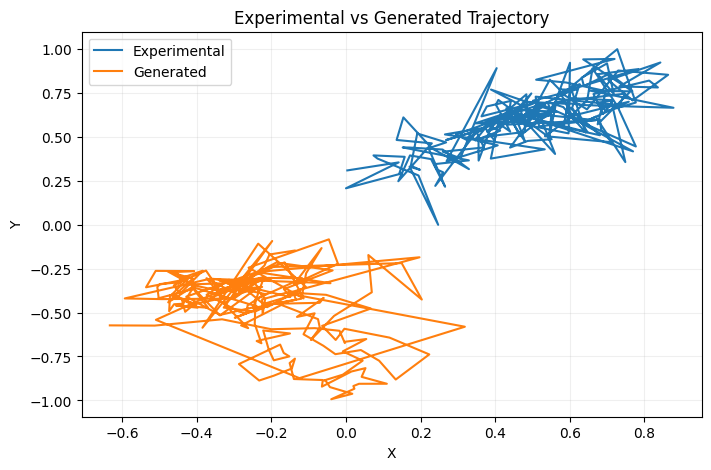

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    real_batch_np[0, :, 0],
    real_batch_np[0, :, 1],
    label="Experimental"
)

plt.plot(
    generated_batch_np[0, :, 0],
    generated_batch_np[0, :, 1],
    label="Generated"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Experimental vs Generated Trajectory")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [82]:
baseline_model.eval()

generated_list = []

with torch.no_grad():

    for batch in test_loader:

        batch = batch.to(device)

        _, _, _, generated = baseline_model(batch)

        generated_list.append(
            generated.cpu()
        )

generated_all = torch.cat(generated_list, dim=0)

print("Generated test trajectories:", generated_all.shape)

Generated test trajectories: torch.Size([5934, 200, 2])


In [83]:
generated_np = generated_all.numpy()

print("Generated NumPy shape:", generated_np.shape)

Generated NumPy shape: (5934, 200, 2)


In [84]:
from scipy.stats import skew, kurtosis
import numpy as np

def calculate_statistics(data):

    dx = data[:, 1:, :] - data[:, :-1, :]

    stats = {
        "mean": np.mean(dx, axis=(0, 1)),
        "variance": np.var(dx, axis=(0, 1)),
        "std": np.std(dx, axis=(0, 1)),
        "median": np.median(dx, axis=(0, 1)),
        "skewness": skew(dx.reshape(-1, 2), axis=0),
        "kurtosis": kurtosis(
            dx.reshape(-1, 2),
            axis=0,
            fisher=False
        )
    }

    return stats

In [85]:
print("EXPERIMENTAL")

for key, value in real_stats.items():
    print(f"{key}: {value}")

print("GENERATED — 2 EPOCH MODEL")

for key, value in generated_stats.items():
    print(f"{key}: {value}")

EXPERIMENTAL
mean: [0.00056633 0.00024155]
variance: [0.01501173 0.0214013 ]
std: [0.12252238 0.14629182]
median: [ 0.00047822 -0.00070237]
skewness: [-0.02410626  0.08814786]
kurtosis: [2.5546856 2.1604505]
GENERATED — 2 EPOCH MODEL
mean: [ 0.00023741 -0.00022456]
variance: [0.00770135 0.00763147]
std: [0.08775736 0.08735829]
median: [ 9.4784796e-04 -4.5686960e-05]
skewness: [-0.2716127   0.14189263]
kurtosis: [5.989974  6.1489086]


In [86]:
print(f"{'Metric':<15} {'Experimental X':>18} {'Generated X':>18} {'Experimental Y':>18} {'Generated Y':>18}")

print("-" * 90)

for metric in [
    "mean",
    "variance",
    "std",
    "median",
    "skewness",
    "kurtosis"
]:

    print(
        f"{metric:<15}"
        f"{real_stats[metric][0]:>18.6f}"
        f"{generated_stats[metric][0]:>18.6f}"
        f"{real_stats[metric][1]:>18.6f}"
        f"{generated_stats[metric][1]:>18.6f}"
    )

Metric              Experimental X        Generated X     Experimental Y        Generated Y
------------------------------------------------------------------------------------------
mean                     0.000566          0.000237          0.000242         -0.000225
variance                 0.015012          0.007701          0.021401          0.007631
std                      0.122522          0.087757          0.146292          0.087358
median                   0.000478          0.000948         -0.000702         -0.000046
skewness                -0.024106         -0.271613          0.088148          0.141893
kurtosis                 2.554686          5.989974          2.160450          6.148909


In [87]:
def normalized_autocorrelation(trajectories, max_lag=50):

    dx = trajectories[:, 1:, :] - trajectories[:, :-1, :]

    results = []

    for dim in range(2):

        x = dx[:, :, dim]

        x = x - np.mean(x)

        c0 = np.mean(x * x)

        ac = []

        for lag in range(max_lag + 1):

            if lag == 0:
                c = c0
            else:
                c = np.mean(
                    x[:, :-lag] * x[:, lag:]
                )

            ac.append(c / c0)

        results.append(np.array(ac))

    return results[0], results[1]

In [88]:
real_ac_x, real_ac_y = normalized_autocorrelation(
    test_np,
    max_lag=50
)

generated_ac_x, generated_ac_y = normalized_autocorrelation(
    generated_np,
    max_lag=50
)

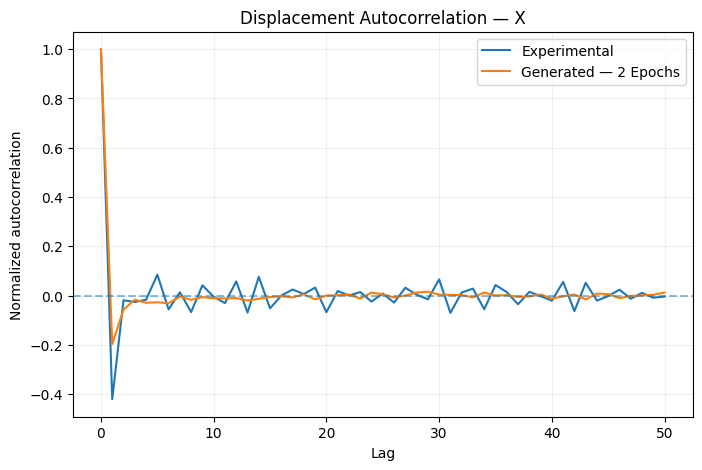

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(real_ac_x, label="Experimental")
plt.plot(generated_ac_x, label="Generated — 2 Epochs")

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Lag")
plt.ylabel("Normalized autocorrelation")
plt.title("Displacement Autocorrelation — X")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

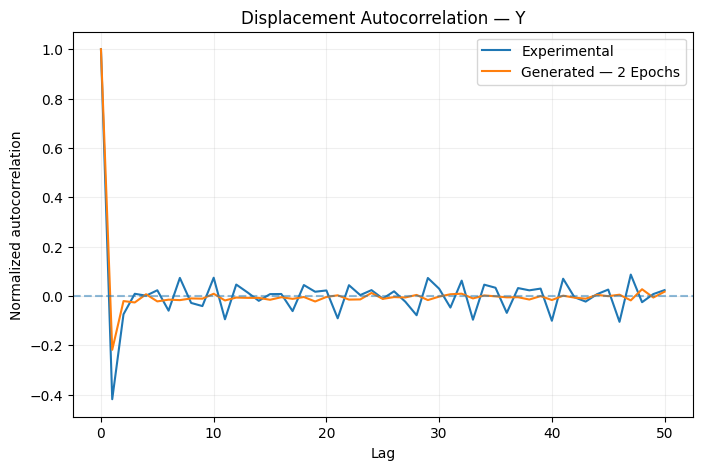

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(real_ac_y, label="Experimental")
plt.plot(generated_ac_y, label="Generated — 2 Epochs")

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Lag")
plt.ylabel("Normalized autocorrelation")
plt.title("Displacement Autocorrelation — Y")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [91]:
model.eval()

generated_list = []

with torch.no_grad():
    for i, batch in enumerate(test_loader):

        batch = batch.to(device)

        _, _, _, generated = model(batch)

        generated_list.append(generated.cpu())

generated_all = torch.cat(generated_list, dim=0)

print("Generated shape:", generated_all.shape)

Generated shape: torch.Size([5934, 200, 2])


In [92]:
real_all = testset_torch.cpu().numpy()
generated_all_np = generated_all.numpy()

print("Real:", real_all.shape)
print("Generated:", generated_all_np.shape)

Real: (5934, 200, 2)
Generated: (5934, 200, 2)


In [93]:
import numpy as np

# Real and generated test trajectories
real = real_all
gen = generated_all_np

# Flatten all trajectory points
real_flat = real.reshape(-1, 2)
gen_flat = gen.reshape(-1, 2)

def get_stats(data):
    return {
        "mean_x": np.mean(data[:, 0]),
        "mean_y": np.mean(data[:, 1]),
        "var_x": np.var(data[:, 0]),
        "var_y": np.var(data[:, 1]),
        "std_x": np.std(data[:, 0]),
        "std_y": np.std(data[:, 1]),
        "median_x": np.median(data[:, 0]),
        "median_y": np.median(data[:, 1]),
    }

real_stats = get_stats(real_flat)
gen_stats = get_stats(gen_flat)

print("TEST SET COMPARISON")

for key in real_stats:
    print(
        f"{key:10s} | "
        f"Real: {real_stats[key]:.6f} | "
        f"Generated: {gen_stats[key]:.6f}"
    )

TEST SET COMPARISON
mean_x     | Real: 0.393437 | Generated: 0.141991
mean_y     | Real: 0.448088 | Generated: -0.809605
var_x      | Real: 0.060410 | Generated: 0.047502
var_y      | Real: 0.059172 | Generated: 0.045274
std_x      | Real: 0.245785 | Generated: 0.217950
std_y      | Real: 0.243252 | Generated: 0.212777
median_x   | Real: 0.346651 | Generated: 0.197029
median_y   | Real: 0.426267 | Generated: -0.748429


In [94]:
print("RELATIVE ERROR")

for key in real_stats:
    r = real_stats[key]
    g = gen_stats[key]

    if abs(r) > 1e-12:
        error = abs(g - r) / abs(r) * 100
        print(f"{key:10s}: {error:.2f}%")

RELATIVE ERROR
mean_x    : 63.91%
mean_y    : 280.68%
var_x     : 21.37%
var_y     : 23.49%
std_x     : 11.32%
std_y     : 12.53%
median_x  : 43.16%
median_y  : 275.58%


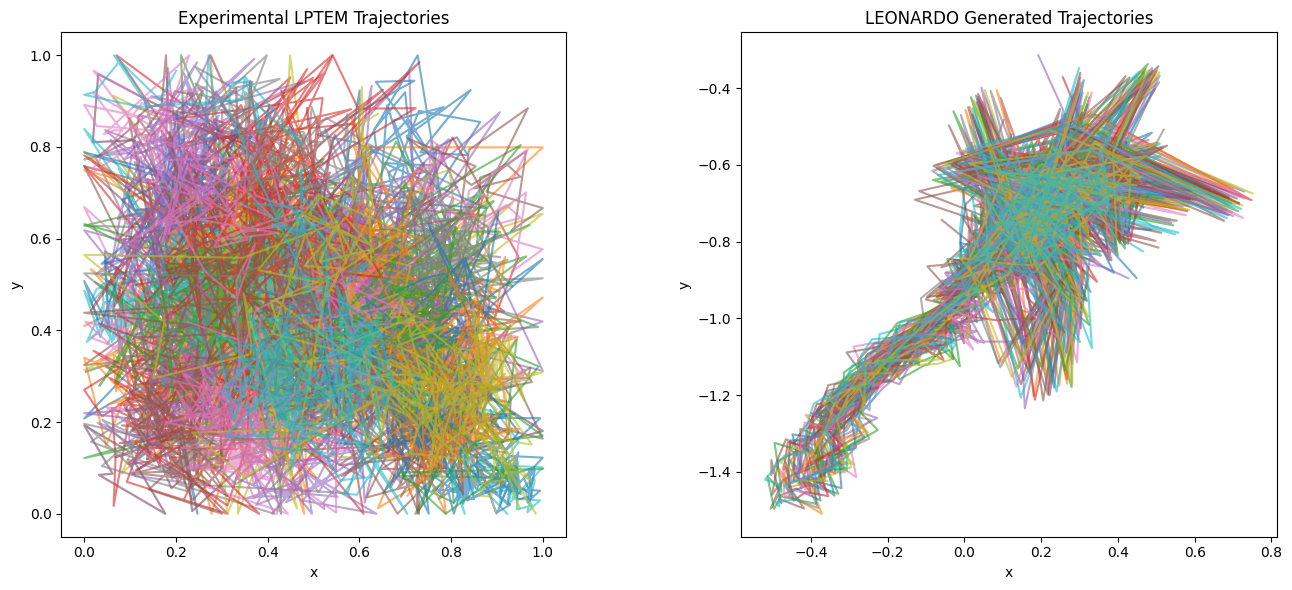

In [95]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Real trajectories
for i in range(30):
    axes[0].plot(real[i, :, 0], real[i, :, 1], alpha=0.6)

axes[0].set_title("Experimental LPTEM Trajectories")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")

# Generated trajectories
for i in range(30):
    axes[1].plot(gen[i, :, 0], gen[i, :, 1], alpha=0.6)

axes[1].set_title("LEONARDO Generated Trajectories")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()

In [96]:
real_dx = np.diff(real[:, :, 0], axis=1).flatten()
real_dy = np.diff(real[:, :, 1], axis=1).flatten()

gen_dx = np.diff(gen[:, :, 0], axis=1).flatten()
gen_dy = np.diff(gen[:, :, 1], axis=1).flatten()

print("Real Δx mean/std:", np.mean(real_dx), np.std(real_dx))
print("Gen  Δx mean/std:", np.mean(gen_dx), np.std(gen_dx))

print("Real Δy mean/std:", np.mean(real_dy), np.std(real_dy))
print("Gen  Δy mean/std:", np.mean(gen_dy), np.std(gen_dy))

Real Δx mean/std: 0.0003238458 0.073099114
Gen  Δx mean/std: 0.0002494709 0.10878691
Real Δy mean/std: 0.00014327481 0.07178682
Gen  Δy mean/std: 0.0003115716 0.10551328


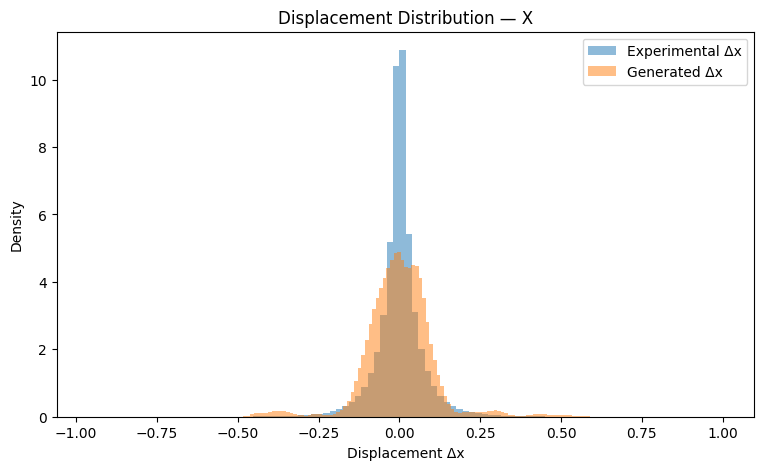

In [97]:
plt.figure(figsize=(9, 5))

plt.hist(real_dx, bins=100, density=True, alpha=0.5, label="Experimental Δx")
plt.hist(gen_dx, bins=100, density=True, alpha=0.5, label="Generated Δx")

plt.xlabel("Displacement Δx")
plt.ylabel("Density")
plt.title("Displacement Distribution — X")
plt.legend()
plt.show()

In [98]:
real_dx = np.diff(real_all[:, :, 0], axis=1)
real_dy = np.diff(real_all[:, :, 1], axis=1)

gen_dx = np.diff(generated_all_np[:, :, 0], axis=1)
gen_dy = np.diff(generated_all_np[:, :, 1], axis=1)

print("DISPLACEMENT STATISTICS")

print("\nREAL")
print("Mean:", [real_dx.mean(), real_dy.mean()])
print("Variance:", [real_dx.var(), real_dy.var()])
print("Std:", [real_dx.std(), real_dy.std()])
print("Median:", [np.median(real_dx), np.median(real_dy)])

print("\nGENERATED")
print("Mean:", [gen_dx.mean(), gen_dy.mean()])
print("Variance:", [gen_dx.var(), gen_dy.var()])
print("Std:", [gen_dx.std(), gen_dy.std()])
print("Median:", [np.median(gen_dx), np.median(gen_dy)])

DISPLACEMENT STATISTICS

REAL
Mean: [np.float32(0.0003238458), np.float32(0.00014327481)]
Variance: [np.float32(0.0053434805), np.float32(0.0051533473)]
Std: [np.float32(0.073099114), np.float32(0.07178682)]
Median: [np.float32(6.7964196e-05), np.float32(0.0)]

GENERATED
Mean: [np.float32(0.0002494709), np.float32(0.0003115716)]
Variance: [np.float32(0.011834592), np.float32(0.011133052)]
Std: [np.float32(0.10878691), np.float32(0.10551328)]
Median: [np.float32(-6.957352e-05), np.float32(0.00059339404)]


"The reproduced model generates physically structured trajectories with near-zero mean displacement, while the displacement variance remains higher than the experimental data. This establishes the baseline and identifies statistical mismatch for further refinement."

In [99]:
real_ac_x, real_ac_y = normalized_autocorrelation(
    real_all,
    max_lag=50
)

gen_ac_x, gen_ac_y = normalized_autocorrelation(
    generated_all_np,
    max_lag=50
)

print("Real X first 10:", real_ac_x[:10])
print("Gen  X first 10:", gen_ac_x[:10])

print("Real Y first 10:", real_ac_y[:10])
print("Gen  Y first 10:", gen_ac_y[:10])

Real X first 10: [ 1.         -0.28383484 -0.02578487 -0.00962098 -0.00847783 -0.00419018
 -0.00458027 -0.00288312 -0.0035619   0.00238657]
Gen  X first 10: [ 1.         -0.26890802 -0.01051359 -0.03088492  0.01312927 -0.01411068
 -0.0255016  -0.01715956 -0.00986396 -0.01171826]
Real Y first 10: [ 1.         -0.26789644 -0.02688584 -0.00644204 -0.00733207 -0.00699146
 -0.0061315  -0.00237357 -0.00341446 -0.00470368]
Gen  Y first 10: [ 1.0000000e+00 -2.5450698e-01  6.1780697e-04 -4.4433475e-02
 -3.1751764e-03 -1.5109490e-02 -1.6445972e-02 -1.4627525e-02
  5.0702109e-04 -3.1822415e-03]


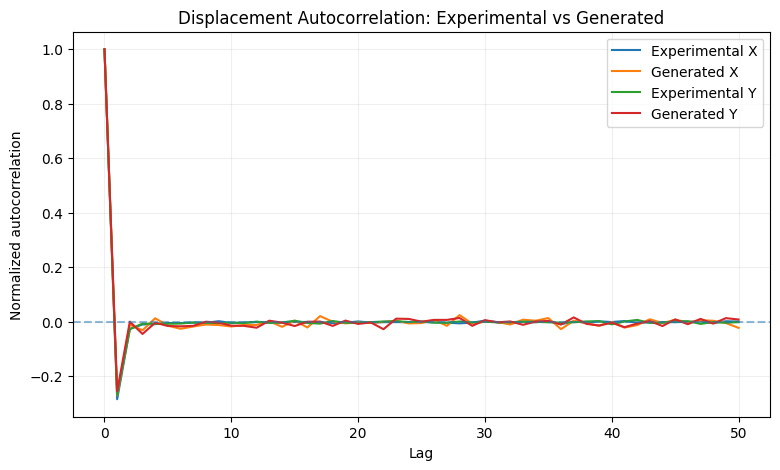

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(real_ac_x, label="Experimental X")
plt.plot(gen_ac_x, label="Generated X")

plt.plot(real_ac_y, label="Experimental Y")
plt.plot(gen_ac_y, label="Generated Y")

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Lag")
plt.ylabel("Normalized autocorrelation")
plt.title("Displacement Autocorrelation: Experimental vs Generated")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [101]:

import os
import torch

# 1. Verify that the required objects still exist
required = ["model", "train_loader", "val_loader"]

for name in required:
    print(f"{name} exists:", name in globals())

assert all(name in globals() for name in required), (
    "A required variable is missing. Check the notebook cells "
    "that created your model and data loaders."
)

# 2. Inspect the current model and data
print("\nModel:", type(model).__name__)
print("Model device:", next(model.parameters()).device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

batch = next(iter(train_loader))
print("Training batch shape:", batch.shape)

# 3. Save the current model weights
save_dir = "/kaggle/working/LEONARDO/checkpoints"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(save_dir, "baseline_epoch2.pt")

checkpoint = {
    "model_state_dict": model.state_dict(),
    "completed_epochs": 2,
    "baseline_train_loss": 6.32,
    "baseline_val_loss": 7.46,
}

# Preserve optimizer state if it is available
if "optimizer" in globals():
    checkpoint["optimizer_state_dict"] = optimizer.state_dict()

torch.save(checkpoint, checkpoint_path)

print("\nBaseline checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / 1e6, 2))


model exists: True
train_loader exists: True
val_loader exists: True

Model: TransformerVAE
Model device: cuda:0
Training batches: 599
Validation batches: 51
Training batch shape: torch.Size([64, 200, 2])

Baseline checkpoint saved: /kaggle/working/LEONARDO/checkpoints/baseline_epoch2.pt
File size (MB): 105.86


In [102]:
import torch
import os

checkpoint_path = "/kaggle/working/LEONARDO/checkpoints/baseline_epoch2.pt"

# Load checkpoint safely (it contains model/optimizer state dictionaries)
ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

print("Checkpoint keys:", list(ckpt.keys()))
print("Completed epochs recorded:", ckpt.get("completed_epochs"))
print("Saved baseline train loss:", ckpt.get("baseline_train_loss"))
print("Saved baseline validation loss:", ckpt.get("baseline_val_loss"))
print("Optimizer state saved:", "optimizer_state_dict" in ckpt)

# Verify checkpoint weights match the model currently in memory
saved_state = ckpt["model_state_dict"]
current_state = model.state_dict()

same_keys = saved_state.keys() == current_state.keys()
same_weights = same_keys and all(
    torch.equal(saved_state[k].cpu(), current_state[k].cpu())
    for k in saved_state
)

print("Checkpoint architecture matches current model:", same_keys)
print("Checkpoint weights match current model:", same_weights)

if "optimizer_state_dict" in ckpt and "optimizer" in globals():
    print("Optimizer state entries:", len(ckpt["optimizer_state_dict"]["state"]))
else:
    print("No optimizer state available for resuming.")

Checkpoint keys: ['model_state_dict', 'completed_epochs', 'baseline_train_loss', 'baseline_val_loss', 'optimizer_state_dict']
Completed epochs recorded: 2
Saved baseline train loss: 6.32
Saved baseline validation loss: 7.46
Optimizer state saved: True
Checkpoint architecture matches current model: True
Checkpoint weights match current model: True
Optimizer state entries: 66


In [103]:
import inspect

# 1. Check the training method's exact arguments
print("train_Leonardo signature:")
print(inspect.signature(model.train_Leonardo))

# 2. Inspect the method implementation
print("\ntrain_Leonardo source:")
source = inspect.getsource(model.train_Leonardo)
print(source[:12000])  # cap output if the method is long

# 3. Check optimizer and learning rate
print("\nOptimizer:", type(optimizer).__name__)
for i, group in enumerate(optimizer.param_groups):
    print(
        f"Param group {i}: lr={group.get('lr')}, "
        f"weight_decay={group.get('weight_decay')}, "
        f"betas={group.get('betas')}"
    )

# 4. Restore optimizer state from the verified checkpoint
ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
optimizer.load_state_dict(ckpt["optimizer_state_dict"])
print("\nOptimizer state restored from checkpoint.")

train_Leonardo signature:
(epochs, dataloader, optimizer, device, val_loader=None)

train_Leonardo source:
    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
            None
        """

        total_epochs = self.epochs + epochs

        for epoch in range(epochs):
            # Train data
            loss_epoch, loss_kl_training, loss_mse_training, loss_kurtosis_training, loss_skewness_training, \
                loss_variance_training, loss_mean_training, loss_acorr_training

In [104]:
import inspect

source = inspect.getsource(model.train_Leonardo)

print("=== End of train_Leonardo ===")
print(source[-3500:])

print("\n=== Model epoch counter ===")
print("model.epochs =", getattr(model, "epochs", "attribute not found"))

print("\n=== Existing loss-history lengths ===")
for attr in [
    "training_loss_per_epoch",
    "validation_loss_per_epoch",
    "training_mse_loss_per_epoch",
]:
    value = getattr(model, attr, None)
    print(attr, "=", None if value is None else len(value))

=== End of train_Leonardo ===
   self.validation_median_loss_per_epoch = np.append(self.validation_median_loss_per_epoch, loss_median_val/valset_size)
                self.validation_acorr_loss_per_epoch = np.append(self.validation_acorr_loss_per_epoch, loss_acorr_val/valset_size)
                self.validation_acorr_batch_loss_per_epoch = np.append(self.validation_acorr_batch_loss_per_epoch, loss_acorr_batch_val/valset_size)
                self.validation_xycorr_loss_per_epoch = np.append(self.validation_xycorr_loss_per_epoch, loss_xycorr_val/valset_size)
                self.validation_pos_acorr_loss_per_epoch = np.append(self.validation_pos_acorr_loss_per_epoch, loss_pos_acorr_val/valset_size)              
            self.epochs += 1
            
            # Print losses during training
            print(
                '\nepoch [{}/{}], Training loss:{:.2f}, KL-div training loss:{:.1f}, MSE training loss:{:.2f}, '
                'Kurtosis training loss:{:.2f}, Skewness trai

In [105]:
import os
import torch

# Align the model's internal counter with the verified checkpoint
model.epochs = 2

device = torch.device("cuda:0")
model.train()

print("Starting from recorded epoch:", model.epochs)
print("Batch size:", train_loader.batch_size)
print("GPU:", torch.cuda.get_device_name(device))

# Train exactly one more epoch; validation runs inside this method
model.train_Leonardo(
    epochs=1,
    dataloader=train_loader,
    optimizer=optimizer,
    device=device,
    val_loader=val_loader
)

# Save immediately after the epoch completes
completed_epochs = model.epochs
save_dir = "/kaggle/working/LEONARDO/checkpoints"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(
    save_dir, f"baseline_epoch{completed_epochs}.pt"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "completed_epochs": completed_epochs,
    "training_loss_history": model.training_loss_per_epoch,
    "validation_loss_history": model.validation_loss_per_epoch,
}, checkpoint_path)

print("\nSaved:", checkpoint_path)
print("Completed epochs:", completed_epochs)
print("Latest train loss:", model.training_loss_per_epoch[-1])
print("Latest validation loss:", model.validation_loss_per_epoch[-1])
print("Checkpoint size (MB):", round(os.path.getsize(checkpoint_path) / 1e6, 2))

Starting from recorded epoch: 2
Batch size: 64
GPU: Tesla T4

epoch [3/3], Training loss:6.29, KL-div training loss:6.0, MSE training loss:0.02, Kurtosis training loss:15.50, Skewness training loss (x10e3):330.46, Var training loss (x10e5):6.03, Mean training loss (x10e7):18.06, Median training loss (x10e7):291.25,acorr training loss (x10e3):0.92, acorr batch training loss (x10e4):7.41, xycorr factor training loss (x10e3): 35.335,pos acorr training loss (x10e3): 292.452
Validation loss:7.24, KL-div val loss:6.3, MSE val loss:0.02, Kurtosis val loss:14.59, Skewness val loss (x10e3):378.90, Var val loss (x10e5):5.88, Mean val loss (x10e7):14.66, Median val loss (x10e7):223.25, acorr val loss (x10e3):0.83, acorr batch val loss (x10e4):37.78, xycorr val loss (x10e3): 65.870, pos acorr val loss (x10e3): 287.308
model training completed

Saved: /kaggle/working/LEONARDO/checkpoints/baseline_epoch3.pt
Completed epochs: 3
Latest train loss: 6.293049200496914
Latest validation loss: 7.2386421832

In [106]:
import os
import torch

device = torch.device("cuda:0")
save_dir = "/kaggle/working/LEONARDO/checkpoints"
os.makedirs(save_dir, exist_ok=True)

# Continue from the epoch-3 model and optimizer already in memory
assert model.epochs == 3, f"Expected epoch 3, got {model.epochs}"

for _ in range(5):
    model.train_Leonardo(
        epochs=1,
        dataloader=train_loader,
        optimizer=optimizer,
        device=device,
        val_loader=val_loader
    )

    completed_epochs = model.epochs
    checkpoint_path = os.path.join(
        save_dir, f"baseline_epoch{completed_epochs}.pt"
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "completed_epochs": completed_epochs,
        "training_loss_history": model.training_loss_per_epoch,
        "validation_loss_history": model.validation_loss_per_epoch,
    }, checkpoint_path)

    print(
        f"\nCheckpoint saved at epoch {completed_epochs}: "
        f"{checkpoint_path}"
    )


epoch [4/4], Training loss:5.48, KL-div training loss:7.2, MSE training loss:0.02, Kurtosis training loss:13.00, Skewness training loss (x10e3):271.26, Var training loss (x10e5):5.24, Mean training loss (x10e7):17.27, Median training loss (x10e7):321.41,acorr training loss (x10e3):0.83, acorr batch training loss (x10e4):7.24, xycorr factor training loss (x10e3): 32.520,pos acorr training loss (x10e3): 282.182
Validation loss:7.41, KL-div val loss:6.8, MSE val loss:0.02, Kurtosis val loss:15.05, Skewness val loss (x10e3):387.87, Var val loss (x10e5):5.48, Mean val loss (x10e7):13.52, Median val loss (x10e7):327.23, acorr val loss (x10e3):0.83, acorr batch val loss (x10e4):41.56, xycorr val loss (x10e3): 66.407, pos acorr val loss (x10e3): 278.129
model training completed

Checkpoint saved at epoch 4: /kaggle/working/LEONARDO/checkpoints/baseline_epoch4.pt

epoch [5/5], Training loss:4.99, KL-div training loss:7.9, MSE training loss:0.02, Kurtosis training loss:11.31, Skewness training 

In [108]:
import inspect

print("=== forward() implementation ===")
print(inspect.getsource(model.forward))

print("\n=== Model methods related to encoding/decoding ===")
for name in dir(model):
    if any(key in name.lower() for key in ["encode", "decode", "latent", "sample"]):
        attr = getattr(model, name)
        if callable(attr):
            print(f"\n--- {name} ---")
            try:
                print(inspect.getsource(attr)[:5000])
            except (OSError, TypeError):
                print("Source unavailable; callable:", attr)

print("\n=== Model epoch counter ===")
print("model.epochs =", model.epochs)

=== forward() implementation ===
    def forward(self, src):
        """
        Forward pass through the TransformerVAE model.
        
        Args:
            src (tensor): Input trajectories (batch_size, sequence_length, 2).
            
        Returns:
            tuple: Encoded latent vector, mean, log variance, and decoded output.
        """
        enc_src, mu, logvar = self.encoder(src)
        out = self.decoder(enc_src)

        return enc_src, mu, logvar, out


=== Model methods related to encoding/decoding ===

--- decoder ---
Source unavailable; callable: Decoder(
  (linear1): Linear(in_features=12, out_features=1024, bias=True)
  (bottleneck_decoding): Bottleneck_Decoding(
    (linear1): Linear(in_features=1024, out_features=6400, bias=True)
    (convtranspose1): ConvTranspose1d(32, 128, kernel_size=(7,), stride=(1,), padding=(3,))
  )
  (layers): ModuleList(
    (0-1): 2 x DecoderBlock(
      (attention): SelfAttention(
        (values): Linear(in_features=128, out_f

In [110]:
import numpy as np
import torch

model.eval()

real_batches = []
recon_batches = []

with torch.no_grad():
    for batch in test_loader:
        # Handle datasets that return either a tensor or (tensor, label, ...)
        x = batch[0] if isinstance(batch, (tuple, list)) else batch
        x = x.to(device).float()

        _, mu, logvar, out = model(x)

        # Ensure trajectories are shaped (batch, time, 2)
        if out.ndim == 3 and out.shape[1] == 2 and out.shape[2] != 2:
            out = out.transpose(1, 2)

        if x.ndim == 3 and x.shape[1] == 2 and x.shape[2] != 2:
            x = x.transpose(1, 2)

        real_batches.append(x.cpu())
        recon_batches.append(out.cpu())

real = torch.cat(real_batches).numpy()
recon = torch.cat(recon_batches).numpy()

print("Real shape:", real.shape)
print("Reconstruction shape:", recon.shape)


def motion_metrics(trajectories):
    # Frame-to-frame displacement: (samples, time-1, x/y)
    d = np.diff(trajectories, axis=1)

    metrics = {
        "mean_dx": d[..., 0].mean(),
        "mean_dy": d[..., 1].mean(),
        "std_dx": d[..., 0].std(),
        "std_dy": d[..., 1].std(),
    }

    # Average within-trajectory displacement autocorrelation.
    # Center each trajectory's displacement series before computing it.
    for lag in [1, 2, 5, 10]:
        if lag >= d.shape[1]:
            continue

        values = []
        for coord in range(2):
            series = d[..., coord]
            centered = series - series.mean(axis=1, keepdims=True)

            numerator = (
                centered[:, :-lag] * centered[:, lag:]
            ).mean(axis=1)

            denominator = (
                centered ** 2
            ).mean(axis=1) + 1e-12

            values.append((numerator / denominator).mean())

        metrics[f"disp_acf_lag{lag}_x"] = values[0]
        metrics[f"disp_acf_lag{lag}_y"] = values[1]

    return metrics


real_metrics = motion_metrics(real)
recon_metrics = motion_metrics(recon)

print("\n=== Real test trajectories ===")
for key, value in real_metrics.items():
    print(f"{key}: {value:.6f}")

print("\n=== Reconstructed test trajectories ===")
for key, value in recon_metrics.items():
    print(f"{key}: {value:.6f}")

print("\n=== Reconstruction MSE ===")
print(f"{np.mean((real - recon) ** 2):.6f}")

Real shape: (5934, 200, 2)
Reconstruction shape: (5934, 200, 2)

=== Real test trajectories ===
mean_dx: 0.000324
mean_dy: 0.000143
std_dx: 0.073099
std_dy: 0.071787
disp_acf_lag1_x: -0.197118
disp_acf_lag1_y: -0.186030
disp_acf_lag2_x: -0.025511
disp_acf_lag2_y: -0.024380
disp_acf_lag5_x: -0.007561
disp_acf_lag5_y: -0.008636
disp_acf_lag10_x: -0.003435
disp_acf_lag10_y: -0.007060

=== Reconstructed test trajectories ===
mean_dx: 0.000308
mean_dy: -0.000275
std_dx: 0.096686
std_dy: 0.100082
disp_acf_lag1_x: -0.201927
disp_acf_lag1_y: -0.220985
disp_acf_lag2_x: 0.004106
disp_acf_lag2_y: -0.002501
disp_acf_lag5_x: -0.021244
disp_acf_lag5_y: -0.014286
disp_acf_lag10_x: -0.009067
disp_acf_lag10_y: -0.008435

=== Reconstruction MSE ===
0.769440


Real: min=0.0000, max=1.0000, mean=0.4208, std=0.2460
Reconstruction: min=-1.4819, max=0.9745, mean=-0.2552, std=0.4845

Per-trajectory MSE:
median: 0.7595027
90th percentile: 0.9682948
95th percentile: 1.0158831
max: 1.310614


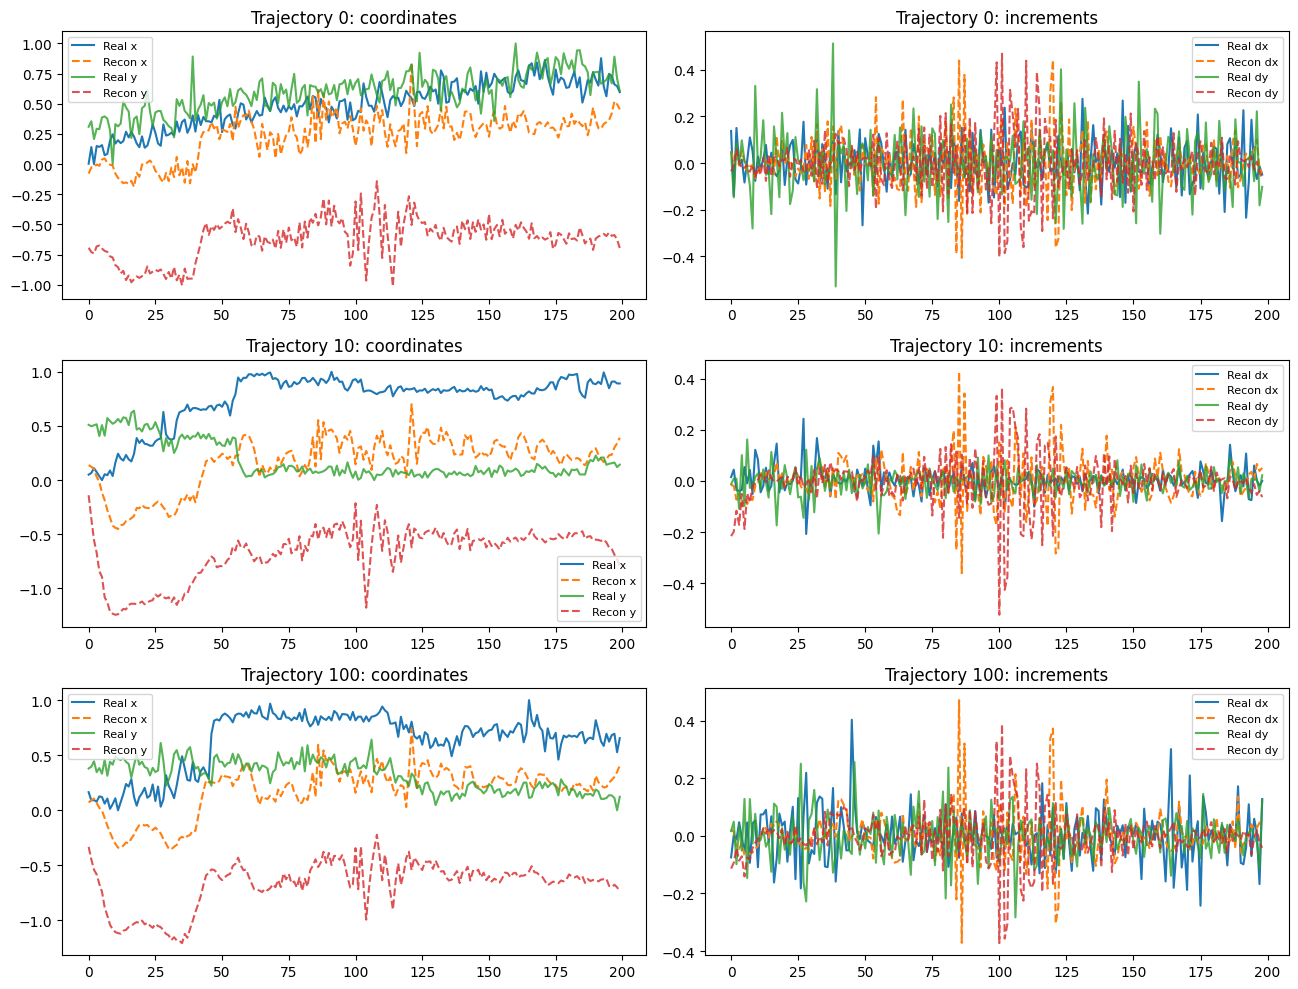

In [111]:
import numpy as np
import matplotlib.pyplot as plt

# Basic coordinate-scale check
for name, arr in [("Real", real), ("Reconstruction", recon)]:
    print(
        f"{name}: min={arr.min():.4f}, max={arr.max():.4f}, "
        f"mean={arr.mean():.4f}, std={arr.std():.4f}"
    )

per_traj_mse = np.mean((real - recon) ** 2, axis=(1, 2))
print("\nPer-trajectory MSE:")
print("median:", np.median(per_traj_mse))
print("90th percentile:", np.percentile(per_traj_mse, 90))
print("95th percentile:", np.percentile(per_traj_mse, 95))
print("max:", per_traj_mse.max())

# Plot three examples: positions and frame-to-frame increments
example_ids = [0, 10, 100]

fig, axes = plt.subplots(len(example_ids), 2, figsize=(13, 10))

for row, idx in enumerate(example_ids):
    # Position coordinates over time
    axes[row, 0].plot(real[idx, :, 0], label="Real x")
    axes[row, 0].plot(recon[idx, :, 0], "--", label="Recon x")
    axes[row, 0].plot(real[idx, :, 1], label="Real y", alpha=0.8)
    axes[row, 0].plot(recon[idx, :, 1], "--", label="Recon y", alpha=0.8)
    axes[row, 0].set_title(f"Trajectory {idx}: coordinates")
    axes[row, 0].legend(fontsize=8)

    # Displacements over time
    real_d = np.diff(real[idx], axis=0)
    recon_d = np.diff(recon[idx], axis=0)

    axes[row, 1].plot(real_d[:, 0], label="Real dx")
    axes[row, 1].plot(recon_d[:, 0], "--", label="Recon dx")
    axes[row, 1].plot(real_d[:, 1], label="Real dy", alpha=0.8)
    axes[row, 1].plot(recon_d[:, 1], "--", label="Recon dy", alpha=0.8)
    axes[row, 1].set_title(f"Trajectory {idx}: increments")
    axes[row, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [112]:
import inspect
import torch

print("=== Dataset class ===")
dataset = test_loader.dataset
print(type(dataset))
try:
    print(inspect.getsource(type(dataset)))
except (OSError, TypeError):
    print("Dataset source unavailable.")

print("\n=== Test dataset sample ===")
sample = dataset[0]
x0 = sample[0] if isinstance(sample, (tuple, list)) else sample
x0 = torch.as_tensor(x0).float()
print("sample shape:", tuple(x0.shape))
print("min / max / mean / std:",
      x0.min().item(), x0.max().item(),
      x0.mean().item(), x0.std().item())

print("\n=== Training method ===")
try:
    print(inspect.getsource(type(model).train_Leonardo)[:14000])
except (OSError, TypeError, AttributeError):
    print("Could not retrieve train_Leonardo source.")

print("\n=== Encoder forward ===")
try:
    print(inspect.getsource(type(model.encoder).forward))
except (OSError, TypeError):
    print("Encoder forward source unavailable.")

print("\n=== Decoder forward ===")
try:
    print(inspect.getsource(type(model.decoder).forward))
except (OSError, TypeError):
    print("Decoder forward source unavailable.")

=== Dataset class ===
<class 'torch.Tensor'>
Dataset source unavailable.

=== Test dataset sample ===
sample shape: (200, 2)
min / max / mean / std: 0.0 1.0 0.5429840683937073 0.18613334000110626

=== Training method ===
    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
            None
        """

        total_epochs = self.epochs + epochs

        for epoch in range(epochs):
            # Train data
            loss_epoch, loss_kl_training, loss_mse_training, loss_kurtosis_t

In [113]:
import torch
import numpy as np

model.eval()

sum_dx_mse = 0.0
n_samples = 0

with torch.no_grad():
    for batch in test_loader:
        x = batch[0] if isinstance(batch, (tuple, list)) else batch
        x = x.to(device).float()

        _, z_mean, z_log_var, decoded = model(x)

        x_dx = x[:, 1:, :] - x[:, :-1, :]
        decoded_dx = decoded[:, 1:, :] - decoded[:, :-1, :]

        batch_mse = ((decoded_dx - x_dx) ** 2).mean()
        sum_dx_mse += batch_mse.item() * len(x)
        n_samples += len(x)

print("Test displacement MSE:", sum_dx_mse / n_samples)

Test displacement MSE: 0.014919718386894792


In [114]:
print("=== Displacement MSE history ===")
print("Train:", model.training_mse_loss_per_epoch)
print("Validation:", model.validation_mse_loss_per_epoch)

print("\n=== Configured loss weights ===")
print(model.loss_weights)

=== Displacement MSE history ===
Train: [0.02160761 0.01759686 0.01739915 0.01719135 0.01707557 0.01689423
 0.01670275]
Validation: [0.01659278 0.01558164 0.01559226 0.01480803 0.01444788 0.01467326
 0.01495029]

=== Configured loss weights ===
{'kurt_factor': 0.06, 'skew_factor': 10, 'var_factor': 500, 'mean_factor': 50000, 'median_factor': 1, 'acorr_factor': 1000, 'mse_factor': 0.001, 'kl_factor': 0.05, 'acorr_batch_factor': 100, 'xycorr_factor': 10, 'pos_acorr_factor': 1}


In [115]:
history_names = [
    "training_loss_per_epoch",
    "validation_loss_per_epoch",
    "training_kl_loss_per_epoch",
    "validation_kl_loss_per_epoch",
    "training_mse_loss_per_epoch",
    "validation_mse_loss_per_epoch",
    "training_kurtosis_loss_per_epoch",
    "validation_kurtosis_loss_per_epoch",
    "training_skewness_loss_per_epoch",
    "validation_skewness_loss_per_epoch",
    "training_variance_loss_per_epoch",
    "validation_variance_loss_per_epoch",
    "training_mean_loss_per_epoch",
    "validation_mean_loss_per_epoch",
    "training_median_loss_per_epoch",
    "validation_median_loss_per_epoch",
    "training_acorr_loss_per_epoch",
    "validation_acorr_loss_per_epoch",
    "training_acorr_batch_loss_per_epoch",
    "validation_acorr_batch_loss_per_epoch",
    "training_xycorr_loss_per_epoch",
    "validation_xycorr_loss_per_epoch",
    "training_pos_acorr_loss_per_epoch",
    "validation_pos_acorr_loss_per_epoch",
]

print("model.epochs =", model.epochs)

for name in history_names:
    values = getattr(model, name, None)
    if values is not None:
        arr = np.asarray(values)
        print(f"{name} | n={len(arr)} | values={np.round(arr, 6)}")
    else:
        print(name, "| attribute not found")

model.epochs = 8
training_loss_per_epoch | n=7 | values=[7.965367 6.293049 5.480261 4.985879 4.609025 4.039567 3.446584]
validation_loss_per_epoch | n=7 | values=[7.856132 7.238642 7.405277 7.445744 6.947609 5.904056 5.255627]
training_kl_loss_per_epoch | n=7 | values=[4.73027  6.002783 7.222527 7.875541 8.204059 8.460518 8.790625]
validation_kl_loss_per_epoch | n=7 | values=[4.658236 6.347333 6.814368 7.663216 7.500203 7.672409 7.76098 ]
training_mse_loss_per_epoch | n=7 | values=[0.021608 0.017597 0.017399 0.017191 0.017076 0.016894 0.016703]
validation_mse_loss_per_epoch | n=7 | values=[0.016593 0.015582 0.015592 0.014808 0.014448 0.014673 0.01495 ]
training_kurtosis_loss_per_epoch | n=7 | values=[18.777612 15.50364  13.002496 11.307148 10.028377  8.622546  7.373627]
validation_kurtosis_loss_per_epoch | n=7 | values=[15.055613 14.590036 15.052874 14.484923 13.672875 12.101273 11.135049]
training_skewness_loss_per_epoch | n=7 | values=[0.451778 0.330462 0.27126  0.23918  0.216122 0.1

In [116]:
import inspect

print("=== Reparameterization ===")
try:
    print(inspect.getsource(type(model.encoder).reparameterize))
except (OSError, TypeError, AttributeError):
    print("Could not retrieve reparameterize source.")

print("\n=== Checkpoint metadata ===")
ckpt = torch.load(
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8.pt",
    map_location="cpu",
    weights_only=False
)

for key, value in ckpt.items():
    if "state_dict" not in key and not isinstance(value, dict):
        print(key, "=", value)

=== Reparameterization ===
    def reparameterize(self, mu, logvar, eps_scale=1):
        """
        Applies the reparameterization trick to create latent vectors.

        Args:
            mu (tensor): Mean of the latent distribution.
            logvar (tensor): Log variance of the latent distribution.
            eps_scale (float): Scaling factor for noise.

        Returns:
            tensor: Sampled latent vector using the reparameterization trick.
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std) * eps_scale
        return mu + eps * std


=== Checkpoint metadata ===
completed_epochs = 8
training_loss_history = [7.96536706 6.2930492  5.48026107 4.98587883 4.60902469 4.03956657
 3.44658353]
validation_loss_history = [7.85613248 7.23864218 7.40527725 7.44574373 6.94760905 5.90405614
 5.25562655]


In [117]:
import torch

@torch.no_grad()
def evaluate_mu_decode(loader, model, device):
    model.eval()
    squared_error_sum = 0.0
    sample_count = 0

    for batch in loader:
        x = batch[0] if isinstance(batch, (tuple, list)) else batch
        x = x.to(device).float()

        # Encoder returns sampled latent, mean, log-variance.
        # Decode the mean to avoid latent sampling noise.
        _, mu, logvar = model.encoder(x)
        decoded = model.decoder(mu)

        x_dx = x[:, 1:, :] - x[:, :-1, :]
        decoded_dx = decoded[:, 1:, :] - decoded[:, :-1, :]

        # Same displacement-MSE definition used by LEONARDO's loss
        per_batch_mse = ((decoded_dx - x_dx) ** 2).mean()

        squared_error_sum += per_batch_mse.item() * len(x)
        sample_count += len(x)

    return squared_error_sum / sample_count

val_mu_mse = evaluate_mu_decode(val_loader, model, device)
test_mu_mse = evaluate_mu_decode(test_loader, model, device)

print("Deterministic mu-decode displacement MSE")
print("Validation:", val_mu_mse)
print("Test:", test_mu_mse)

Deterministic mu-decode displacement MSE
Validation: 0.014972692345042738
Test: 0.01496932262075763


In [119]:
import os
import torch

checkpoint_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8.pt"
)

assert os.path.exists(checkpoint_path), (
    f"Checkpoint not found: {checkpoint_path}"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", list(checkpoint.keys()))

print("Completed epochs:",
      checkpoint.get("completed_epochs", "Not found"))

print("Model state available:",
      checkpoint.get("model_state_dict") is not None)

print("Optimizer state available:",
      checkpoint.get("optimizer_state_dict") is not None)

print("Device:", device)

print("Train history entries:",
      len(checkpoint.get("train_history", [])))

print("Validation history entries:",
      len(checkpoint.get("val_history", [])))

Checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
Completed epochs: 8
Model state available: True
Optimizer state available: True
Device: cuda
Train history entries: 0
Validation history entries: 0


In [120]:
# Inspect saved loss histories
print("Completed epochs:", checkpoint["completed_epochs"])

print("\nTraining history:")
print(checkpoint["training_loss_history"])

print("\nValidation history:")
print(checkpoint["validation_loss_history"])

# Inspect model and optimizer configuration
print("\nModel class:", type(model).__name__)
print("Model epochs:", getattr(model, "epochs", "Not found"))
print("Optimizer class:", type(optimizer).__name__)

# Inspect the training function signature
import inspect

print("Model class:", type(model).__name__)

print("\ntrain_Leonardo signature:")
print(inspect.signature(model.train_Leonardo))

print("\ntrain_Leonardo source:")
print(inspect.getsource(model.train_Leonardo))

Completed epochs: 8

Training history:
[7.96536706 6.2930492  5.48026107 4.98587883 4.60902469 4.03956657
 3.44658353]

Validation history:
[7.85613248 7.23864218 7.40527725 7.44574373 6.94760905 5.90405614
 5.25562655]

Model class: TransformerVAE
Model epochs: 8
Optimizer class: Adam
Model class: TransformerVAE

train_Leonardo signature:
(epochs, dataloader, optimizer, device, val_loader=None)

train_Leonardo source:
    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
          

NameError: name 'train_Leonardo' is not defined

In [122]:
import os

repo = "/kaggle/working/LEONARDO"

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith(".py"):
            print(os.path.join(root, file))

/kaggle/working/LEONARDO/LEONARDO_utils.py
/kaggle/working/LEONARDO/LEONARDO_script.py
/kaggle/working/LEONARDO/LEONARDO_model.py
/kaggle/working/LEONARDO/MoNet2.0/monet2_train.py
/kaggle/working/LEONARDO/MoNet2.0/run_monet2_fd.py
/kaggle/working/LEONARDO/MoNet2.0/monet2_architecture.py
/kaggle/working/LEONARDO/MoNet2.0/models_theory.py
/kaggle/working/LEONARDO/MoNet2.0/run_monet2_classification.py
/kaggle/working/LEONARDO/MoNet2.0/utils_monet2.py
/kaggle/working/LEONARDO/MoNet2.0/utils_trajectories.py


In [123]:
import os

repo = "/kaggle/working/LEONARDO"

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8") as f:
                    lines = f.readlines()

                for i, line in enumerate(lines):
                    if "def train_Leonardo" in line:
                        print(f"\nFOUND: {path}, line {i+1}")
                        print("".join(lines[i:i+35]))
            except Exception:
                pass


FOUND: /kaggle/working/LEONARDO/LEONARDO_model.py, line 104
    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
            None
        """

        total_epochs = self.epochs + epochs

        for epoch in range(epochs):
            # Train data
            loss_epoch, loss_kl_training, loss_mse_training, loss_kurtosis_training, loss_skewness_training, \
                loss_variance_training, loss_mean_training, loss_acorr_training, \
                    loss_acorr_batch_train

In [124]:
import inspect

print("Model class:", type(model).__name__)
print("Epoch counter:", model.epochs)

print("\nTraining method:")
print(inspect.signature(model.train_Leonardo))

print("\nSaved training history:")
print(checkpoint["training_loss_history"])

print("\nSaved validation history:")
print(checkpoint["validation_loss_history"])

print("\nHistory attributes on model:")
for name in dir(model):
    if "history" in name.lower() or "loss" in name.lower():
        if not name.startswith("__"):
            print(name)

Model class: TransformerVAE
Epoch counter: 8

Training method:
(epochs, dataloader, optimizer, device, val_loader=None)

Saved training history:
[7.96536706 6.2930492  5.48026107 4.98587883 4.60902469 4.03956657
 3.44658353]

Saved validation history:
[7.85613248 7.23864218 7.40527725 7.44574373 6.94760905 5.90405614
 5.25562655]

History attributes on model:
loss_weights
plot_loss
training_acorr_batch_loss_per_epoch
training_acorr_loss_per_epoch
training_kl_loss_per_epoch
training_kurtosis_loss_per_epoch
training_loss_per_epoch
training_mean_loss_per_epoch
training_median_loss_per_epoch
training_mse_loss_per_epoch
training_pos_acorr_loss_per_epoch
training_skewness_loss_per_epoch
training_variance_loss_per_epoch
training_xycorr_loss_per_epoch
validation_acorr_batch_loss_per_epoch
validation_acorr_loss_per_epoch
validation_acorr_percentiles_loss_per_epoch
validation_kl_loss_per_epoch
validation_kurtosis_loss_per_epoch
validation_loss_per_epoch
validation_mean_jump_loss_per_epoch
valida

In [125]:
print("Epoch counter:", model.epochs)

attrs = [
    "training_loss_per_epoch",
    "validation_loss_per_epoch",
    "training_mse_loss_per_epoch",
    "validation_mse_loss_per_epoch",
]

for name in attrs:
    value = getattr(model, name, None)
    print(f"\n{name}:")
    print("  Type:", type(value).__name__)
    print("  Length:", len(value) if value is not None else "None")
    print("  Values:", value)

Epoch counter: 8

training_loss_per_epoch:
  Type: ndarray
  Length: 7
  Values: [7.96536706 6.2930492  5.48026107 4.98587883 4.60902469 4.03956657
 3.44658353]

validation_loss_per_epoch:
  Type: ndarray
  Length: 7
  Values: [7.85613248 7.23864218 7.40527725 7.44574373 6.94760905 5.90405614
 5.25562655]

training_mse_loss_per_epoch:
  Type: ndarray
  Length: 7
  Values: [0.02160761 0.01759686 0.01739915 0.01719135 0.01707557 0.01689423
 0.01670275]

validation_mse_loss_per_epoch:
  Type: ndarray
  Length: 7
  Values: [0.01659278 0.01558164 0.01559226 0.01480803 0.01444788 0.01467326
 0.01495029]


In [126]:
import inspect

source = inspect.getsource(model.train_Leonardo)
lines = source.splitlines()

print("\n".join(
    f"{i+1:03}: {line}"
    for i, line in enumerate(lines)
    if any(word in line.lower() for word in [
        "self.epochs",
        "total_epochs",
        "append",
        "concatenate",
        "np.array",
        "loss_per_epoch",
        "save"
    ])
))

016:         total_epochs = self.epochs + epochs
111:             #Append losses to their arrays
112:             self.training_loss_per_epoch = np.append(self.training_loss_per_epoch, loss_epoch/dataset_size)
113:             self.training_kl_loss_per_epoch = np.append(self.training_kl_loss_per_epoch, loss_kl_training/dataset_size)
114:             self.training_mse_loss_per_epoch = np.append(self.training_mse_loss_per_epoch, loss_mse_training/dataset_size)
115:             self.training_kurtosis_loss_per_epoch = np.append(self.training_kurtosis_loss_per_epoch, loss_kurtosis_training/dataset_size)
116:             self.training_skewness_loss_per_epoch = np.append(self.training_skewness_loss_per_epoch, loss_skewness_training/dataset_size)
117:             self.training_variance_loss_per_epoch = np.append(self.training_variance_loss_per_epoch, loss_variance_training/dataset_size)
118:             self.training_mean_loss_per_epoch = np.append(self.training_mean_loss_per_epoch, loss_mean_

In [127]:
import os
import shutil

checkpoint_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8.pt"
)

backup_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8_backup.pt"
)

assert os.path.exists(checkpoint_path), "Original checkpoint missing!"

if not os.path.exists(backup_path):
    shutil.copy2(checkpoint_path, backup_path)

print("Original checkpoint:", os.path.exists(checkpoint_path))
print("Backup checkpoint:", os.path.exists(backup_path))

Original checkpoint: True
Backup checkpoint: True


In [128]:
import torch
import os

assert os.path.exists(backup_path), "Backup missing!"
assert model.epochs == 8, f"Unexpected epoch counter: {model.epochs}"
assert len(model.training_loss_per_epoch) == 7
assert len(model.validation_loss_per_epoch) == 7

# Save current in-memory state in case we need to recover
before_epoch = model.epochs
before_train_len = len(model.training_loss_per_epoch)
before_val_len = len(model.validation_loss_per_epoch)

model.train_Leonardo(
    epochs=1,
    dataloader=train_loader,
    optimizer=optimizer,
    device=device,
    val_loader=val_loader
)

print("\nEpoch counter:", model.epochs)
print("Training history length:", len(model.training_loss_per_epoch))
print("Validation history length:", len(model.validation_loss_per_epoch))
print("Latest training loss:", model.training_loss_per_epoch[-1])
print("Latest validation loss:", model.validation_loss_per_epoch[-1])
print("Latest training MSE:", model.training_mse_loss_per_epoch[-1])
print("Latest validation MSE:", model.validation_mse_loss_per_epoch[-1])


epoch [9/9], Training loss:3.12, KL-div training loss:9.0, MSE training loss:0.02, Kurtosis training loss:6.50, Skewness training loss (x10e3):106.15, Var training loss (x10e5):3.39, Mean training loss (x10e7):14.88, Median training loss (x10e7):342.05,acorr training loss (x10e3):0.66, acorr batch training loss (x10e4):6.56, xycorr factor training loss (x10e3): 14.374,pos acorr training loss (x10e3): 258.049
Validation loss:4.81, KL-div val loss:8.1, MSE val loss:0.01, Kurtosis val loss:10.14, Skewness val loss (x10e3):185.93, Var val loss (x10e5):3.08, Mean val loss (x10e7):15.53, Median val loss (x10e7):268.32, acorr val loss (x10e3):0.72, acorr batch val loss (x10e4):37.02, xycorr val loss (x10e3): 48.378, pos acorr val loss (x10e3): 265.171
model training completed

Epoch counter: 9
Training history length: 8
Validation history length: 8
Latest training loss: 3.1207646151539947
Latest validation loss: 4.808414540835875
Latest training MSE: 0.016685486848681246
Latest validation MS

In [130]:
import os
import torch
import numpy as np

checkpoint_dir = "/kaggle/working/LEONARDO/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

epoch9_path = os.path.join(checkpoint_dir, "baseline_epoch9.pt")

# Preserve every per-epoch loss history currently held by the model
histories = {
    name: getattr(model, name).copy()
    for name in dir(model)
    if (
        "loss_per_epoch" in name
        and isinstance(getattr(model, name, None), np.ndarray)
    )
}

checkpoint_epoch9 = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "completed_epochs": model.epochs,
    "training_loss_history": model.training_loss_per_epoch.copy(),
    "validation_loss_history": model.validation_loss_per_epoch.copy(),
    "histories": histories,
}

torch.save(checkpoint_epoch9, epoch9_path)

# Verify the saved file
saved = torch.load(epoch9_path, map_location="cpu", weights_only=False)

assert saved["completed_epochs"] == 9
assert len(saved["training_loss_history"]) == 8
assert len(saved["validation_loss_history"]) == 8

print("Saved:", epoch9_path)
print("Completed epochs:", saved["completed_epochs"])
print("Training history entries:", len(saved["training_loss_history"]))
print("Validation history entries:", len(saved["validation_loss_history"]))
print("Component histories saved:", len(saved["histories"]))

Saved: /kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt
Completed epochs: 9
Training history entries: 8
Validation history entries: 8
Component histories saved: 26


In [131]:
import os
import torch

epoch9_path = "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt"

print("Current model epoch:", model.epochs)
print("Current train history length:", len(model.training_loss_per_epoch))
print("Current val history length:", len(model.validation_loss_per_epoch))

print("\nCheckpoint file exists:", os.path.exists(epoch9_path))

if os.path.exists(epoch9_path):
    saved = torch.load(
        epoch9_path,
        map_location="cpu",
        weights_only=False
    )

    print("Saved completed_epochs:", saved.get("completed_epochs"))
    print("Saved train history length:",
          len(saved.get("training_loss_history", [])))
    print("Saved val history length:",
          len(saved.get("validation_loss_history", [])))
    print("Saved checkpoint keys:", list(saved.keys()))

Current model epoch: 9
Current train history length: 8
Current val history length: 8

Checkpoint file exists: True
Saved completed_epochs: 9
Saved train history length: 8
Saved val history length: 8
Saved checkpoint keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history', 'histories']


In [132]:
import os
import torch

checkpoint_dir = "/kaggle/working/LEONARDO/checkpoints"

for filename in sorted(os.listdir(checkpoint_dir)):
    if filename.endswith(".pt") or filename.endswith(".pth"):
        path = os.path.join(checkpoint_dir, filename)

        try:
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            if isinstance(ckpt, dict):
                print(
                    filename,
                    "| epoch:", ckpt.get("completed_epochs", "unknown"),
                    "| keys:", list(ckpt.keys())
                )
        except Exception as e:
            print(filename, "| Could not inspect:", str(e))

baseline_epoch2.pt | epoch: 2 | keys: ['model_state_dict', 'completed_epochs', 'baseline_train_loss', 'baseline_val_loss', 'optimizer_state_dict']
baseline_epoch3.pt | epoch: 3 | keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
baseline_epoch4.pt | epoch: 4 | keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
baseline_epoch5.pt | epoch: 5 | keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
baseline_epoch6.pt | epoch: 6 | keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
baseline_epoch7.pt | epoch: 7 | keys: ['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history']
baseline_epoch8.pt | epoch: 8 | keys: ['model_state_dict', 'optimizer_state_di

In [133]:
import torch
import os

checkpoint_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8.pt"
)

ckpt = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
optimizer.load_state_dict(ckpt["optimizer_state_dict"])
model.epochs = ckpt["completed_epochs"]

print("Restored epoch:", model.epochs)
print("Optimizer:", type(optimizer).__name__)
print("Train loader exists:", "train_loader" in globals())
print("Validation loader exists:", "val_loader" in globals())
print("Device:", device)

Restored epoch: 8
Optimizer: Adam
Train loader exists: True
Validation loader exists: True
Device: cuda


In [134]:
import os
import torch
import numpy as np

# Preserve epoch 8 as the recovery point
checkpoint_dir = "/kaggle/working/LEONARDO/checkpoints"
epoch8_path = os.path.join(checkpoint_dir, "baseline_epoch8.pt")
epoch9_path = os.path.join(checkpoint_dir, "baseline_epoch9.pt")

assert os.path.exists(epoch8_path), "Epoch 8 checkpoint missing!"
assert model.epochs == 8, f"Expected epoch 8, got {model.epochs}"

# Train exactly one additional epoch
model.train_Leonardo(
    epochs=1,
    dataloader=train_loader,
    optimizer=optimizer,
    device=device,
    val_loader=val_loader
)

# Confirm that exactly one epoch completed
assert model.epochs == 9, f"Expected epoch 9, got {model.epochs}"

# Capture every per-epoch NumPy history
histories = {}
for name in dir(model):
    value = getattr(model, name, None)
    if "loss_per_epoch" in name and isinstance(value, np.ndarray):
        histories[name] = value.copy()

# Save model, optimizer, counter and histories
checkpoint_epoch9 = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "completed_epochs": int(model.epochs),
    "training_loss_history": model.training_loss_per_epoch.copy(),
    "validation_loss_history": model.validation_loss_per_epoch.copy(),
    "histories": histories,
}

torch.save(checkpoint_epoch9, epoch9_path)

# Verify the saved checkpoint
saved = torch.load(
    epoch9_path,
    map_location="cpu",
    weights_only=False
)

assert saved["completed_epochs"] == 9
assert len(saved["training_loss_history"]) == 8
assert len(saved["validation_loss_history"]) == 8

print("\nCheckpoint saved and verified:", epoch9_path)
print("Completed epochs:", saved["completed_epochs"])
print("Training history entries:", len(saved["training_loss_history"]))
print("Validation history entries:", len(saved["validation_loss_history"]))
print("Latest training loss:", saved["training_loss_history"][-1])
print("Latest validation loss:", saved["validation_loss_history"][-1])
print("Latest training MSE:", saved["histories"]["training_mse_loss_per_epoch"][-1])
print("Latest validation MSE:", saved["histories"]["validation_mse_loss_per_epoch"][-1])
print("Epoch 8 checkpoint still exists:", os.path.exists(epoch8_path))


epoch [9/9], Training loss:3.11, KL-div training loss:9.0, MSE training loss:0.02, Kurtosis training loss:6.40, Skewness training loss (x10e3):105.94, Var training loss (x10e5):3.38, Mean training loss (x10e7):14.94, Median training loss (x10e7):347.07,acorr training loss (x10e3):0.66, acorr batch training loss (x10e4):6.59, xycorr factor training loss (x10e3): 14.656,pos acorr training loss (x10e3): 258.455
Validation loss:4.94, KL-div val loss:8.3, MSE val loss:0.01, Kurtosis val loss:10.02, Skewness val loss (x10e3):200.50, Var val loss (x10e5):3.11, Mean val loss (x10e7):15.91, Median val loss (x10e7):284.56, acorr val loss (x10e3):0.72, acorr batch val loss (x10e4):38.28, xycorr val loss (x10e3): 45.194, pos acorr val loss (x10e3): 271.892
model training completed


AssertionError: 

In [135]:
import inspect

print("Model:", type(model).__name__)
print("Forward signature:", inspect.signature(model.forward))
print("Validation loader batches:", len(val_loader))
print("Device:", device)

Model: TransformerVAE
Forward signature: (src)
Validation loader batches: 51
Device: cuda


In [136]:

import torch
import numpy as np
import pandas as pd

ckpt_paths = {
    "Epoch 8": "/kaggle/working/LEONARDO/checkpoints/baseline_epoch8.pt",
    "Epoch 9": "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt",
}

# Preserve current notebook state
original_model_state = {
    k: v.detach().clone() for k, v in model.state_dict().items()
}
original_training_mode = model.training

def get_metrics(real, recon):
    # Expected shape: (N, T, 2)
    real = real.detach().float().cpu().numpy()
    recon = recon.detach().float().cpu().numpy()

    real_d = np.diff(real, axis=1)
    recon_d = np.diff(recon, axis=1)

    results = {
        "Displacement MSE": float(np.mean((real_d - recon_d) ** 2)),
        "Real X displacement std": float(real_d[..., 0].std()),
        "Recon X displacement std": float(recon_d[..., 0].std()),
        "Real Y displacement std": float(real_d[..., 1].std()),
        "Recon Y displacement std": float(recon_d[..., 1].std()),
    }

    def lag_corr(a, lag):
        a = a.reshape(-1)
        if len(a) <= lag:
            return np.nan
        x, y = a[:-lag], a[lag:]
        if x.std() < 1e-12 or y.std() < 1e-12:
            return np.nan
        return float(np.corrcoef(x, y)[0, 1])

    for lag in [1, 2, 5, 10]:
        results[f"Real X lag{lag}"] = lag_corr(real_d[..., 0], lag)
        results[f"Recon X lag{lag}"] = lag_corr(recon_d[..., 0], lag)

    results["Real XY corr"] = float(
        np.corrcoef(real_d[..., 0].ravel(), real_d[..., 1].ravel())[0, 1]
    )
    results["Recon XY corr"] = float(
        np.corrcoef(recon_d[..., 0].ravel(), recon_d[..., 1].ravel())[0, 1]
    )
    return results

comparison = []

try:
    model.eval()

    for label, path in ckpt_paths.items():
        checkpoint = torch.load(
            path, map_location=device, weights_only=False
        )
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        # Same random seed for a more controlled comparison
        torch.manual_seed(123)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(123)

        real_batches, recon_batches = [], []

        with torch.no_grad():
            for batch in val_loader:
                x = batch[0] if isinstance(batch, (tuple, list)) else batch
                x = x.to(device).float()

                output = model(x)
                recon = output[3]

                real_batches.append(x.cpu())
                recon_batches.append(recon.cpu())

        real = torch.cat(real_batches, dim=0)
        recon = torch.cat(recon_batches, dim=0)

        row = {"Checkpoint": label, **get_metrics(real, recon)}
        comparison.append(row)

        print(
            f"{label}: completed_epochs={checkpoint.get('completed_epochs')}, "
            f"validation trajectories={len(real)}"
        )

finally:
    model.load_state_dict(original_model_state)
    model.train(original_training_mode)

results_df = pd.DataFrame(comparison).set_index("Checkpoint").T
display(results_df.round(6))


Epoch 8: completed_epochs=8, validation trajectories=3202
Epoch 9: completed_epochs=9, validation trajectories=3202


Checkpoint,Epoch 8,Epoch 9
Displacement MSE,0.014976,0.014307
Real X displacement std,0.074013,0.074013
Recon X displacement std,0.095879,0.093134
Real Y displacement std,0.073565,0.073565
Recon Y displacement std,0.099688,0.095486
Real X lag1,-0.274370,-0.274370
Recon X lag1,-0.234972,-0.201475
Real X lag2,-0.020275,-0.020275
Recon X lag2,0.007516,-0.017624
Real X lag5,-0.008270,-0.008270


In [137]:

import torch
import numpy as np
import pandas as pd

def mean_corr_per_trajectory(a, b):
    values = []
    for i in range(len(a)):
        x = a[i].reshape(-1)
        y = b[i].reshape(-1)
        if x.std() > 1e-12 and y.std() > 1e-12:
            values.append(np.corrcoef(x, y)[0, 1])
    return float(np.nanmean(values)) if values else np.nan

def lag_corr_per_trajectory(data, lag):
    values = []
    for i in range(len(data)):
        x = data[i, :-lag].reshape(-1)
        y = data[i, lag:].reshape(-1)
        if x.std() > 1e-12 and y.std() > 1e-12:
            values.append(np.corrcoef(x, y)[0, 1])
    return float(np.nanmean(values)) if values else np.nan

def corrected_metrics(real, recon):
    real = real.numpy()
    recon = recon.numpy()

    rd = np.diff(real, axis=1)
    pd_ = np.diff(recon, axis=1)

    m = {
        "Displacement MSE": np.mean((rd - pd_) ** 2),
        "Real X displacement std": rd[..., 0].std(),
        "Recon X displacement std": pd_[..., 0].std(),
        "Real Y displacement std": rd[..., 1].std(),
        "Recon Y displacement std": pd_[..., 1].std(),
    }

    for lag in [1, 2, 5, 10]:
        m[f"Real X lag{lag}"] = lag_corr_per_trajectory(rd[..., 0], lag)
        m[f"Recon X lag{lag}"] = lag_corr_per_trajectory(pd_[..., 0], lag)
        m[f"Real Y lag{lag}"] = lag_corr_per_trajectory(rd[..., 1], lag)
        m[f"Recon Y lag{lag}"] = lag_corr_per_trajectory(pd_[..., 1], lag)

    m["Real XY corr"] = mean_corr_per_trajectory(rd[..., 0], rd[..., 1])
    m["Recon XY corr"] = mean_corr_per_trajectory(pd_[..., 0], pd_[..., 1])

    return m

original_state = {
    k: v.detach().clone() for k, v in model.state_dict().items()
}
original_mode = model.training

corrected_results = {}

try:
    model.eval()

    for label, path in ckpt_paths.items():
        ckpt = torch.load(path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()

        torch.manual_seed(123)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(123)

        real_batches, recon_batches = [], []

        with torch.no_grad():
            for batch in val_loader:
                x = batch[0] if isinstance(batch, (tuple, list)) else batch
                x = x.to(device).float()
                output = model(x)

                real_batches.append(x.cpu())
                recon_batches.append(output[3].cpu())

        real = torch.cat(real_batches)
        recon = torch.cat(recon_batches)

        corrected_results[label] = corrected_metrics(real, recon)
        print(label, "evaluated:", len(real), "trajectories")

finally:
    model.load_state_dict(original_state)
    model.train(original_mode)

corrected_df = pd.DataFrame(corrected_results)
display(corrected_df.round(6))

corrected_df.to_csv(
    "/kaggle/working/LEONARDO/checkpoints/epoch8_epoch9_corrected_metrics.csv"
)
print("Corrected metrics saved.")


Epoch 8 evaluated: 3202 trajectories
Epoch 9 evaluated: 3202 trajectories


,Epoch 8,Epoch 9
Displacement MSE,0.014976,0.014307
Real X displacement std,0.074013,0.074013
Recon X displacement std,0.095879,0.093134
Real Y displacement std,0.073565,0.073565
Recon Y displacement std,0.099688,0.095486
Real X lag1,-0.173289,-0.173289
Recon X lag1,-0.202993,-0.163468
Real Y lag1,-0.177901,-0.177901
Recon Y lag1,-0.222620,-0.191121
Real X lag2,-0.020497,-0.020497


Corrected metrics saved.


Test trajectories: 5934
Real shape: (5934, 200, 2)
Reconstruction shape: (5934, 200, 2)


,Epoch 9 Test Set
Displacement MSE,0.014410
Real X displacement std,0.073099
Recon X displacement std,0.094751
Real Y displacement std,0.071787
Recon Y displacement std,0.096737
Real X lag1,-0.197186
Recon X lag1,-0.167783
Real Y lag1,-0.186075
Recon Y lag1,-0.193935
Real X lag2,-0.025539


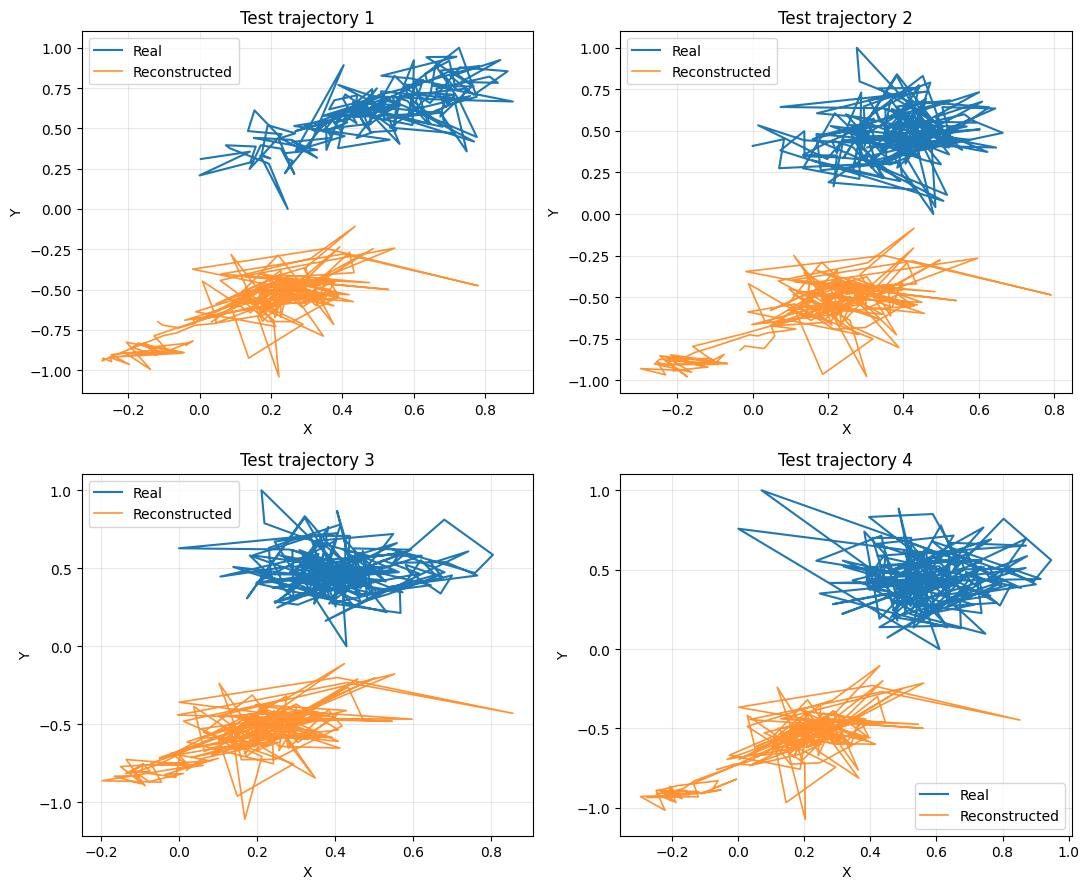

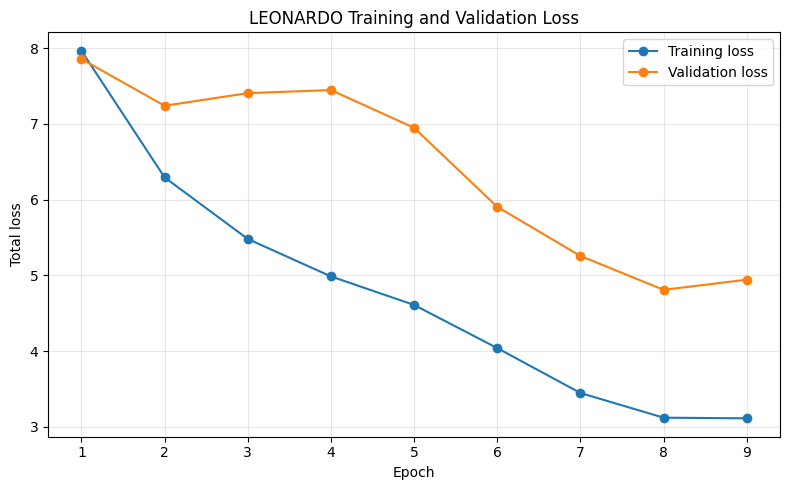


Saved results in: /kaggle/working/LEONARDO/final_results
Trajectory plot: /kaggle/working/LEONARDO/final_results/real_vs_reconstructed_trajectories.png


In [138]:

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

save_dir = "/kaggle/working/LEONARDO/final_results"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt"
)

# Preserve current model
original_state = {
    k: v.detach().clone() for k, v in model.state_dict().items()
}
original_mode = model.training

try:
    ckpt = torch.load(
        checkpoint_path, map_location=device, weights_only=False
    )
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    real_batches, recon_batches = [], []

    torch.manual_seed(123)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(123)

    with torch.no_grad():
        for batch in test_loader:
            x = batch[0] if isinstance(batch, (tuple, list)) else batch
            x = x.to(device).float()

            output = model(x)
            reconstruction = output[3]

            real_batches.append(x.cpu())
            recon_batches.append(reconstruction.cpu())

    test_real = torch.cat(real_batches, dim=0)
    test_recon = torch.cat(recon_batches, dim=0)

    print("Test trajectories:", len(test_real))
    print("Real shape:", tuple(test_real.shape))
    print("Reconstruction shape:", tuple(test_recon.shape))

    # Test-set metrics
    test_metrics = corrected_metrics(test_real, test_recon)
    test_df = pd.DataFrame(
        {"Epoch 9 Test Set": test_metrics}
    )
    display(test_df.round(6))

    test_df.to_csv(
        os.path.join(save_dir, "epoch9_test_metrics.csv")
    )

    # Plot 4 real vs reconstructed trajectories
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        ax.plot(
            test_real[i, :, 0],
            test_real[i, :, 1],
            label="Real",
            linewidth=1.5
        )
        ax.plot(
            test_recon[i, :, 0],
            test_recon[i, :, 1],
            label="Reconstructed",
            linewidth=1.2,
            alpha=0.85
        )
        ax.set_title(f"Test trajectory {i + 1}")
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    trajectory_path = os.path.join(
        save_dir, "real_vs_reconstructed_trajectories.png"
    )
    plt.savefig(trajectory_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    # Plot saved training and validation loss histories
    train_history = ckpt.get("training_loss_history", [])
    val_history = ckpt.get("validation_loss_history", [])

    if len(train_history) and len(val_history):
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(
            range(1, len(train_history) + 1),
            train_history,
            marker="o",
            label="Training loss"
        )
        ax.plot(
            range(1, len(val_history) + 1),
            val_history,
            marker="o",
            label="Validation loss"
        )
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Total loss")
        ax.set_title("LEONARDO Training and Validation Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()

        loss_path = os.path.join(save_dir, "loss_curves.png")
        plt.savefig(loss_path, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close()
    else:
        print("Loss histories not found in expected checkpoint keys.")

    print("\nSaved results in:", save_dir)
    print("Trajectory plot:", trajectory_path)

finally:
    model.load_state_dict(original_state)
    model.train(original_mode)


In [140]:

import torch
import numpy as np
import pandas as pd

real = test_real.detach().cpu().numpy()
recon = test_recon.detach().cpu().numpy()

rows = []

for axis, name in enumerate(["X", "Y"]):
    r = real[..., axis]
    p = recon[..., axis]

    rows.append({
        "Axis": name,
        "Real min": r.min(),
        "Real max": r.max(),
        "Real mean": r.mean(),
        "Real std": r.std(),
        "Recon min": p.min(),
        "Recon max": p.max(),
        "Recon mean": p.mean(),
        "Recon std": p.std(),
        "Mean offset (Recon - Real)": p.mean() - r.mean(),
        "Absolute coordinate MSE": np.mean((p - r) ** 2),
        "Recon outside [0,1] (%)": 100 * np.mean((p < 0) | (p > 1))
    })

display(pd.DataFrame(rows).set_index("Axis").round(6))

print("Overall absolute-coordinate MSE:",
      np.mean((recon - real) ** 2))

print("\nModel output activation / architecture:")
print(model)


,Real min,Real max,Real mean,Real std,Recon min,Recon max,Recon mean,Recon std,Mean offset (Recon - Real),Absolute coordinate MSE,"Recon outside [0,1] (%)"
Axis,,,,,,,,,,,
X,0.0,1.0,0.393437,0.245785,-0.694332,0.964947,0.098934,0.238154,-0.294502,0.194340,22.307381
Y,0.0,1.0,0.448088,0.243252,-1.398993,0.050851,-0.640826,0.225345,-1.088914,1.293103,99.998315


Overall absolute-coordinate MSE: 0.74372196

Model output activation / architecture:
TransformerVAE(
  (encoder): Encoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerBlock(
        (attention): SelfAttention(
          (values): Linear(in_features=128, out_features=128, bias=False)
          (keys): Linear(in_features=128, out_features=128, bias=False)
          (queries): Linear(in_features=128, out_features=128, bias=False)
          (fc_out): Linear(in_features=128, out_features=128, bias=True)
        )
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (feed_forward): Sequential(
          (0): Linear(in_features=128, out_features=256, bias=True)
          (1): ReLU()
          (2): Linear(in_features=256, out_features=128, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
    )
    (dropout): Dropout(p=0.0, inplace=False)
    (conv1): Conv1d(2,

In [141]:

import inspect

print("=" * 60)
print("1. MODEL FORWARD")
print("=" * 60)
print(inspect.getsource(type(model).forward))

print("\n" + "=" * 60)
print("2. DECODER FORWARD")
print("=" * 60)
print(inspect.getsource(type(model.decoder).forward))

print("\n" + "=" * 60)
print("3. TRAINING METHOD")
print("=" * 60)
print(inspect.getsource(type(model).train_Leonardo))


1. MODEL FORWARD
    def forward(self, src):
        """
        Forward pass through the TransformerVAE model.
        
        Args:
            src (tensor): Input trajectories (batch_size, sequence_length, 2).
            
        Returns:
            tuple: Encoded latent vector, mean, log variance, and decoded output.
        """
        enc_src, mu, logvar = self.encoder(src)
        out = self.decoder(enc_src)

        return enc_src, mu, logvar, out


2. DECODER FORWARD
    def forward(self, enc_out):
        """
        Forward pass through the decoder.
        
        Args:
            enc_out (tensor): Encoded latent vector (batch_size, latent_space_size).
            
        Returns:
            tensor: Decoded output trajectories (batch_size, sequence_length, 2).
        """
        # Decode the latent vector back to a trajectory representation
        enc_out = F.relu(self.linear1(enc_out))
        enc_out = self.bottleneck_decoding(enc_out)
        enc_out = enc_out.p

In [142]:

import inspect

print("=" * 55)
print("POSITION AUTOCORRELATION IMPLEMENTATION")
print("=" * 55)

try:
    print(inspect.getsource(autocorrelation_pos_torch))
except Exception as e:
    print("Could not inspect function:", e)

print("\n" + "=" * 55)
print("ENCODER FORWARD")
print("=" * 55)

try:
    print(inspect.getsource(type(model.encoder).forward))
except Exception as e:
    print("Could not inspect encoder:", e)


POSITION AUTOCORRELATION IMPLEMENTATION
Could not inspect function: name 'autocorrelation_pos_torch' is not defined

ENCODER FORWARD
    def forward(self, x):
        """
        Forward pass through the encoder.

        Args:
            x (tensor): Input trajectories (batch_size, sequence_length, 2).

        Returns:
            tuple: Encoded latent vector, mean, and log variance.
        """
        
        x = x.permute(0, 2, 1) # Need to add this if using convolutional embedding instead of linear
        x = self.conv1(x)
        x = x.permute(0, 2, 1) # Need to add this if using convolutional embedding instead of linear

        out = x

        for layerid, layer in enumerate(self.layers):
            out = layer(out, out, out)

        mem = out.permute(0, 2, 1)
        mem = self.bottleneck(mem)
        mem = mem.contiguous().view(mem.size(0), -1)
        mu, logvar = self.z_means(mem), self.z_var(mem)
        mem = self.reparameterize(mu, logvar)

        return mem, mu, 

In [143]:

import inspect

training_globals = type(model).train_Leonardo.__globals__

for name in [
    "autocorrelation_pos_torch",
    "autocorrelation_dx_torch",
    "calculate_correlation_torch"
]:
    fn = training_globals.get(name)

    print(f"\n{'='*50}")
    print(name)

    if fn is None:
        print("Not found in training method globals")
    else:
        print("Defined in:", fn.__module__)
        print(inspect.getsource(fn))



autocorrelation_pos_torch
Defined in: LEONARDO_utils
def autocorrelation_pos_torch(traj):
    """ Calculates the velocity autocorrelation of radial displacements of given trajectories in PyTorch.
    
    Args:
        traj (Tensor): Input trajectories of shape (batch_size, length, 2).
        
    Returns:
        acorr (Tensor): Autocorrelation values for radial displacements.
    """
    
    acorr_pos = autocorrelation(traj, 1)  # Use autocorrelation function for the radial displacements
    # print('Acorr shape: ',acorr_pos.shape)
    return acorr_pos


autocorrelation_dx_torch
Defined in: LEONARDO_utils
def autocorrelation_dx_torch(traj):
    """ Calculates the velocity autocorrelation of radial displacements of given trajectories in PyTorch.
    
    Args:
        traj (Tensor): Input trajectories of shape (batch_size, length, 2).
        
    Returns:
        acorr (Tensor): Autocorrelation values for radial displacements.
    """
    
    traj_dx = traj[:, 1:] - traj[:, :-1] 

In [144]:

import torch
import numpy as np

# Preserve current model state
original_state = {
    k: v.detach().clone() for k, v in model.state_dict().items()
}
original_mode = model.training

try:
    ckpt = torch.load(
        "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt",
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    real_batches = []
    recon_batches = []

    with torch.no_grad():
        for batch in test_loader:
            x = batch[0] if isinstance(batch, (tuple, list)) else batch
            x = x.to(device).float()

            _, mu, logvar, _ = model(x)

            # Deterministic reconstruction from latent mean
            reconstructed = model.decoder(mu)

            real_batches.append(x.cpu())
            recon_batches.append(reconstructed.cpu())

    real_det = torch.cat(real_batches).numpy()
    recon_det = torch.cat(recon_batches).numpy()

    print("Real shape:", real_det.shape)
    print("Deterministic reconstruction shape:", recon_det.shape)

    print("\nREAL coordinate mean:", real_det.mean(axis=(0, 1)))
    print("RECON coordinate mean:", recon_det.mean(axis=(0, 1)))

    print("\nREAL coordinate std:", real_det.std(axis=(0, 1)))
    print("RECON coordinate std:", recon_det.std(axis=(0, 1)))

    print("\nAbsolute coordinate MSE:",
          np.mean((real_det - recon_det) ** 2))

    print("Displacement MSE:",
          np.mean((np.diff(real_det, axis=1) -
                   np.diff(recon_det, axis=1)) ** 2))

finally:
    model.load_state_dict(original_state)
    model.train(original_mode)


Real shape: (5934, 200, 2)
Deterministic reconstruction shape: (5934, 200, 2)

REAL coordinate mean: [0.39343467 0.44809482]
RECON coordinate mean: [ 0.10698929 -0.63536346]

REAL coordinate std: [0.24573898 0.243179  ]
RECON coordinate std: [0.22479422 0.2159761 ]

Absolute coordinate MSE: 0.7304352
Displacement MSE: 0.014376616


In [145]:

import inspect

utils = type(model).train_Leonardo.__globals__

print("=" * 55)
print("1. AUTOCORRELATION FUNCTION")
print("=" * 55)

auto_fn = utils.get("autocorrelation")

if auto_fn is not None:
    print(inspect.getsource(auto_fn))
else:
    print("autocorrelation not found")

print("\n" + "=" * 55)
print("2. DECODER BLOCK FORWARD")
print("=" * 55)

decoder_layer = model.decoder.layers[0]
print(inspect.getsource(type(decoder_layer).forward))

print("\n" + "=" * 55)
print("3. DECODER FORWARD")
print("=" * 55)

print(inspect.getsource(type(model.decoder).forward))


1. AUTOCORRELATION FUNCTION
autocorrelation not found

2. DECODER BLOCK FORWARD
    def forward(self, x, value, key):
        """
        Forward pass through the decoder block.
        
        Args:
            x (tensor): Input tensor (batch_size, sequence_length, embed_size).
            value (tensor): Value tensor for self-attention (batch_size, sequence_length, embed_size).
            key (tensor): Key tensor for self-attention (batch_size, sequence_length, embed_size).
            
        Returns:
            tensor: Output after self-attention and transformer block.
        """
        # Self-attention followed by a transformer block
        attention = self.attention(x, x, x)
        query = self.dropout(self.norm(attention + x))
        out = self.transformer_block(value, key, query)
        return out


3. DECODER FORWARD
    def forward(self, enc_out):
        """
        Forward pass through the decoder.
        
        Args:
            enc_out (tensor): Encoded laten

In [146]:

import inspect
import sys

print("MODEL SOURCE FILES")
for obj in [type(model), type(model.encoder), type(model.decoder),
            type(model.decoder.layers[0])]:
    print(obj.__name__, "->", inspect.getfile(obj))

print("\nSEARCHING LOADED MODULES FOR AUTOCORRELATION")

found = False

for module_name, module in list(sys.modules.items()):
    if module is None:
        continue

    fn = getattr(module, "autocorrelation", None)

    if callable(fn):
        try:
            print("\nFound in module:", module_name)
            print(inspect.getsource(fn))
            found = True
            break
        except (OSError, TypeError):
            pass

if not found:
    print("Function not found in loaded modules.")


MODEL SOURCE FILES
TransformerVAE -> /kaggle/working/LEONARDO/LEONARDO_model.py
Encoder -> /kaggle/working/LEONARDO/LEONARDO_model.py
Decoder -> /kaggle/working/LEONARDO/LEONARDO_model.py
DecoderBlock -> /kaggle/working/LEONARDO/LEONARDO_model.py

SEARCHING LOADED MODULES FOR AUTOCORRELATION

Found in module: pytorch_forecasting.utils._utils
def autocorrelation(input, dim=0):
    """
    Computes the autocorrelation of samples at dimension ``dim``.

    Reference: https://en.wikipedia.org/wiki/Autocorrelation#Efficient_computation

    Implementation copied from `pyro <https://github.com/pyro-ppl/pyro/blob/dev/pyro/ops/stats.py>`_.

    Parameters
    ----------
    input : torch.Tensor
        The input tensor.
    dim : int, optional
        The dimension to calculate autocorrelation. Defaults to 0.

    Returns
    -------
    torch.Tensor
        Autocorrelation of ``input``.
    """
    # Adapted from Stan implementation
    # https://github.com/stan-dev/math/blob/develop/stan/mat

In [147]:

import numpy as np

real = test_real.detach().cpu().numpy()
recon = test_recon.detach().cpu().numpy()

# Calculate each trajectory's mean positional offset
offset = (real - recon).mean(axis=1, keepdims=True)

# Diagnostic only: align reconstruction by its own trajectory mean
aligned_recon = recon + offset

original_mse = np.mean((real - recon) ** 2)
aligned_mse = np.mean((real - aligned_recon) ** 2)

print("Original coordinate MSE:", original_mse)
print("After mean-offset alignment:", aligned_mse)
print("Error reduction (%):",
      100 * (original_mse - aligned_mse) / original_mse)

print("\nMean correction per axis:",
      offset.mean(axis=(0, 1)))


Original coordinate MSE: 0.74372196
After mean-offset alignment: 0.09134551
Error reduction (%): 87.71779

Mean correction per axis: [0.2945021 1.0889142]


In [148]:

import numpy as np

# Mean position of each trajectory
real_means = real.mean(axis=1)
recon_means = recon.mean(axis=1)

# Per-trajectory offset required for alignment
offsets = real_means - recon_means

for axis, i in [("X", 0), ("Y", 1)]:
    print(f"\n{axis} axis")
    print("Real mean:       ", real_means[:, i].mean())
    print("Recon mean:      ", recon_means[:, i].mean())
    print("Offset mean:     ", offsets[:, i].mean())
    print("Offset std:      ", offsets[:, i].std())
    print("Offset min/max:  ",
          offsets[:, i].min(), offsets[:, i].max())

# Residual error after removing each trajectory's mean
centered_real = real - real_means[:, None, :]
centered_recon = recon - recon_means[:, None, :]

for i, axis in enumerate(["X", "Y"]):
    print(f"\n{axis} centered MSE:",
          np.mean((centered_real[:, :, i] -
                   centered_recon[:, :, i]) ** 2))



X axis
Real mean:        0.39343676
Recon mean:       0.09893437
Offset mean:      0.29450238
Offset std:       0.13465375
Offset min/max:   -0.039672703 0.73165125

Y axis
Real mean:        0.4480881
Recon mean:       -0.64082634
Offset mean:      1.0889144
Offset std:       0.11897344
Offset min/max:   0.73098004 1.4802356

X centered MSE: 0.08947725

Y centered MSE: 0.09321383


In [149]:

import torch
import numpy as np

model.eval()

real_val_all = []
recon_val_all = []

with torch.no_grad():
    for batch in val_loader:
        batch = batch.to(device)

        _, mu, logvar, decoded = model(batch)

        # Deterministic reconstruction using latent mean
        decoded = model.decoder(mu)

        real_val_all.append(batch.cpu().numpy())
        recon_val_all.append(decoded.cpu().numpy())

val_real = np.concatenate(real_val_all, axis=0)
val_recon = np.concatenate(recon_val_all, axis=0)

print("Validation shapes:", val_real.shape, val_recon.shape)

print("Absolute coordinate MSE:",
      np.mean((val_real - val_recon) ** 2))

print("Displacement MSE:",
      np.mean((
          np.diff(val_real, axis=1) -
          np.diff(val_recon, axis=1)
      ) ** 2))

print("Real mean:", val_real.mean(axis=(0, 1)))
print("Reconstruction mean:", val_recon.mean(axis=(0, 1)))


Validation shapes: (3202, 200, 2) (3202, 200, 2)
Absolute coordinate MSE: 0.70165765
Displacement MSE: 0.014222034
Real mean: [0.44305032 0.41303486]
Reconstruction mean: [ 0.10728735 -0.6380834 ]


In [150]:

import torch
import os

checkpoint_path = (
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt"
)

ckpt = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", ckpt.keys())
print("Completed epochs:", ckpt.get("completed_epochs"))
print("Model epochs:", model.epochs)
print("Loss weights:", model.loss_weights)

print("\nOptimizer:", type(optimizer).__name__)
print("Learning rate:",
      optimizer.param_groups[0]["lr"])

print("\nCheckpoint exists:", os.path.exists(checkpoint_path))


Checkpoint keys: dict_keys(['model_state_dict', 'optimizer_state_dict', 'completed_epochs', 'training_loss_history', 'validation_loss_history', 'histories'])
Completed epochs: 9
Model epochs: 9
Loss weights: {'kurt_factor': 0.06, 'skew_factor': 10, 'var_factor': 500, 'mean_factor': 50000, 'median_factor': 1, 'acorr_factor': 1000, 'mse_factor': 0.001, 'kl_factor': 0.05, 'acorr_batch_factor': 100, 'xycorr_factor': 10, 'pos_acorr_factor': 1}

Optimizer: Adam
Learning rate: 0.0003

Checkpoint exists: True


In [152]:

import copy
import torch
import os

# Independent copy of the epoch-9 baseline
model_pos = copy.deepcopy(model)
model_pos.load_state_dict(ckpt["model_state_dict"])

# Fresh Adam optimizer; do not reuse baseline optimizer
optimizer_pos = torch.optim.Adam(
    model_pos.parameters(),
    lr=0.00003  # 10x lower than original LR for fine-tuning
)

model_pos = model_pos.to(device)

# Separate output directory
position_dir = (
    "/kaggle/working/LEONARDO/position_ablation"
)
os.makedirs(position_dir, exist_ok=True)

print("Independent model created.")
print("Baseline epochs:", model.epochs)
print("Position model epochs:", model_pos.epochs)
print("Baseline LR:", optimizer.param_groups[0]["lr"])
print("Position experiment LR:",
      optimizer_pos.param_groups[0]["lr"])
print("Baseline checkpoint preserved:",
      os.path.exists(checkpoint_path))


Independent model created.
Baseline epochs: 9
Position model epochs: 9
Baseline LR: 0.0003
Position experiment LR: 3e-05
Baseline checkpoint preserved: True


In [153]:

import inspect

print("AVAILABLE LOADERS")

for name, obj in list(globals().items()):
    if "loader" in name.lower() or "dataloader" in name.lower():
        if (
            not inspect.isclass(obj)
            and not inspect.isfunction(obj)
            and hasattr(obj, "__iter__")
        ):
            try:
                print(f"{name}: {len(obj)} batches")
            except TypeError:
                print(f"{name}: iterable (length unavailable)")

print("\nUTILITY FUNCTIONS")

for name in [
    "kurtosis_torch",
    "skewness_torch",
    "variance_torch",
    "mean_torch",
    "median_torch",
    "moments_loss",
    "autocorrelation_dx_torch",
    "autocorrelation_pos_torch",
    "calculate_correlation_torch"
]:
    print(name, "->", name in globals())


AVAILABLE LOADERS
train_loader: 599 batches
val_loader: 51 batches
test_loader: 93 batches

UTILITY FUNCTIONS
kurtosis_torch -> False
skewness_torch -> False
variance_torch -> False
mean_torch -> False
median_torch -> False
moments_loss -> False
autocorrelation_dx_torch -> False
autocorrelation_pos_torch -> False
calculate_correlation_torch -> False


In [154]:
import inspect
import LEONARDO_model as lm

print("MODEL SOURCE:", inspect.getfile(lm))

# Find the actual training method and loss-related functions
for name, obj in inspect.getmembers(lm):
    if inspect.isfunction(obj) and any(
        key in name.lower()
        for key in ["loss", "correlation", "autocorrelation", "kurt", "skew", "moment"]
    ):
        print(f"\nFUNCTION: {name}")
        try:
            print(inspect.getsource(obj)[:2500])
        except Exception as e:
            print("Could not inspect:", e)

print("\nTRAINING METHOD:")
print(inspect.getsource(lm.TransformerVAE.train_Leonardo))

MODEL SOURCE: /kaggle/working/LEONARDO/LEONARDO_model.py

FUNCTION: autocorrelation_dx_torch
def autocorrelation_dx_torch(traj):
    """ Calculates the velocity autocorrelation of radial displacements of given trajectories in PyTorch.
    
    Args:
        traj (Tensor): Input trajectories of shape (batch_size, length, 2).
        
    Returns:
        acorr (Tensor): Autocorrelation values for radial displacements.
    """
    
    traj_dx = traj[:, 1:] - traj[:, :-1]  # Calculate displacements
    
    acorr_dx = autocorrelation(traj_dx, 1)  # Use autocorrelation function for the radial displacements
    # print('Acorr shape: ',acorr_dx.shape)
    return acorr_dx


FUNCTION: autocorrelation_pos_torch
def autocorrelation_pos_torch(traj):
    """ Calculates the velocity autocorrelation of radial displacements of given trajectories in PyTorch.
    
    Args:
        traj (Tensor): Input trajectories of shape (batch_size, length, 2).
        
    Returns:
        acorr (Tensor): Autocor

In [155]:
import torch

# One batch only — diagnostic, no training
model_pos.eval()
data = next(iter(train_loader)).to(device)

with torch.no_grad():
    x = data
    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model_pos(x)
    decoded_dx = decoded[:, 1:] - decoded[:, :-1]

    # Original LEONARDO loss components
    kl = -0.5 * torch.sum(
        1 + z_log_var - z_mean**2 - torch.exp(z_log_var), dim=1
    ).mean()

    kurt = lm.moments_loss(dx, decoded_dx, lm.kurtosis_torch)
    skew = lm.moments_loss(dx, decoded_dx, lm.skewness_torch)
    var = lm.moments_loss(dx, decoded_dx, lm.variance_torch)
    mean = lm.moments_loss(dx, decoded_dx, lm.mean_torch)
    median = lm.moments_loss(dx, decoded_dx, lm.median_torch)

    tau_weights = 1 / torch.arange(1, 51, dtype=torch.float32, device=device)

    acorr = (
        (lm.autocorrelation_dx_torch(decoded)[:, 1:51]
         - lm.autocorrelation_dx_torch(x)[:, 1:51])**2
        * tau_weights.view(1, -1, 1)
    ).mean()

    pos_acorr = (
        (lm.autocorrelation_pos_torch(decoded)
         - lm.autocorrelation_pos_torch(x))**2
    ).mean()

    acorr_batch = (
        lm.autocorrelation_dx_torch(decoded).mean(dim=0)
        - lm.autocorrelation_dx_torch(x).mean(dim=0)
    ).pow(2).mean()

    xycorr = (
        lm.calculate_correlation_torch(decoded_dx)
        - lm.calculate_correlation_torch(dx)
    ).pow(2).mean()

    mse = (decoded_dx - dx).pow(2).mean()

    w = model_pos.loss_weights

    components = {
        "MSE displacement": w["mse_factor"] * mse,
        "KL": w["kl_factor"] * kl,
        "Kurtosis": w["kurt_factor"] * kurt,
        "Skewness": w["skew_factor"] * skew,
        "Variance": w["var_factor"] * var,
        "Mean": w["mean_factor"] * mean,
        "Median": w["median_factor"] * median,
        "Velocity autocorrelation": w["acorr_factor"] * acorr,
        "Batch autocorrelation": w["acorr_batch_factor"] * acorr_batch,
        "XY correlation": w["xycorr_factor"] * xycorr,
        "Position autocorrelation": w["pos_acorr_factor"] * pos_acorr,
    }

    original_total = sum(components.values())
    position_mse = (decoded - x).pow(2).mean()

    print("ORIGINAL WEIGHTED LOSS COMPONENTS")
    for name, value in components.items():
        print(f"{name:28s}: {value.item():.8f}")

    print("\nOriginal total loss:", original_total.item())
    print("Absolute coordinate MSE:", position_mse.item())

    # Target position loss contribution = 5% of original total
    suggested_lambda = (
        0.05 * original_total / (position_mse + 1e-12)
    ).item()

    print("Suggested lambda_pos (5% contribution):", suggested_lambda)

ORIGINAL WEIGHTED LOSS COMPONENTS
MSE displacement            : 0.00001630
KL                          : 0.46331415
Kurtosis                    : 0.33040491
Skewness                    : 0.94265389
Variance                    : 0.01421839
Mean                        : 0.06096480
Median                      : 0.00003224
Velocity autocorrelation    : 0.62274045
Batch autocorrelation       : 0.05464613
XY correlation              : 0.20218402
Position autocorrelation    : 0.24469522

Original total loss: 2.9358701705932617
Absolute coordinate MSE: 0.7606273293495178
Suggested lambda_pos (5% contribution): 0.19299006462097168


In [156]:
import os
import torch
import numpy as np
from torch.autograd import Variable

# Safety checks
assert model_pos.epochs == 9, "Unexpected position model epoch count."
assert os.path.exists(
    "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt"
), "Baseline checkpoint missing!"

LAMBDA_POS = 0.378
EPOCHS_TO_RUN = 1

def calculate_ablation_loss(model, data, device):
    x = data.to(device)
    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model(x)
    decoded_dx = decoded[:, 1:] - decoded[:, :-1]

    # Original KL loss
    kl = -0.5 * torch.sum(
        1 + z_log_var - z_mean**2 - torch.exp(z_log_var),
        dim=1
    ).mean()

    # Original moment losses
    kurt = lm.moments_loss(dx, decoded_dx, lm.kurtosis_torch)
    skew = lm.moments_loss(dx, decoded_dx, lm.skewness_torch)
    var = lm.moments_loss(dx, decoded_dx, lm.variance_torch)
    mean = lm.moments_loss(dx, decoded_dx, lm.mean_torch)
    median = lm.moments_loss(dx, decoded_dx, lm.median_torch)

    # Original velocity autocorrelation
    tau_weights = 1 / torch.arange(
        1, 51, dtype=torch.float32, device=device
    )

    train_acorr = lm.autocorrelation_dx_torch(x)[:, 1:51]
    pred_acorr = lm.autocorrelation_dx_torch(decoded)[:, 1:51]

    acorr = (
        (pred_acorr - train_acorr).pow(2)
        * tau_weights.view(1, -1, 1)
    ).mean()

    # Original position autocorrelation
    pos_acorr = (
        lm.autocorrelation_pos_torch(decoded)
        - lm.autocorrelation_pos_torch(x)
    ).pow(2).mean()

    # Original batch autocorrelation
    train_acorr_batch = lm.autocorrelation_dx_torch(x)
    pred_acorr_batch = lm.autocorrelation_dx_torch(decoded)

    acorr_batch = (
        pred_acorr_batch.mean(dim=0)
        - train_acorr_batch.mean(dim=0)
    ).pow(2).mean()

    # Original XY correlation
    xycorr = (
        lm.calculate_correlation_torch(decoded_dx)
        - lm.calculate_correlation_torch(dx)
    ).pow(2).mean()

    # Original displacement reconstruction loss
    mse = (decoded_dx - dx).pow(2).mean()

    # NEW: absolute coordinate reconstruction loss
    position_mse = (decoded - x).pow(2).mean()

    w = model.loss_weights

    original_loss = (
        w["mse_factor"] * mse
        + w["kl_factor"] * kl
        + w["kurt_factor"] * kurt
        + w["skew_factor"] * skew
        + w["var_factor"] * var
        + w["mean_factor"] * mean
        + w["median_factor"] * median
        + w["acorr_factor"] * acorr
        + w["acorr_batch_factor"] * acorr_batch
        + w["xycorr_factor"] * xycorr
        + w["pos_acorr_factor"] * pos_acorr
    )

    total_loss = original_loss + LAMBDA_POS * position_mse

    metrics = {
        "total": total_loss,
        "original": original_loss,
        "position": position_mse,
        "displacement": mse,
        "kl": kl,
    }

    return total_loss, metrics


# ---------------- TRAINING ----------------

model_pos.train()

train_sums = {
    "total": 0.0,
    "original": 0.0,
    "position": 0.0,
    "displacement": 0.0,
    "kl": 0.0,
}
train_count = 0

for batch_idx, data in enumerate(train_loader):
    data = data.to(device)

    optimizer_pos.zero_grad(set_to_none=True)

    loss, metrics = calculate_ablation_loss(
        model_pos, data, device
    )

    loss.backward()
    optimizer_pos.step()

    batch_size = data.shape[0]
    train_count += batch_size

    for key in train_sums:
        train_sums[key] += metrics[key].item() * batch_size

    if (batch_idx + 1) % 100 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)} | "
            f"Loss: {loss.item():.4f} | "
            f"Position MSE: {metrics['position'].item():.4f}"
        )

train_avg = {
    key: value / train_count
    for key, value in train_sums.items()
}


# ---------------- VALIDATION ----------------

model_pos.eval()

val_sums = {
    "total": 0.0,
    "original": 0.0,
    "position": 0.0,
    "displacement": 0.0,
    "kl": 0.0,
}
val_count = 0

with torch.no_grad():
    for data in val_loader:
        data = data.to(device)

        loss, metrics = calculate_ablation_loss(
            model_pos, data, device
        )

        batch_size = data.shape[0]
        val_count += batch_size

        for key in val_sums:
            val_sums[key] += metrics[key].item() * batch_size

val_avg = {
    key: value / val_count
    for key, value in val_sums.items()
}


# ---------------- SAVE SEPARATE CHECKPOINT ----------------

model_pos.epochs += 1

os.makedirs(position_dir, exist_ok=True)

save_path = os.path.join(
    position_dir,
    f"position_ablation_epoch{model_pos.epochs}.pt"
)

torch.save({
    "model_state_dict": model_pos.state_dict(),
    "optimizer_state_dict": optimizer_pos.state_dict(),
    "completed_epochs": model_pos.epochs,
    "lambda_pos": LAMBDA_POS,
    "training_metrics": train_avg,
    "validation_metrics": val_avg,
}, save_path)


# ---------------- RESULTS ----------------

print("\n========== POSITION ABLATION RESULTS ==========")
print("Completed epochs:", model_pos.epochs)
print("Lambda position:", LAMBDA_POS)

print("\nTRAINING")
for key, value in train_avg.items():
    print(f"{key:15s}: {value:.8f}")

print("\nVALIDATION")
for key, value in val_avg.items():
    print(f"{key:15s}: {value:.8f}")

print("\nCheckpoint saved:", save_path)

print(
    "Baseline checkpoint still exists:",
    os.path.exists(
        "/kaggle/working/LEONARDO/checkpoints/baseline_epoch9.pt"
    )
)

Batch 100/599 | Loss: 2.6989 | Position MSE: 0.1989
Batch 200/599 | Loss: 3.0009 | Position MSE: 0.1114
Batch 300/599 | Loss: 2.5072 | Position MSE: 0.1012
Batch 400/599 | Loss: 3.1628 | Position MSE: 0.1078
Batch 500/599 | Loss: 2.3834 | Position MSE: 0.0946

========== POSITION ABLATION RESULTS ==========
Completed epochs: 10
Lambda position: 0.378

TRAINING
total          : 2.77587790
original       : 2.71922767
position       : 0.14986835
displacement   : 0.01543635
kl             : 9.09211654

VALIDATION
total          : 4.70863504
original       : 4.67620067
position       : 0.08580529
displacement   : 0.01303459
kl             : 8.23074286

Checkpoint saved: /kaggle/working/LEONARDO/position_ablation/position_ablation_epoch10.pt
Baseline checkpoint still exists: True


In [157]:
import torch

@torch.no_grad()
def evaluate_deterministic(model, loader, device):
    model.eval()

    real_all = []
    recon_all = []

    for data in loader:
        x = data.to(device)

        # Encoder returns sampled latent, mean and log variance
        _, mu, logvar = model.encoder(x)

        # Deterministic decoding using latent mean
        decoded = model.decoder(mu)

        real_all.append(x.cpu())
        recon_all.append(decoded.cpu())

    real = torch.cat(real_all, dim=0)
    recon = torch.cat(recon_all, dim=0)

    real_dx = real[:, 1:] - real[:, :-1]
    recon_dx = recon[:, 1:] - recon[:, :-1]

    return {
        "coordinate_mse": ((real - recon)**2).mean().item(),
        "displacement_mse": ((real_dx - recon_dx)**2).mean().item(),
        "real_mean": real.mean(dim=(0, 1)),
        "recon_mean": recon.mean(dim=(0, 1)),
        "real_std": real.std(dim=(0, 1)),
        "recon_std": recon.std(dim=(0, 1)),
        "axis_bias": (real - recon).mean(dim=(0, 1)),
        "real": real,
        "recon": recon,
    }


baseline_metrics = evaluate_deterministic(model, val_loader, device)
position_metrics = evaluate_deterministic(model_pos, val_loader, device)

print("========== DETERMINISTIC VALIDATION ==========")

for name, metrics in [
    ("BASELINE EPOCH 9", baseline_metrics),
    ("POSITION ABLATION EPOCH 10", position_metrics)
]:
    print(f"\n{name}")
    for key in [
        "coordinate_mse",
        "displacement_mse",
        "real_mean",
        "recon_mean",
        "real_std",
        "recon_std",
        "axis_bias",
    ]:
        print(f"{key}: {metrics[key]}")

========== DETERMINISTIC VALIDATION ==========

BASELINE EPOCH 9
coordinate_mse: 0.7016576528549194
displacement_mse: 0.014222034253180027
real_mean: tensor([0.4430, 0.4130])
recon_mean: tensor([ 0.1073, -0.6381])
real_std: tensor([0.2603, 0.2365])
recon_std: tensor([0.2296, 0.2126])
axis_bias: tensor([0.3357, 1.0511])

POSITION ABLATION EPOCH 10
coordinate_mse: 0.08231095969676971
displacement_mse: 0.013080365024507046
real_mean: tensor([0.4430, 0.4130])
recon_mean: tensor([0.4422, 0.4307])
real_std: tensor([0.2603, 0.2365])
recon_std: tensor([0.1893, 0.1861])
axis_bias: tensor([ 0.0009, -0.0176])


In [158]:
import torch

def trajectory_diagnostics(real, recon):
    real_dx = real[:, 1:] - real[:, :-1]
    recon_dx = recon[:, 1:] - recon[:, :-1]

    results = {}

    for axis, axis_name in enumerate(["X", "Y"]):
        results[f"Real {axis_name} displacement std"] = (
            real_dx[..., axis].std().item()
        )
        results[f"Recon {axis_name} displacement std"] = (
            recon_dx[..., axis].std().item()
        )

        for lag in [1, 2, 5, 10]:
            def lag_corr(x):
                a = x[:, :-lag]
                b = x[:, lag:]
                a = a - a.mean(dim=1, keepdim=True)
                b = b - b.mean(dim=1, keepdim=True)

                numerator = (a * b).mean(dim=1)
                denominator = (
                    a.square().mean(dim=1)
                    * b.square().mean(dim=1)
                ).sqrt().clamp_min(1e-8)

                return (numerator / denominator).mean().item()

            results[f"Real {axis_name} lag {lag}"] = (
                lag_corr(real_dx[..., axis])
            )
            results[f"Recon {axis_name} lag {lag}"] = (
                lag_corr(recon_dx[..., axis])
            )

    def xy_corr(dx):
        x = dx[..., 0]
        y = dx[..., 1]
        x = x - x.mean(dim=1, keepdim=True)
        y = y - y.mean(dim=1, keepdim=True)

        corr = (x * y).mean(dim=1) / (
            x.square().mean(dim=1)
            * y.square().mean(dim=1)
        ).sqrt().clamp_min(1e-8)

        return corr.mean().item()

    results["Real XY correlation"] = xy_corr(real_dx)
    results["Recon XY correlation"] = xy_corr(recon_dx)

    return results


for label, metrics in [
    ("BASELINE EPOCH 9", baseline_metrics),
    ("POSITION ABLATION EPOCH 10", position_metrics)
]:
    print(f"\n========== {label} ==========")
    diagnostics = trajectory_diagnostics(
        metrics["real"], metrics["recon"]
    )

    for key, value in diagnostics.items():
        print(f"{key:30s}: {value:.6f}")


========== BASELINE EPOCH 9 ==========
Real X displacement std       : 0.074013
Recon X displacement std      : 0.092644
Real X lag 1                  : -0.173289
Recon X lag 1                 : -0.166165
Real X lag 2                  : -0.020497
Recon X lag 2                 : -0.019236
Real X lag 5                  : -0.008098
Recon X lag 5                 : -0.008256
Real X lag 10                 : -0.007873
Recon X lag 10                : -0.012062
Real Y displacement std       : 0.073565
Recon Y displacement std      : 0.095091
Real Y lag 1                  : -0.177901
Recon Y lag 1                 : -0.188766
Real Y lag 2                  : -0.023857
Recon Y lag 2                 : -0.023204
Real Y lag 5                  : -0.005128
Recon Y lag 5                 : -0.001291
Real Y lag 10                 : -0.003601
Recon Y lag 10                : -0.014324
Real XY correlation           : -0.019497
Recon XY correlation          : 0.057996

========== POSITION ABLATION EPOCH 10 ==

In [159]:
# Continue from the existing epoch-10 position model
# Do NOT reload or modify the baseline model.

assert model_pos.epochs == 10
assert os.path.exists(
    "/kaggle/working/LEONARDO/position_ablation/position_ablation_epoch10.pt"
)

# Same optimizer and learning rate
print("Current LR:", optimizer_pos.param_groups[0]["lr"])
print("Starting epoch:", model_pos.epochs + 1)

# Reuse the training loop from the previous cell,
# but set:
EPOCHS_TO_RUN = 2

# IMPORTANT:
# Save each epoch separately:
# position_ablation_epoch11.pt
# position_ablation_epoch12.pt

Current LR: 3e-05
Starting epoch: 11


In [160]:
def calculate_ablation_loss(model, data, device):
    x = data.to(device=device, dtype=torch.float32)

    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model(x)

In [161]:
print("Dataset dtype:", next(iter(train_loader))[0].dtype)
print("Model dtype:", next(model_pos.parameters()).dtype)
print("Model epochs:", model_pos.epochs)

import inspect
print(inspect.getsource(calculate_ablation_loss))

Dataset dtype: torch.float32
Model dtype: torch.float32
Model epochs: 10
def calculate_ablation_loss(model, data, device):
    x = data.to(device=device, dtype=torch.float32)

    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model(x)



In [162]:
model_pos.eval()

batch = next(iter(train_loader))
x = batch[0] if isinstance(batch, (list, tuple)) else batch
x = x.to(device=device, dtype=torch.float32)

print("Input:", x.dtype)

with torch.no_grad():
    enc_src, mu, logvar = model_pos.encoder(x)

    print("Encoder output:", enc_src.dtype)
    print("Mu:", mu.dtype)
    print("Logvar:", logvar.dtype)

    decoded = model_pos.decoder(enc_src)

    print("Decoded:", decoded.dtype)

Input: torch.float32
Encoder output: torch.float32
Mu: torch.float32
Logvar: torch.float32
Decoded: torch.float32


In [163]:
import inspect

print(inspect.getsource(calculate_ablation_loss))

print("Model training mode:", model_pos.training)
print("Optimizer LR:", optimizer_pos.param_groups[0]["lr"])
print("Train batch dtype:", next(iter(train_loader))[0].dtype)

def calculate_ablation_loss(model, data, device):
    x = data.to(device=device, dtype=torch.float32)

    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model(x)

Model training mode: False
Optimizer LR: 3e-05
Train batch dtype: torch.float32


In [164]:
import inspect

print(inspect.getsource(model_pos.train_Leonardo))
source = inspect.getsource(model_pos.train_Leonardo)

print(source[:18000])

    def train_Leonardo(self, epochs, dataloader, optimizer, device, val_loader=None):
        """
        Train the Leonardo model, updating training and validation losses over epochs.

        Args:
            epochs (int): Number of epochs to train for.
            dataloader (DataLoader): PyTorch dataloader for training data.
            optimizer (Optimizer): Optimizer for training.
            device (str): Device to run training on ('cpu' or 'cuda').
            val_loader (DataLoader, optional): PyTorch dataloader for validation data.

        Returns:
            None
        """

        total_epochs = self.epochs + epochs

        for epoch in range(epochs):
            # Train data
            loss_epoch, loss_kl_training, loss_mse_training, loss_kurtosis_training, loss_skewness_training, \
                loss_variance_training, loss_mean_training, loss_acorr_training, \
                    loss_acorr_batch_training, loss_xycorr_training, loss_pos_acorr_training, loss_medi

In [165]:
def calculate_ablation_loss(model, data, device, lambda_pos=0.378):

    x = data.to(device=device, dtype=torch.float32)
    dx = x[:, 1:] - x[:, :-1]

    _, z_mean, z_log_var, decoded = model(x)
    decoded = decoded.float()

    decoded_dx = decoded[:, 1:] - decoded[:, :-1]

    # KL divergence
    kl_div = -0.5 * torch.sum(
        1 + z_log_var - z_mean**2 - torch.exp(z_log_var),
        axis=1
    ).mean()

    # Original displacement distribution losses
    kurtosis_loss = lm.moments_loss(
        dx, decoded_dx, lm.kurtosis_torch
    )
    skewness_loss = lm.moments_loss(
        dx, decoded_dx, lm.skewness_torch
    )
    variance_loss = lm.moments_loss(
        dx, decoded_dx, lm.variance_torch
    )
    mean_loss = lm.moments_loss(
        dx, decoded_dx, lm.mean_torch
    )
    median_loss = lm.moments_loss(
        dx, decoded_dx, lm.median_torch
    )

    # Velocity autocorrelation
    tau_weights = 1 / torch.arange(
        1, 51, dtype=torch.float32, device=device
    )

    real_acorr = lm.autocorrelation_dx_torch(x)[:, 1:51]
    pred_acorr = lm.autocorrelation_dx_torch(decoded)[:, 1:51]

    acorr_loss = (
        (pred_acorr - real_acorr)**2 *
        tau_weights.view(1, -1, 1)
    ).mean()

    # Position autocorrelation
    real_pos_acorr = lm.autocorrelation_pos_torch(x)
    pred_pos_acorr = lm.autocorrelation_pos_torch(decoded)

    pos_acorr_loss = (
        (pred_pos_acorr - real_pos_acorr)**2
    ).mean()

    # Batch velocity autocorrelation
    real_batch_acorr = lm.autocorrelation_dx_torch(x)
    pred_batch_acorr = lm.autocorrelation_dx_torch(decoded)

    batch_acorr_loss = (
        (pred_batch_acorr.mean(axis=0) -
         real_batch_acorr.mean(axis=0))**2
    ).mean()

    # XY correlation
    real_xycorr = lm.calculate_correlation_torch(dx)
    pred_xycorr = lm.calculate_correlation_torch(decoded_dx)

    xycorr_loss = ((real_xycorr - pred_xycorr)**2).mean()

    # Original displacement MSE
    mse = ((decoded_dx - dx)**2).mean()

    # Original Leonardo weighted loss
    w = model.loss_weights

    original_loss = (
        w['mse_factor'] * mse +
        w['kl_factor'] * kl_div +
        w['kurt_factor'] * kurtosis_loss +
        w['skew_factor'] * skewness_loss +
        w['var_factor'] * variance_loss +
        w['mean_factor'] * mean_loss +
        w['median_factor'] * median_loss +
        w['acorr_factor'] * acorr_loss +
        w['acorr_batch_factor'] * batch_acorr_loss +
        w['xycorr_factor'] * xycorr_loss +
        w['pos_acorr_factor'] * pos_acorr_loss
    )

    # New absolute-position loss
    position_mse = ((decoded - x)**2).mean()

    total_loss = original_loss + lambda_pos * position_mse

    metrics = {
        "original_loss": original_loss.item(),
        "position_mse": position_mse.item(),
        "displacement_mse": mse.item(),
        "kl_loss": kl_div.item()
    }

    return total_loss, metrics

In [166]:
model_pos.train()

batch = next(iter(train_loader))
x = batch[0] if isinstance(batch, (list, tuple)) else batch

loss, metrics = calculate_ablation_loss(
    model_pos, x, device, lambda_pos=0.378
)

print("Total loss:", loss.item())
print("Metrics:", metrics)

assert loss.dtype == torch.float32
assert torch.isfinite(loss), "Non-finite loss detected"

Total loss: 2.8549411296844482
Metrics: {'original_loss': 2.823242664337158, 'position_mse': 0.08385808765888214, 'displacement_mse': 0.015689276158809662, 'kl_loss': 8.693418502807617}


In [167]:

import os
import torch

LAMBDA_POS = 0.378
EPOCHS_TO_RUN = 2

position_dir = "/kaggle/working/LEONARDO/position_ablation"
os.makedirs(position_dir, exist_ok=True)

for epoch in range(model_pos.epochs + 1, model_pos.epochs + EPOCHS_TO_RUN + 1):

    # -------- TRAIN --------
    model_pos.train()

    train_total = 0.0
    train_original = 0.0
    train_position = 0.0
    train_disp = 0.0
    train_batches = 0

    for batch in train_loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device=device, dtype=torch.float32)

        optimizer_pos.zero_grad(set_to_none=True)

        loss, metrics = calculate_ablation_loss(
            model_pos, x, device, lambda_pos=LAMBDA_POS
        )

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite training loss at epoch {epoch}")

        loss.backward()
        optimizer_pos.step()

        train_total += loss.item()
        train_original += metrics["original_loss"]
        train_position += metrics["position_mse"]
        train_disp += metrics["displacement_mse"]
        train_batches += 1

    # -------- VALIDATION --------
    model_pos.eval()

    val_total = 0.0
    val_original = 0.0
    val_position = 0.0
    val_disp = 0.0
    val_batches = 0

    with torch.no_grad():
        for batch in val_loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device=device, dtype=torch.float32)

            loss, metrics = calculate_ablation_loss(
                model_pos, x, device, lambda_pos=LAMBDA_POS
            )

            val_total += loss.item()
            val_original += metrics["original_loss"]
            val_position += metrics["position_mse"]
            val_disp += metrics["displacement_mse"]
            val_batches += 1

    # -------- EPOCH SUMMARY --------
    model_pos.epochs = epoch

    train_summary = {
        "total": train_total / train_batches,
        "original": train_original / train_batches,
        "position": train_position / train_batches,
        "displacement": train_disp / train_batches
    }

    val_summary = {
        "total": val_total / val_batches,
        "original": val_original / val_batches,
        "position": val_position / val_batches,
        "displacement": val_disp / val_batches
    }

    print(f"\n{'='*45}")
    print(f"EPOCH {epoch}")
    print("Train:", train_summary)
    print("Validation:", val_summary)

    # -------- SAVE CHECKPOINT --------
    checkpoint_path = os.path.join(
        position_dir, f"position_ablation_epoch{epoch}.pt"
    )

    torch.save({
        "completed_epochs": epoch,
        "model_state_dict": model_pos.state_dict(),
        "optimizer_state_dict": optimizer_pos.state_dict(),
        "lambda_pos": LAMBDA_POS,
        "train_metrics": train_summary,
        "val_metrics": val_summary
    }, checkpoint_path)

    print("Saved:", checkpoint_path)

print("\nTraining completed.")



EPOCH 11
Train: {'total': 2.665573161512066, 'original': 2.629246933830401, 'position': 0.09610112806244167, 'displacement': 0.015177036551618716}
Validation: {'total': 4.655448586333032, 'original': 4.623406947827807, 'position': 0.08476624491752363, 'displacement': 0.012727183426785119}
Saved: /kaggle/working/LEONARDO/position_ablation/position_ablation_epoch11.pt

EPOCH 12
Train: {'total': 2.6101021726859828, 'original': 2.5743395271205745, 'position': 0.09461017833627723, 'displacement': 0.015067109690422506}
Validation: {'total': 4.641253882763433, 'original': 4.609275415831921, 'position': 0.08459912408508506, 'displacement': 0.012551713205289607}
Saved: /kaggle/working/LEONARDO/position_ablation/position_ablation_epoch12.pt

Training completed.


In [168]:

import os
import torch
import pandas as pd

checkpoint_dir = "/kaggle/working/LEONARDO/position_ablation"

checkpoint_paths = {
    10: os.path.join(checkpoint_dir, "position_ablation_epoch10.pt"),
    11: os.path.join(checkpoint_dir, "position_ablation_epoch11.pt"),
    12: os.path.join(checkpoint_dir, "position_ablation_epoch12.pt")
}

results = []

model_pos.eval()

for epoch, path in checkpoint_paths.items():

    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model_pos.load_state_dict(checkpoint["model_state_dict"])
    model_pos.eval()

    real_all = []
    pred_all = []

    with torch.no_grad():
        for batch in val_loader:

            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device=device, dtype=torch.float32)

            # Deterministic evaluation: use latent mean
            _, mu, logvar = model_pos.encoder(x)
            decoded = model_pos.decoder(mu)

            real_all.append(x.cpu())
            pred_all.append(decoded.cpu())

    real = torch.cat(real_all, dim=0)
    pred = torch.cat(pred_all, dim=0)

    real_dx = real[:, 1:] - real[:, :-1]
    pred_dx = pred[:, 1:] - pred[:, :-1]

    coord_mse = ((pred - real) ** 2).mean().item()
    disp_mse = ((pred_dx - real_dx) ** 2).mean().item()

    real_mean = real.mean(dim=(0, 1))
    pred_mean = pred.mean(dim=(0, 1))

    real_std = real.std(dim=(0, 1))
    pred_std = pred.std(dim=(0, 1))

    # Per-trajectory lag-1 autocorrelation
    def lag1_corr(z):
        z = z - z.mean(dim=1, keepdim=True)
        return (
            (z[:, 1:] * z[:, :-1]).mean(dim=1)
            / (z.pow(2).mean(dim=1) + 1e-8)
        ).mean().item()

    real_lag1_x = lag1_corr(real_dx[:, :, 0])
    pred_lag1_x = lag1_corr(pred_dx[:, :, 0])
    real_lag1_y = lag1_corr(real_dx[:, :, 1])
    pred_lag1_y = lag1_corr(pred_dx[:, :, 1])

    real_xy_corr = torch.corrcoef(
        real_dx.reshape(-1, 2).T
    )[0, 1].item()

    pred_xy_corr = torch.corrcoef(
        pred_dx.reshape(-1, 2).T
    )[0, 1].item()

    results.append({
        "Epoch": epoch,
        "Coordinate MSE": coord_mse,
        "Displacement MSE": disp_mse,
        "Real X Std": real_std[0].item(),
        "Pred X Std": pred_std[0].item(),
        "Real Y Std": real_std[1].item(),
        "Pred Y Std": pred_std[1].item(),
        "Real Mean X": real_mean[0].item(),
        "Pred Mean X": pred_mean[0].item(),
        "Real Mean Y": real_mean[1].item(),
        "Pred Mean Y": pred_mean[1].item(),
        "Real Lag1 X": real_lag1_x,
        "Pred Lag1 X": pred_lag1_x,
        "Real Lag1 Y": real_lag1_y,
        "Pred Lag1 Y": pred_lag1_y,
        "Real XY Corr": real_xy_corr,
        "Pred XY Corr": pred_xy_corr
    })

    print(f"Epoch {epoch} evaluated.")

df_results = pd.DataFrame(results).set_index("Epoch")
display(df_results.round(5))


Epoch 10 evaluated.
Epoch 11 evaluated.
Epoch 12 evaluated.


,Coordinate MSE,Displacement MSE,Real X Std,Pred X Std,Real Y Std,Pred Y Std,Real Mean X,Pred Mean X,Real Mean Y,Pred Mean Y,Real Lag1 X,Pred Lag1 X,Real Lag1 Y,Pred Lag1 Y,Real XY Corr,Pred XY Corr
Epoch,,,,,,,,,,,,,,,,
10,0.08231,0.01308,0.26029,0.18933,0.23654,0.18611,0.44303,0.44216,0.41303,0.43066,-0.17326,-0.20493,-0.17785,-0.19573,0.04675,0.06750
11,0.08105,0.01282,0.26029,0.18909,0.23654,0.18403,0.44303,0.43962,0.41303,0.40300,-0.17326,-0.19508,-0.17785,-0.18685,0.04675,0.07119
12,0.08088,0.01269,0.26029,0.18673,0.23654,0.18148,0.44303,0.42031,0.41303,0.43057,-0.17326,-0.18772,-0.17785,-0.19186,0.04675,0.06439


In [169]:

import torch
import os

best_path = "/kaggle/working/LEONARDO/position_ablation/best_position_ablation.pt"

ckpt12 = torch.load(
    "/kaggle/working/LEONARDO/position_ablation/position_ablation_epoch12.pt",
    map_location=device,
    weights_only=False
)

torch.save(ckpt12, best_path)

print("Current best checkpoint preserved:", best_path)


Current best checkpoint preserved: /kaggle/working/LEONARDO/position_ablation/best_position_ablation.pt


In [171]:

ckpt12 = torch.load(
    "/kaggle/working/LEONARDO/position_ablation/position_ablation_epoch12.pt",
    map_location=device,
    weights_only=False
)

model_pos.load_state_dict(ckpt12["model_state_dict"])
optimizer_pos.load_state_dict(ckpt12["optimizer_state_dict"])
model_pos.epochs = 12

print("Model epoch:", model_pos.epochs)
print("Learning rate:", optimizer_pos.param_groups[0]["lr"])


Model epoch: 12
Learning rate: 3e-05


In [172]:

LAMBDA_POS = 0.378
EPOCHS_TO_RUN = 2

position_dir = "/kaggle/working/LEONARDO/position_ablation"

for epoch in range(13, 15):

    # TRAIN
    model_pos.train()

    train_total = train_original = train_position = train_disp = 0.0
    train_batches = 0

    for batch in train_loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device=device, dtype=torch.float32)

        optimizer_pos.zero_grad(set_to_none=True)

        loss, metrics = calculate_ablation_loss(
            model_pos, x, device, lambda_pos=LAMBDA_POS
        )

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at epoch {epoch}")

        loss.backward()
        optimizer_pos.step()

        train_total += loss.item()
        train_original += metrics["original_loss"]
        train_position += metrics["position_mse"]
        train_disp += metrics["displacement_mse"]
        train_batches += 1

    # VALIDATION
    model_pos.eval()

    val_total = val_original = val_position = val_disp = 0.0
    val_batches = 0

    with torch.no_grad():
        for batch in val_loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device=device, dtype=torch.float32)

            loss, metrics = calculate_ablation_loss(
                model_pos, x, device, lambda_pos=LAMBDA_POS
            )

            val_total += loss.item()
            val_original += metrics["original_loss"]
            val_position += metrics["position_mse"]
            val_disp += metrics["displacement_mse"]
            val_batches += 1

    model_pos.epochs = epoch

    train_summary = {
        "total": train_total / train_batches,
        "original": train_original / train_batches,
        "position": train_position / train_batches,
        "displacement": train_disp / train_batches
    }

    val_summary = {
        "total": val_total / val_batches,
        "original": val_original / val_batches,
        "position": val_position / val_batches,
        "displacement": val_disp / val_batches
    }

    print(f"\n{'='*40}")
    print(f"EPOCH {epoch}")
    print("Train:", train_summary)
    print("Validation:", val_summary)

    checkpoint_path = os.path.join(
        position_dir, f"position_ablation_epoch{epoch}.pt"
    )

    torch.save({
        "completed_epochs": epoch,
        "model_state_dict": model_pos.state_dict(),
        "optimizer_state_dict": optimizer_pos.state_dict(),
        "lambda_pos": LAMBDA_POS,
        "train_metrics": train_summary,
        "val_metrics": val_summary
    }, checkpoint_path)

    print("Saved:", checkpoint_path)

print("\nEpochs 13 and 14 completed.")



EPOCH 13
Train: {'total': 2.5587153180015703, 'original': 2.5232496333241663, 'position': 0.09382455992529508, 'displacement': 0.015016831541573862}
Validation: {'total': 4.639253639707379, 'original': 4.607329976324942, 'position': 0.08445419378432573, 'displacement': 0.012750107393253083}
Saved: /kaggle/working/LEONARDO/position_ablation/position_ablation_epoch13.pt

EPOCH 14
Train: {'total': 2.502830638312338, 'original': 2.4675896255321215, 'position': 0.09323017347684885, 'displacement': 0.015001198710665381}
Validation: {'total': 4.469044362797456, 'original': 4.437302500593896, 'position': 0.08397323156104368, 'displacement': 0.012633281175558474}
Saved: /kaggle/working/LEONARDO/position_ablation/position_ablation_epoch14.pt

Epochs 13 and 14 completed.


In [175]:

import os
import torch
import pandas as pd

checkpoint_dir = "/kaggle/working/LEONARDO/position_ablation"

epochs_to_evaluate = [10, 11, 12, 13, 14]

def lag1_corr(z):
    z = z - z.mean(dim=1, keepdim=True)
    return (
        (z[:, 1:] * z[:, :-1]).mean(dim=1)
        / (z.pow(2).mean(dim=1) + 1e-8)
    ).mean().item()

results = []

for epoch in epochs_to_evaluate:

    path = os.path.join(
        checkpoint_dir, f"position_ablation_epoch{epoch}.pt"
    )

    ckpt = torch.load(path, map_location=device, weights_only=False)
    model_pos.load_state_dict(ckpt["model_state_dict"])
    model_pos.eval()

    real_all, pred_all = [], []

    with torch.no_grad():
        for batch in val_loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device=device, dtype=torch.float32)

            _, mu, logvar = model_pos.encoder(x)
            decoded = model_pos.decoder(mu)

            real_all.append(x.cpu())
            pred_all.append(decoded.cpu())

    real = torch.cat(real_all, dim=0)
    pred = torch.cat(pred_all, dim=0)

    real_dx = real[:, 1:] - real[:, :-1]
    pred_dx = pred[:, 1:] - pred[:, :-1]

    real_mean = real.mean(dim=(0, 1))
    pred_mean = pred.mean(dim=(0, 1))
    real_std = real.std(dim=(0, 1))
    pred_std = pred.std(dim=(0, 1))

    real_xy = torch.corrcoef(real_dx.reshape(-1, 2).T)[0, 1]
    pred_xy = torch.corrcoef(pred_dx.reshape(-1, 2).T)[0, 1]

    results.append({
        "Epoch": epoch,
        "Coordinate MSE": ((pred - real)**2).mean().item(),
        "Displacement MSE": ((pred_dx - real_dx)**2).mean().item(),
        "Real X Std": real_std[0].item(),
        "Pred X Std": pred_std[0].item(),
        "Real Y Std": real_std[1].item(),
        "Pred Y Std": pred_std[1].item(),
        "Pred Mean X": pred_mean[0].item(),
        "Pred Mean Y": pred_mean[1].item(),
        "Real Lag1 X": lag1_corr(real_dx[:, :, 0]),
        "Pred Lag1 X": lag1_corr(pred_dx[:, :, 0]),
        "Real Lag1 Y": lag1_corr(real_dx[:, :, 1]),
        "Pred Lag1 Y": lag1_corr(pred_dx[:, :, 1]),
        "Real XY Corr": real_xy.item(),
        "Pred XY Corr": pred_xy.item()
    })

    print(f"Epoch {epoch} evaluated.")

df_results = pd.DataFrame(results).set_index("Epoch")
display(df_results.round(5))


Epoch 10 evaluated.
Epoch 11 evaluated.
Epoch 12 evaluated.
Epoch 13 evaluated.
Epoch 14 evaluated.


,Coordinate MSE,Displacement MSE,Real X Std,Pred X Std,Real Y Std,Pred Y Std,Pred Mean X,Pred Mean Y,Real Lag1 X,Pred Lag1 X,Real Lag1 Y,Pred Lag1 Y,Real XY Corr,Pred XY Corr
Epoch,,,,,,,,,,,,,,
10,0.08231,0.01308,0.26029,0.18933,0.23654,0.18611,0.44216,0.43066,-0.17326,-0.20493,-0.17785,-0.19573,0.04675,0.06750
11,0.08105,0.01282,0.26029,0.18909,0.23654,0.18403,0.43962,0.40300,-0.17326,-0.19508,-0.17785,-0.18685,0.04675,0.07119
12,0.08088,0.01269,0.26029,0.18673,0.23654,0.18148,0.42031,0.43057,-0.17326,-0.18772,-0.17785,-0.19186,0.04675,0.06439
13,0.08067,0.01279,0.26029,0.18810,0.23654,0.18321,0.43016,0.41278,-0.17326,-0.20026,-0.17785,-0.18972,0.04675,0.07004
14,0.08015,0.01266,0.26029,0.18560,0.23654,0.17953,0.42865,0.42925,-0.17326,-0.20208,-0.17785,-0.19066,0.04675,0.03790


In [176]:

import torch

best_path = (
    "/kaggle/working/LEONARDO/position_ablation/"
    "best_position_ablation.pt"
)

epoch14_path = (
    "/kaggle/working/LEONARDO/position_ablation/"
    "position_ablation_epoch14.pt"
)

best_ckpt = torch.load(
    epoch14_path,
    map_location=device,
    weights_only=False
)

torch.save(best_ckpt, best_path)

print("Best checkpoint saved:", best_path)
print("Completed epochs:", best_ckpt["completed_epochs"])


Best checkpoint saved: /kaggle/working/LEONARDO/position_ablation/best_position_ablation.pt
Completed epochs: 14


In [177]:

import inspect

print("ENCODER CLASS:")
print(inspect.getsource(type(model_pos.encoder)))

print("\n" + "="*70 + "\n")

print("DECODER CLASS:")
print(inspect.getsource(type(model_pos.decoder)))


ENCODER CLASS:
class Encoder(Leonardo):
    def __init__(self, embed_size, num_layers, heads, device, forward_expansion, dropout):
        """
        Initializes the Encoder module.
        
        Args:
            embed_size (int): Dimensionality of input feature vectors.
            num_layers (int): Number of transformer layers in the encoder.
            heads (int): Number of attention heads in each layer.
            device (str): Device to use for training (e.g., 'cuda').
            forward_expansion (int): Expansion factor for the feed-forward layer.
            dropout (float): Dropout rate.
            
        This encoder is made up of multiple transformer blocks.
        """
        super(Encoder, self).__init__(length_trajectory=200, latent_space=12)
        self.embed_size = embed_size
        self.device = device
        self.d_latent = self.latent_space
        self.layers = nn.ModuleList(
            [TransformerBlock(embed_size, heads, dropout, forward_expansion)

In [178]:

source_path = "/kaggle/working/LEONARDO/LEONARDO_model.py"

with open(source_path, "r") as f:
    source = f.readlines()

for i, line in enumerate(source):
    if "class Encoder" in line or "class Decoder" in line:
        print(f"\nFound at line {i+1}:")
        print("".join(source[i:i+100]))



Found at line 783:
class Encoder(Leonardo):
    def __init__(self, embed_size, num_layers, heads, device, forward_expansion, dropout):
        """
        Initializes the Encoder module.
        
        Args:
            embed_size (int): Dimensionality of input feature vectors.
            num_layers (int): Number of transformer layers in the encoder.
            heads (int): Number of attention heads in each layer.
            device (str): Device to use for training (e.g., 'cuda').
            forward_expansion (int): Expansion factor for the feed-forward layer.
            dropout (float): Dropout rate.
            
        This encoder is made up of multiple transformer blocks.
        """
        super(Encoder, self).__init__(length_trajectory=200, latent_space=12)
        self.embed_size = embed_size
        self.device = device
        self.d_latent = self.latent_space
        self.layers = nn.ModuleList(
            [TransformerBlock(embed_size, heads, dropout, forward_expan

In [179]:

import torch
import numpy as np

best_path = (
    "/kaggle/working/LEONARDO/position_ablation/"
    "best_position_ablation.pt"
)

ckpt = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

model_pos.load_state_dict(ckpt["model_state_dict"])
model_pos.eval()

all_mu = []
all_logvar = []

with torch.no_grad():
    for batch in train_loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device=device, dtype=torch.float32)

        _, mu, logvar = model_pos.encoder(x)

        all_mu.append(mu.cpu())
        all_logvar.append(logvar.cpu())

all_mu = torch.cat(all_mu, dim=0)
all_logvar = torch.cat(all_logvar, dim=0)

print("Latent mean shape:", all_mu.shape)
print("Latent logvar shape:", all_logvar.shape)

print("\nLatent mean statistics:")
print("Overall mean:", all_mu.mean().item())
print("Overall std:", all_mu.std().item())
print("Min:", all_mu.min().item())
print("Max:", all_mu.max().item())

print("\nLatent variance statistics:")
latent_var = torch.exp(all_logvar)
print("Mean variance:", latent_var.mean().item())
print("Min variance:", latent_var.min().item())
print("Max variance:", latent_var.max().item())

print("\nPer-dimension latent statistics:")
for i in range(12):
    print(
        f"Dim {i:02d} | "
        f"mu mean={all_mu[:, i].mean().item():.4f} | "
        f"mu std={all_mu[:, i].std().item():.4f} | "
        f"variance={latent_var[:, i].mean().item():.4f}"
    )


Latent mean shape: torch.Size([38279, 12])
Latent logvar shape: torch.Size([38279, 12])

Latent mean statistics:
Overall mean: -0.004908883012831211
Overall std: 0.7056920528411865
Min: -4.517852783203125
Max: 4.836265563964844

Latent variance statistics:
Mean variance: 0.4689278304576874
Min variance: 0.0004073735617566854
Max variance: 1.7018390893936157

Per-dimension latent statistics:
Dim 00 | mu mean=-0.0204 | mu std=0.8477 | variance=0.0140
Dim 01 | mu mean=-0.0036 | mu std=0.2129 | variance=0.8619
Dim 02 | mu mean=0.0201 | mu std=0.2326 | variance=0.8474
Dim 03 | mu mean=0.0119 | mu std=0.2433 | variance=0.8518
Dim 04 | mu mean=0.0019 | mu std=0.1593 | variance=0.9022
Dim 05 | mu mean=-0.0003 | mu std=0.6105 | variance=0.5250
Dim 06 | mu mean=0.0867 | mu std=1.0137 | variance=0.0865
Dim 07 | mu mean=-0.0039 | mu std=0.6320 | variance=0.4800
Dim 08 | mu mean=0.0167 | mu std=0.1753 | variance=0.8829
Dim 09 | mu mean=0.0315 | mu std=1.0078 | variance=0.0712
Dim 10 | mu mean=-0.03

In [180]:
import torch
import numpy as np

model_pos.eval()

N = 2000
latent_dim = 12

# Method 1: Standard normal prior
z_prior = torch.randn(N, latent_dim, device=device)

# Method 2: Aggregate posterior
# Sample real training trajectories and encode them
x_batch = next(iter(train_loader))
x = x_batch[0] if isinstance(x_batch, (list, tuple)) else x_batch
x = x[:N].to(device=device, dtype=torch.float32)

with torch.no_grad():
    _, mu, logvar = model_pos.encoder(x)

    eps = torch.randn_like(mu)
    z_posterior = mu + eps * torch.exp(0.5 * logvar)

    generated_prior = model_pos.decoder(z_prior)
    generated_posterior = model_pos.decoder(z_posterior)

print("Prior generated:", generated_prior.shape)
print("Posterior generated:", generated_posterior.shape)

print("\nPrior output statistics:")
print("Mean:", generated_prior.mean(dim=(0, 1)).cpu().numpy())
print("Std:", generated_prior.std(dim=(0, 1)).cpu().numpy())

print("\nPosterior output statistics:")
print("Mean:", generated_posterior.mean(dim=(0, 1)).cpu().numpy())
print("Std:", generated_posterior.std(dim=(0, 1)).cpu().numpy())

Prior generated: torch.Size([2000, 200, 2])
Posterior generated: torch.Size([64, 200, 2])

Prior output statistics:
Mean: [0.43998504 0.4392181 ]
Std: [0.19132225 0.1868604 ]

Posterior output statistics:
Mean: [0.44082037 0.43829095]
Std: [0.19721818 0.1865744 ]


In [181]:
import torch
import numpy as np

N = 2000
model_pos.eval()

# Collect exactly N real validation trajectories
def collect_trajectories(loader, n):
    batches = []
    count = 0

    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device=device, dtype=torch.float32)

        take = min(n - count, len(x))
        batches.append(x[:take])

        count += take
        if count >= n:
            break

    return torch.cat(batches, dim=0)

real = collect_trajectories(val_loader, N)

# Collect N posterior samples from training data
train_x = collect_trajectories(train_loader, N)

with torch.no_grad():
    _, mu, logvar = model_pos.encoder(train_x)

    z_posterior = (
        mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
    )

    z_prior = torch.randn(N, 12, device=device)

    generated_prior = model_pos.decoder(z_prior)
    generated_posterior = model_pos.decoder(z_posterior)


def trajectory_metrics(data):
    data = data.float()

    # Consecutive displacements
    dx = data[:, 1:, :] - data[:, :-1, :]

    # Displacement standard deviation
    disp_std = dx.std(dim=(0, 1))

    # Lag autocorrelation, calculated per trajectory then averaged
    def lag_corr(values, lag):
        a = values[:, :-lag]
        b = values[:, lag:]

        a = a - a.mean(dim=1, keepdim=True)
        b = b - b.mean(dim=1, keepdim=True)

        numerator = (a * b).mean(dim=1)
        denominator = (
            a.square().mean(dim=1).sqrt()
            * b.square().mean(dim=1).sqrt()
        ).clamp_min(1e-8)

        return (numerator / denominator).mean().item()

    lag_results = {}
    for axis, name in enumerate(["X", "Y"]):
        for lag in [1, 2, 5, 10]:
            lag_results[f"{name}_lag{lag}"] = lag_corr(
                dx[:, :, axis], lag
            )

    # Correlation between X and Y displacements
    x = dx[:, :, 0].reshape(-1)
    y = dx[:, :, 1].reshape(-1)

    xy_corr = torch.corrcoef(torch.stack([x, y]))[0, 1].item()

    return {
        "coordinate_mean": data.mean(dim=(0, 1)).cpu().numpy(),
        "coordinate_std": data.std(dim=(0, 1)).cpu().numpy(),
        "displacement_std": disp_std.cpu().numpy(),
        "xy_corr": xy_corr,
        **lag_results
    }


results = {
    "REAL": trajectory_metrics(real),
    "PRIOR": trajectory_metrics(generated_prior),
    "POSTERIOR": trajectory_metrics(generated_posterior)
}

for name, metrics in results.items():
    print(f"\n{'='*15} {name} {'='*15}")
    for key, value in metrics.items():
        print(f"{key}: {value}")


=============== REAL ===============
coordinate_mean: [0.4465584 0.4178012]
coordinate_std: [0.26447693 0.24562743]
displacement_std: [0.06862754 0.06829097]
xy_corr: 0.0009354869835078716
X_lag1: -0.16347257792949677
X_lag2: -0.02533472515642643
X_lag5: -0.013791021890938282
X_lag10: -0.011201855726540089
Y_lag1: -0.18156832456588745
Y_lag2: -0.035444095730781555
Y_lag5: 0.004604870919138193
Y_lag10: -0.00532128382474184

=============== PRIOR ===============
coordinate_mean: [0.44056156 0.43964115]
coordinate_std: [0.19108963 0.1858898 ]
displacement_std: [0.08783613 0.08615097]
xy_corr: -0.0005653200205415487
X_lag1: -0.22709208726882935
X_lag2: -0.01486925408244133
X_lag5: -0.009890398941934109
X_lag10: -0.0037943427450954914
Y_lag1: -0.2170255482196808
Y_lag2: -0.028729695826768875
Y_lag5: -0.013509010896086693
Y_lag10: -0.004792391788214445

=============== POSTERIOR ===============
coordinate_mean: [0.4419049 0.4401303]
coordinate_std: [0.19426668 0.18655068]
displacement_std: 

In [182]:
def distribution_metrics(data):
    dx = data[:, 1:, :] - data[:, :-1, :]

    result = {}

    for axis, name in enumerate(["X", "Y"]):
        v = dx[:, :, axis].reshape(-1)

        mean = v.mean()
        std = v.std()

        centered = v - mean

        skew = (centered ** 3).mean() / (std ** 3 + 1e-8)
        kurt = (centered ** 4).mean() / (std ** 4 + 1e-8)

        result[name] = {
            "mean": mean.item(),
            "std": std.item(),
            "skewness": skew.item(),
            "kurtosis": kurt.item(),
            "p01": torch.quantile(v, 0.01).item(),
            "p50": torch.quantile(v, 0.50).item(),
            "p99": torch.quantile(v, 0.99).item()
        }

    return result


for name, data in {
    "REAL": real,
    "PRIOR": generated_prior,
    "POSTERIOR": generated_posterior
}.items():

    print(f"\n========== {name} ==========")

    metrics = distribution_metrics(data)

    for axis, values in metrics.items():
        print(axis, values)


========== REAL ==========
X {'mean': 0.0007945562829263508, 'std': 0.06862754374742508, 'skewness': -0.13136598467826843, 'kurtosis': 12.294259071350098, 'p01': -0.21107745170593262, 'p50': 0.000364452600479126, 'p99': 0.208041712641716}
Y {'mean': 0.000498684064950794, 'std': 0.06829097121953964, 'skewness': -0.004923440981656313, 'kurtosis': 12.563584327697754, 'p01': -0.21002888679504395, 'p50': 0.00023373961448669434, 'p99': 0.20690679550170898}

========== PRIOR ==========
X {'mean': 5.131738362251781e-05, 'std': 0.0878361314535141, 'skewness': -0.1079057827591896, 'kurtosis': 7.953125, 'p01': -0.2925555109977722, 'p50': 0.00197426974773407, 'p99': 0.2851922810077667}
Y {'mean': 2.4654786102473736e-05, 'std': 0.08615097403526306, 'skewness': -0.1255832314491272, 'kurtosis': 8.334497451782227, 'p01': -0.2762869894504547, 'p50': -1.903623342514038e-05, 'p99': 0.27175161242485046}

========== POSTERIOR ==========
X {'mean': 7.241848652483895e-05, 'std': 0.0923675149679184, 'skewnes

In [183]:
import inspect

print("========== kurtosis_torch ==========")
print(inspect.getsource(lm.kurtosis_torch))

print("\n========== moments_loss ==========")
print(inspect.getsource(lm.moments_loss))

print("\n========== loss weights ==========")
print(model_pos.loss_weights)

========== kurtosis_torch ==========
def kurtosis_torch(signal):
    """ Calculates the kurtosis of displacements of given signal in PyTorch.
    
    Args:
        signal (Tensor): Input signal of shape (batch_size, length, 2).
        
    Returns:
        signal_kurtosis (Tensor): Kurtosis of displacements.
    """
   
    # signal = signal[:, 1:] - signal[:, :-1]  # Calculate displacements
    signal_mean = torch.mean(signal, axis=1, keepdim=True)  # Mean of displacements

    signal_centered = signal - signal_mean  # Center the displacements
    
    signal_kurtosis_dist_num = signal_centered ** 4  # Fourth power of centered displacements
    signal_kurtosis_dist_den = signal_centered ** 2  # Second power of centered displacements
    
    signal_kurtosis = torch.mean(signal_kurtosis_dist_num, axis=1) / torch.mean(signal_kurtosis_dist_den, axis=1) ** 2

    return signal_kurtosis


========== moments_loss ==========
def moments_loss(train, decoded, moment):
    """ Calculates the 

In [184]:
def compare_training_kurtosis(real, prior, posterior):
    datasets = {
        "REAL": real,
        "PRIOR": prior,
        "POSTERIOR": posterior
    }

    for name, trajectories in datasets.items():

        dx = trajectories[:, 1:, :] - trajectories[:, :-1, :]

        # Exact original LEONARDO implementation
        k = lm.kurtosis_torch(dx)

        # Shape: (number_of_trajectories, 2)
        print(f"\n========== {name} ==========")
        print("Mean X kurtosis:", k[:, 0].mean().item())
        print("Mean Y kurtosis:", k[:, 1].mean().item())
        print("Overall mean kurtosis:", k.mean().item())
        print("Std across trajectories:", k.std(dim=0).cpu().numpy())

compare_training_kurtosis(real, generated_prior, generated_posterior)


========== REAL ==========
Mean X kurtosis: 8.770023345947266
Mean Y kurtosis: 8.076019287109375
Overall mean kurtosis: 8.42302131652832
Std across trajectories: [4.2035537 3.6188185]

========== PRIOR ==========
Mean X kurtosis: 7.847731590270996
Mean Y kurtosis: 8.185359001159668
Overall mean kurtosis: 8.016545295715332
Std across trajectories: [2.740955  2.8012214]

========== POSTERIOR ==========
Mean X kurtosis: 7.843166828155518
Mean Y kurtosis: 7.527784824371338
Overall mean kurtosis: 7.685475826263428
Std across trajectories: [4.2507277 3.2369552]


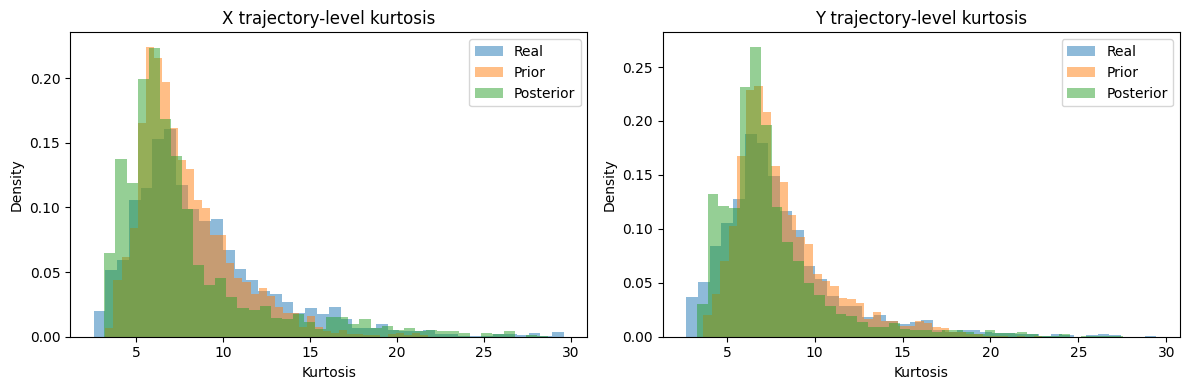

In [185]:
import matplotlib.pyplot as plt

def get_trajectory_kurtosis(data):
    dx = data[:, 1:, :] - data[:, :-1, :]
    return lm.kurtosis_torch(dx).detach().cpu().numpy()

real_k = get_trajectory_kurtosis(real)
prior_k = get_trajectory_kurtosis(generated_prior)
posterior_k = get_trajectory_kurtosis(generated_posterior)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, dim, name in zip(axes, [0, 1], ["X", "Y"]):
    ax.hist(real_k[:, dim], bins=40, alpha=0.5,
            density=True, label="Real")
    ax.hist(prior_k[:, dim], bins=40, alpha=0.5,
            density=True, label="Prior")
    ax.hist(posterior_k[:, dim], bins=40, alpha=0.5,
            density=True, label="Posterior")

    ax.set_title(f"{name} trajectory-level kurtosis")
    ax.set_xlabel("Kurtosis")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

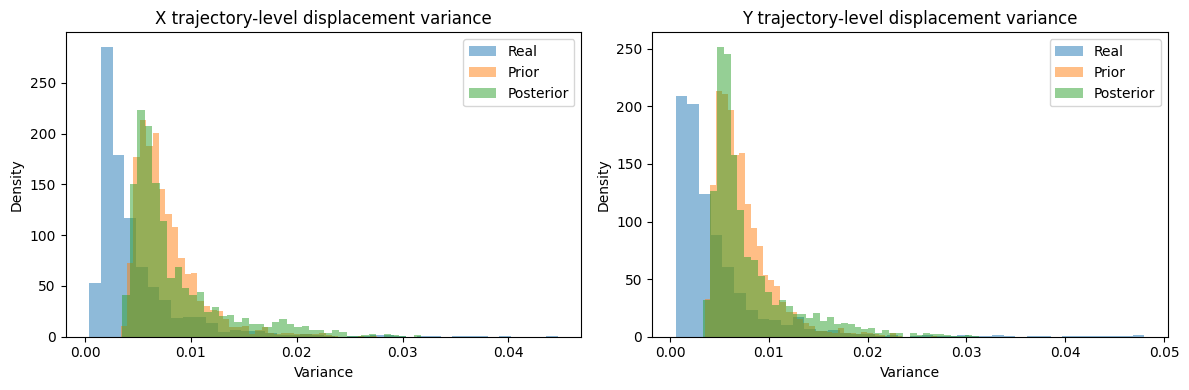

In [186]:
def get_trajectory_variance(data):
    dx = data[:, 1:, :] - data[:, :-1, :]
    return lm.variance_torch(dx).detach().cpu().numpy()

real_var = get_trajectory_variance(real)
prior_var = get_trajectory_variance(generated_prior)
posterior_var = get_trajectory_variance(generated_posterior)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, dim, name in zip(axes, [0, 1], ["X", "Y"]):
    ax.hist(real_var[:, dim], bins=40, density=True,
            alpha=0.5, label="Real")
    ax.hist(prior_var[:, dim], bins=40, density=True,
            alpha=0.5, label="Prior")
    ax.hist(posterior_var[:, dim], bins=40, density=True,
            alpha=0.5, label="Posterior")

    ax.set_title(f"{name} trajectory-level displacement variance")
    ax.set_xlabel("Variance")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

In [187]:
def print_variance_stats(name, values):
    print(f"\n{name}")

    for axis, label in enumerate(["X", "Y"]):
        v = values[:, axis]

        print(
            label,
            "mean =", np.mean(v),
            "median =", np.median(v),
            "std =", np.std(v),
            "p10 =", np.percentile(v, 10),
            "p90 =", np.percentile(v, 90)
        )

print_variance_stats("REAL", real_var)
print_variance_stats("PRIOR", prior_var)
print_variance_stats("POSTERIOR", posterior_var)


REAL
X mean = 0.0047037173 median = 0.0032306928 std = 0.0044040824 p10 = 0.0017590603 p90 = 0.009549279
Y mean = 0.004657421 median = 0.002989775 std = 0.0051933066 p10 = 0.0013035715 p90 = 0.009624921

PRIOR
X mean = 0.007711557 median = 0.006888727 std = 0.0030914575 p10 = 0.004894851 p90 = 0.011527342
Y mean = 0.007418315 median = 0.006644811 std = 0.0029658675 p10 = 0.004694769 p90 = 0.010941405

POSTERIOR
X mean = 0.008527635 median = 0.00666394 std = 0.004721226 p10 = 0.0047612987 p90 = 0.015501032
Y mean = 0.008078719 median = 0.006373252 std = 0.0043887617 p10 = 0.0046750745 p90 = 0.014450188


In [188]:
import inspect
print(inspect.getsource(lm.variance_torch))

def variance_torch(signal):
    """ Calculates the variance of displacements of given signal in PyTorch.
    
    Args:
        signal (Tensor): Input signal of shape (batch_size, length, 2).
        
    Returns:
        signal_variance (Tensor): Variance of displacements.
    """
   
    # signal = signal[:, 1:] - signal[:, :-1]  # Calculate displacements
    signal_mean = torch.mean(signal, axis=1, keepdim=True)  # Mean of displacements
    signal_centered = signal - signal_mean  # Center the displacements
    
    signal_variance = torch.mean(signal_centered ** 2, axis=1)  # Calculate variance
    return signal_variance



In [189]:
# Deterministic reconstruction on the same validation trajectories
model_pos.eval()

with torch.no_grad():
    _, mu, logvar = model_pos.encoder(real)
    reconstructed = model_pos.decoder(mu)

real_recon_var = get_trajectory_variance(reconstructed)

print_variance_stats("REAL", real_var)
print_variance_stats("RECONSTRUCTION", real_recon_var)
print_variance_stats("PRIOR", prior_var)
print_variance_stats("POSTERIOR", posterior_var)


REAL
X mean = 0.0047037173 median = 0.0032306928 std = 0.0044040824 p10 = 0.0017590603 p90 = 0.009549279
Y mean = 0.004657421 median = 0.002989775 std = 0.0051933066 p10 = 0.0013035715 p90 = 0.009624921

RECONSTRUCTION
X mean = 0.0068319296 median = 0.0057645375 std = 0.0038064646 p10 = 0.004062894 p90 = 0.010441995
Y mean = 0.006555893 median = 0.0054102745 std = 0.0035683298 p10 = 0.004047308 p90 = 0.010150837

PRIOR
X mean = 0.007711557 median = 0.006888727 std = 0.0030914575 p10 = 0.004894851 p90 = 0.011527342
Y mean = 0.007418315 median = 0.006644811 std = 0.0029658675 p10 = 0.004694769 p90 = 0.010941405

POSTERIOR
X mean = 0.008527635 median = 0.00666394 std = 0.004721226 p10 = 0.0047612987 p90 = 0.015501032
Y mean = 0.008078719 median = 0.006373252 std = 0.0043887617 p10 = 0.0046750745 p90 = 0.014450188


In [190]:
import numpy as np

# Both arrays must have the same trajectory ordering
real_v = real_var
recon_v = real_recon_var

for axis, name in enumerate(["X", "Y"]):
    r = real_v[:, axis]
    p = recon_v[:, axis]

    correlation = np.corrcoef(r, p)[0, 1]
    ratio = np.mean(p) / np.mean(r)

    print(f"\n{name} axis")
    print("Pearson correlation:", correlation)
    print("Mean variance ratio:", ratio)
    print("Mean absolute error:", np.mean(np.abs(p-r)))
    print("Variance of real:", np.var(r))
    print("Variance of reconstruction:", np.var(p))


X axis
Pearson correlation: 0.7865166905799696
Mean variance ratio: 1.4524533
Mean absolute error: 0.0028214986
Variance of real: 1.9395942e-05
Variance of reconstruction: 1.4489173e-05

Y axis
Pearson correlation: 0.7573087012962828
Mean variance ratio: 1.407623
Mean absolute error: 0.0030582356
Variance of real: 2.6970434e-05
Variance of reconstruction: 1.2732979e-05


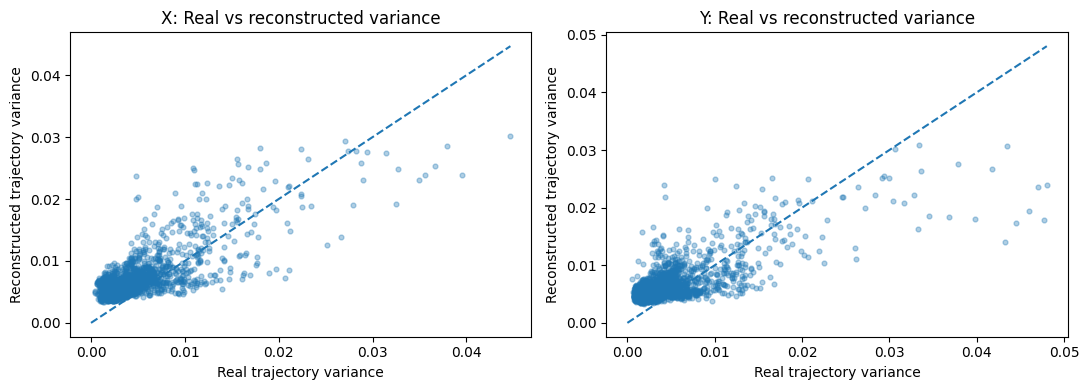

In [191]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for axis, name in enumerate(["X", "Y"]):
    axes[axis].scatter(
        real_v[:, axis],
        recon_v[:, axis],
        alpha=0.35,
        s=12
    )

    max_val = max(
        real_v[:, axis].max(),
        recon_v[:, axis].max()
    )

    axes[axis].plot(
        [0, max_val],
        [0, max_val],
        linestyle="--"
    )

    axes[axis].set_title(f"{name}: Real vs reconstructed variance")
    axes[axis].set_xlabel("Real trajectory variance")
    axes[axis].set_ylabel("Reconstructed trajectory variance")

plt.tight_layout()
plt.show()

In [192]:
import numpy as np
from scipy.stats import pearsonr, spearmanr, linregress

for axis, name in enumerate(["X", "Y"]):

    r = real_var[:, axis]
    p = real_recon_var[:, axis]

    pearson = pearsonr(r, p)
    spearman = spearmanr(r, p)
    regression = linregress(r, p)

    print(f"\n========== {name} ==========")
    print("Pearson correlation:", pearson.statistic)
    print("Spearman correlation:", spearman.statistic)
    print("Regression slope:", regression.slope)
    print("Regression intercept:", regression.intercept)
    print("R squared:", regression.rvalue ** 2)


========== X ==========
Pearson correlation: 0.7865166
Spearman correlation: 0.6658129209529101
Regression slope: 0.679789274739561
Regression intercept: 0.0036343929771002546
R squared: 0.6186085045608676

========== Y ==========
Pearson correlation: 0.7573087
Spearman correlation: 0.618906451958703
Regression slope: 0.5203480598883826
Regression intercept: 0.0041324131177888565
R squared: 0.5735164690590625


In [193]:
best_path = (
    "/kaggle/working/LEONARDO/"
    "position_ablation/best_position_ablation.pt"
)

ckpt = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

model_pos.load_state_dict(ckpt["model_state_dict"])
model_pos.eval()

print("Checkpoint:", best_path)
print("Epoch:", ckpt.get("completed_epochs"))

Checkpoint: /kaggle/working/LEONARDO/position_ablation/best_position_ablation.pt
Epoch: 14


In [194]:
import torch
import numpy as np
import os

baseline_path = (
    "/kaggle/working/LEONARDO/checkpoints/"
    "baseline_epoch9.pt"
)

ablation_path = (
    "/kaggle/working/LEONARDO/position_ablation/"
    "best_position_ablation.pt"
)

# Load original baseline
baseline_ckpt = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(baseline_ckpt["model_state_dict"])
model.to(device)
model.eval()

# Load best position ablation
ablation_ckpt = torch.load(
    ablation_path,
    map_location=device,
    weights_only=False
)

model_pos.load_state_dict(ablation_ckpt["model_state_dict"])
model_pos.to(device)
model_pos.eval()

print("Baseline epoch:", baseline_ckpt.get("completed_epochs"))
print("Ablation epoch:", ablation_ckpt.get("completed_epochs"))
print("Both models loaded successfully.")

Baseline epoch: 9
Ablation epoch: 14
Both models loaded successfully.


In [195]:
def evaluate_model(model, loader, device):

    all_real = []
    all_recon = []

    model.eval()

    with torch.no_grad():

        for batch in loader:

            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device=device, dtype=torch.float32)

            # Deterministic encoding
            _, mu, logvar = model.encoder(x)

            # Decode latent mean
            reconstructed = model.decoder(mu)

            all_real.append(x.cpu())
            all_recon.append(reconstructed.cpu())

    real = torch.cat(all_real, dim=0)
    recon = torch.cat(all_recon, dim=0)

    # Coordinate MSE
    coordinate_mse = ((real - recon) ** 2).mean().item()

    # Displacement MSE
    real_dx = real[:, 1:] - real[:, :-1]
    recon_dx = recon[:, 1:] - recon[:, :-1]

    displacement_mse = (
        (real_dx - recon_dx) ** 2
    ).mean().item()

    # Coordinate statistics
    real_coord_std = real.std(dim=(0, 1))
    recon_coord_std = recon.std(dim=(0, 1))

    # Displacement statistics
    real_disp_std = real_dx.std(dim=(0, 1))
    recon_disp_std = recon_dx.std(dim=(0, 1))

    # Trajectory-level kurtosis and variance
    real_kurt = lm.kurtosis_torch(real_dx)
    recon_kurt = lm.kurtosis_torch(recon_dx)

    real_var = lm.variance_torch(real_dx)
    recon_var = lm.variance_torch(recon_dx)

    return {
        "coordinate_mse": coordinate_mse,
        "displacement_mse": displacement_mse,

        "real_coord_std": real_coord_std.numpy(),
        "recon_coord_std": recon_coord_std.numpy(),

        "real_disp_std": real_disp_std.numpy(),
        "recon_disp_std": recon_disp_std.numpy(),

        "real_kurtosis": real_kurt.mean(dim=0).numpy(),
        "recon_kurtosis": recon_kurt.mean(dim=0).numpy(),

        "real_variance": real_var.mean(dim=0).numpy(),
        "recon_variance": recon_var.mean(dim=0).numpy(),

        "real": real.numpy(),
        "reconstructed": recon.numpy()
    }


print("Evaluating baseline...")
baseline_results = evaluate_model(model, test_loader, device)

print("Evaluating position ablation...")
ablation_results = evaluate_model(model_pos, test_loader, device)

print("\nTEST EVALUATION COMPLETED")

Evaluating baseline...
Evaluating position ablation...

TEST EVALUATION COMPLETED


In [196]:
metrics = [
    "coordinate_mse",
    "displacement_mse",
    "real_coord_std",
    "recon_coord_std",
    "real_disp_std",
    "recon_disp_std",
    "real_kurtosis",
    "recon_kurtosis",
    "real_variance",
    "recon_variance"
]

for metric in metrics:

    print(f"\n========== {metric} ==========")

    print("Baseline :", baseline_results[metric])
    print("Ablation :", ablation_results[metric])


========== coordinate_mse ==========
Baseline : 0.7304347157478333
Ablation : 0.08631099760532379

========== displacement_mse ==========
Baseline : 0.014376613311469555
Ablation : 0.012617815285921097

========== real_coord_std ==========
Baseline : [0.24578474 0.24325237]
Ablation : [0.24578474 0.24325237]

========== recon_coord_std ==========
Baseline : [0.22487031 0.21603824]
Ablation : [0.17792144 0.17830396]

========== real_disp_std ==========
Baseline : [0.07309914 0.07178684]
Ablation : [0.07309914 0.07178684]

========== recon_disp_std ==========
Baseline : [0.09475841 0.09637704]
Ablation : [0.0870805  0.08472962]

========== real_kurtosis ==========
Baseline : [6.9343686 7.5145283]
Ablation : [6.9343686 7.5145283]

========== recon_kurtosis ==========
Baseline : [6.8564467 7.212174 ]
Ablation : [6.6419864 6.875548 ]

========== real_variance ==========
Baseline : [0.00533892 0.00514725]
Ablation : [0.00533892 0.00514725]

========== recon_variance ==========
Baseline : [0

In [197]:
output_dir = "/kaggle/working/LEONARDO/final_results"
os.makedirs(output_dir, exist_ok=True)

np.savez_compressed(
    os.path.join(output_dir, "final_test_evaluation.npz"),

    real=baseline_results["real"],

    baseline_reconstruction=baseline_results["reconstructed"],

    ablation_reconstruction=ablation_results["reconstructed"]
)

print("Saved final test evaluation.")
print("Output:", output_dir)

Saved final test evaluation.
Output: /kaggle/working/LEONARDO/final_results


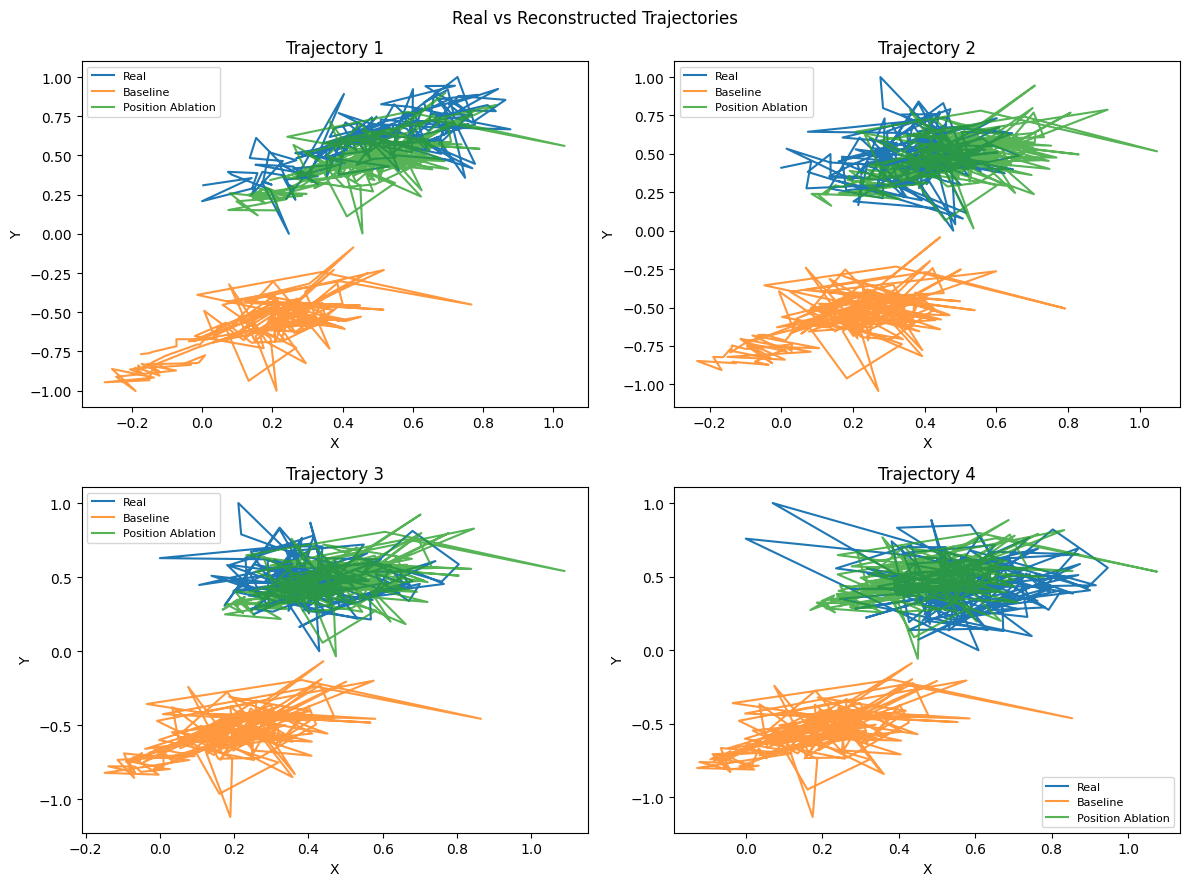

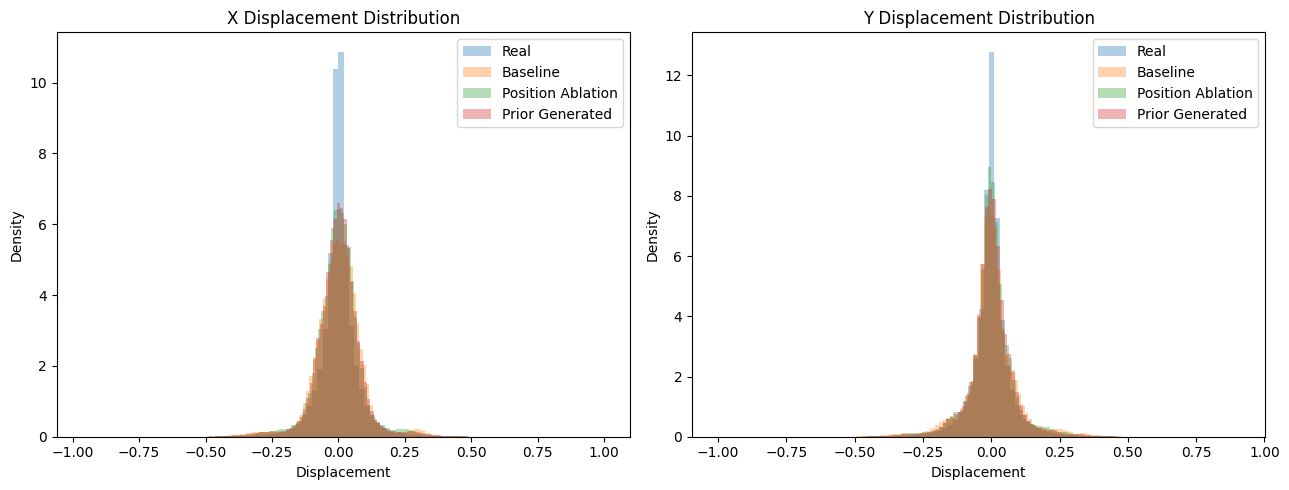

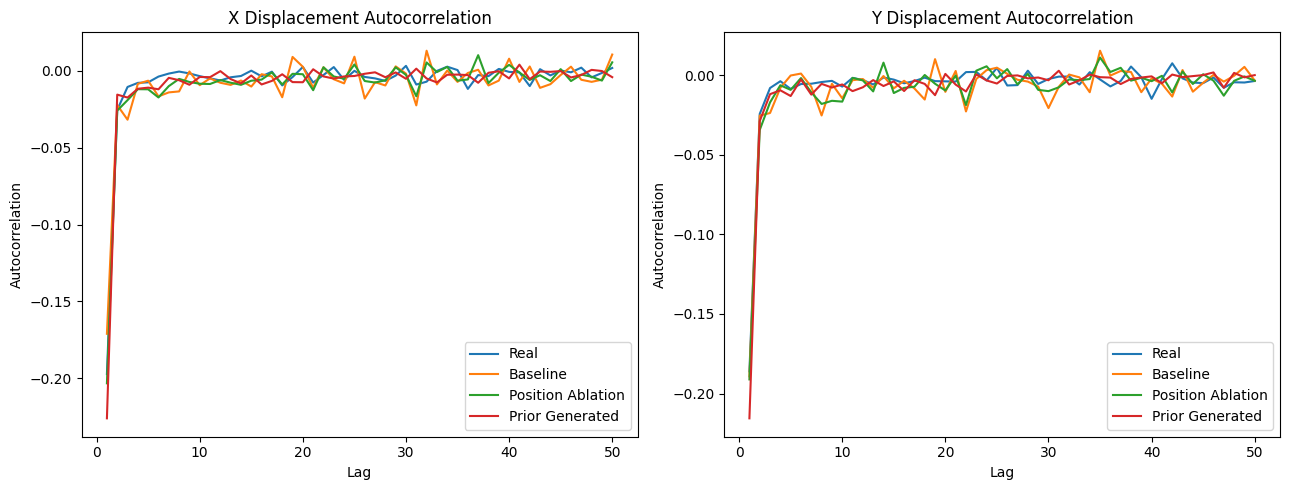

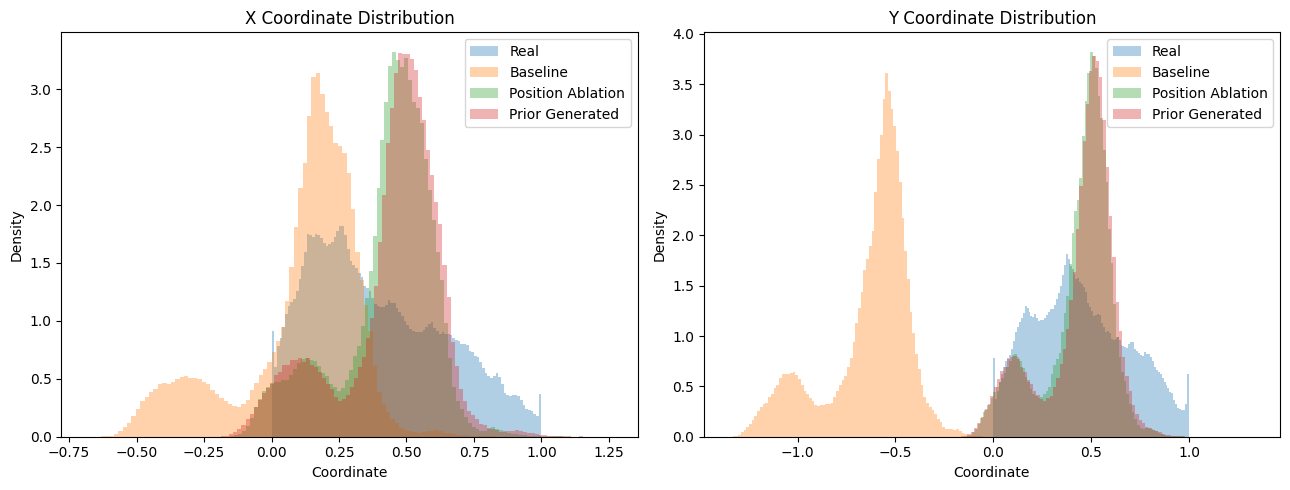


ALL FOUR FIGURES SAVED
/kaggle/working/LEONARDO/final_results
figure1_trajectories.png
figure3_autocorrelation.png
figure2_displacement.png
loss_curves.png
figure4_coordinates.png
real_vs_reconstructed_trajectories.png


In [198]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

out_dir = "/kaggle/working/LEONARDO/final_results"
os.makedirs(out_dir, exist_ok=True)

# Retrieve final test arrays
real = baseline_results["real"]
baseline_rec = baseline_results["reconstructed"]
ablation_rec = ablation_results["reconstructed"]

# Generate 1000 prior trajectories
model_pos.eval()

with torch.no_grad():
    z = torch.randn(1000, 12, device=device)
    prior_generated = model_pos.decoder(z).cpu().numpy()

# Displacements
def get_dx(data):
    return data[:, 1:, :] - data[:, :-1, :]

real_dx = get_dx(real)
baseline_dx = get_dx(baseline_rec)
ablation_dx = get_dx(ablation_rec)
prior_dx = get_dx(prior_generated)


# ==========================================
# FIGURE 1: TRAJECTORY RECONSTRUCTION
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sample_ids = [0, 1, 2, 3]

for ax, idx in zip(axes.flat, sample_ids):

    ax.plot(
        real[idx, :, 0], real[idx, :, 1],
        label="Real", linewidth=1.5
    )

    ax.plot(
        baseline_rec[idx, :, 0],
        baseline_rec[idx, :, 1],
        label="Baseline", alpha=0.8
    )

    ax.plot(
        ablation_rec[idx, :, 0],
        ablation_rec[idx, :, 1],
        label="Position Ablation", alpha=0.8
    )

    ax.set_title(f"Trajectory {idx+1}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.legend(fontsize=8)

plt.suptitle("Real vs Reconstructed Trajectories")
plt.tight_layout()
plt.savefig(f"{out_dir}/figure1_trajectories.png", dpi=300)
plt.show()


# ==========================================
# FIGURE 2: DISPLACEMENT DISTRIBUTION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

datasets = {
    "Real": real_dx,
    "Baseline": baseline_dx,
    "Position Ablation": ablation_dx,
    "Prior Generated": prior_dx
}

for axis, name in enumerate(["X", "Y"]):

    for label, data in datasets.items():

        values = data[:, :, axis].flatten()

        axes[axis].hist(
            values,
            bins=100,
            density=True,
            alpha=0.35,
            label=label
        )

    axes[axis].set_title(f"{name} Displacement Distribution")
    axes[axis].set_xlabel("Displacement")
    axes[axis].set_ylabel("Density")
    axes[axis].legend()

plt.tight_layout()
plt.savefig(f"{out_dir}/figure2_displacement.png", dpi=300)
plt.show()


# ==========================================
# FIGURE 3: AUTOCORRELATION
# ==========================================

def calculate_acf(data, max_lag=50):

    result = []

    for lag in range(1, max_lag + 1):

        a = data[:, :-lag]
        b = data[:, lag:]

        a = a - a.mean(axis=1, keepdims=True)
        b = b - b.mean(axis=1, keepdims=True)

        numerator = np.mean(a * b, axis=1)

        denominator = (
            np.sqrt(np.mean(a**2, axis=1))
            * np.sqrt(np.mean(b**2, axis=1))
        )

        acf = numerator / np.maximum(denominator, 1e-8)

        result.append(np.mean(acf))

    return np.array(result)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for axis, name in enumerate(["X", "Y"]):

    for label, data in datasets.items():

        acf = calculate_acf(data[:, :, axis])

        axes[axis].plot(
            np.arange(1, 51),
            acf,
            label=label
        )

    axes[axis].set_title(f"{name} Displacement Autocorrelation")
    axes[axis].set_xlabel("Lag")
    axes[axis].set_ylabel("Autocorrelation")
    axes[axis].legend()

plt.tight_layout()
plt.savefig(f"{out_dir}/figure3_autocorrelation.png", dpi=300)
plt.show()


# ==========================================
# FIGURE 4: COORDINATE DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

coordinate_datasets = {
    "Real": real,
    "Baseline": baseline_rec,
    "Position Ablation": ablation_rec,
    "Prior Generated": prior_generated
}

for axis, name in enumerate(["X", "Y"]):

    for label, data in coordinate_datasets.items():

        axes[axis].hist(
            data[:, :, axis].flatten(),
            bins=100,
            density=True,
            alpha=0.35,
            label=label
        )

    axes[axis].set_title(f"{name} Coordinate Distribution")
    axes[axis].set_xlabel("Coordinate")
    axes[axis].set_ylabel("Density")
    axes[axis].legend()

plt.tight_layout()
plt.savefig(f"{out_dir}/figure4_coordinates.png", dpi=300)
plt.show()


print("\nALL FOUR FIGURES SAVED")
print(out_dir)

for f in os.listdir(out_dir):
    if f.endswith(".png"):
        print(f)

In [199]:
import pandas as pd
import os

results = {
    "Metric": [
        "Coordinate MSE",
        "Displacement MSE",
        "Real X Coordinate Std",
        "Real Y Coordinate Std",
        "Reconstructed X Coordinate Std",
        "Reconstructed Y Coordinate Std",
        "Real X Displacement Std",
        "Real Y Displacement Std",
        "Reconstructed X Displacement Std",
        "Reconstructed Y Displacement Std",
        "Real X Kurtosis",
        "Real Y Kurtosis",
        "Reconstructed X Kurtosis",
        "Reconstructed Y Kurtosis",
        "Real X Variance",
        "Real Y Variance",
        "Reconstructed X Variance",
        "Reconstructed Y Variance"
    ],

    "Baseline": [
        baseline_results["coordinate_mse"],
        baseline_results["displacement_mse"],
        *baseline_results["real_coord_std"],
        *baseline_results["recon_coord_std"],
        *baseline_results["real_disp_std"],
        *baseline_results["recon_disp_std"],
        *baseline_results["real_kurtosis"],
        *baseline_results["recon_kurtosis"],
        *baseline_results["real_variance"],
        *baseline_results["recon_variance"]
    ],

    "Position_Ablation": [
        ablation_results["coordinate_mse"],
        ablation_results["displacement_mse"],
        *ablation_results["real_coord_std"],
        *ablation_results["recon_coord_std"],
        *ablation_results["real_disp_std"],
        *ablation_results["recon_disp_std"],
        *ablation_results["real_kurtosis"],
        *ablation_results["recon_kurtosis"],
        *ablation_results["real_variance"],
        *ablation_results["recon_variance"]
    ]
}

df = pd.DataFrame(results)

csv_path = (
    "/kaggle/working/LEONARDO/final_results/"
    "baseline_vs_ablation_test_results.csv"
)

df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)
display(df.round(6))

CSV saved: /kaggle/working/LEONARDO/final_results/baseline_vs_ablation_test_results.csv


,Metric,Baseline,Position_Ablation
0,Coordinate MSE,0.730435,0.086311
1,Displacement MSE,0.014377,0.012618
2,Real X Coordinate Std,0.245785,0.245785
3,Real Y Coordinate Std,0.243252,0.243252
4,Reconstructed X Coordinate Std,0.224870,0.177921
5,Reconstructed Y Coordinate Std,0.216038,0.178304
6,Real X Displacement Std,0.073099,0.073099
7,Real Y Displacement Std,0.071787,0.071787
8,Reconstructed X Displacement Std,0.094758,0.087081
9,Reconstructed Y Displacement Std,0.096377,0.084730


In [200]:
import os

root = "/kaggle/working/LEONARDO"

required_files = [
    "LEONARDO_model.py",
    "checkpoints/baseline_epoch9.pt",
    "position_ablation/best_position_ablation.pt",
    "final_results/final_test_evaluation.npz",
    "final_results/baseline_vs_ablation_test_results.csv",
    "final_results/figure1_trajectories.png",
    "final_results/figure2_displacement.png",
    "final_results/figure3_autocorrelation.png",
    "final_results/figure4_coordinates.png"
]

print("FINAL ARTIFACT AUDIT\n")

missing = []

for file in required_files:
    path = os.path.join(root, file)

    if os.path.isfile(path):
        print(f"[OK] {file} | {os.path.getsize(path)/1024:.1f} KB")
    else:
        print(f"[MISSING] {file}")
        missing.append(file)

print("\nMissing files:", missing)

FINAL ARTIFACT AUDIT

[OK] LEONARDO_model.py | 52.6 KB
[OK] checkpoints/baseline_epoch9.pt | 103387.3 KB
[OK] position_ablation/best_position_ablation.pt | 103383.5 KB
[OK] final_results/final_test_evaluation.npz | 24911.9 KB
[OK] final_results/baseline_vs_ablation_test_results.csv | 1.1 KB
[OK] final_results/figure1_trajectories.png | 1075.4 KB
[OK] final_results/figure2_displacement.png | 115.2 KB
[OK] final_results/figure3_autocorrelation.png | 324.9 KB
[OK] final_results/figure4_coordinates.png | 131.0 KB

Missing files: []
